# Efficient Neural Network Architectures for Vehicle Type Classification in Intelligent Transportation Systems

### A Content-Audited, Leakage-Aware, and Efficiency-Focused Study Using VTID2

**Module:** UFCEYQ-15-M — Artificial Neural Networks
**Assessment:** Individual Portfolio
**Dataset:** Vehicle Type Image Dataset Version 2 (VTID2)
**Framework:** PyTorch


## 1. Introduction and Context

Vehicle-type classification supports Intelligent Transportation Systems (ITS) in traffic monitoring, access control and roadside analytics. Using VTID2, this project compares neural-network architectures under leakage-controlled evaluation, focusing on predictive performance, computational efficiency and deployment trade-offs. It serves road authorities, ITS operators and traffic engineers, and relates to SDGs 9 and 11 through efficient infrastructure and data-informed mobility.

### 1.1 Aim

To compare a flattened MLP, Standard CNN, depthwise-separable Efficient CNN and Efficient CNN + SE under a leakage-controlled protocol.

### 1.2 Research Questions

**RQ1.** How does a Standard CNN compare with a flattened MLP in Macro-F1 under leakage control?

**RQ2.** How much do conventional and leakage-controlled evaluation differ in Macro-F1?

**RQ3.** Can depthwise-separable convolution reduce complexity while retaining Standard-CNN performance?

**RQ4.** Does Squeeze-and-Excitation improve the Efficient CNN's performance–efficiency trade-off?

**RQ5.** How does Grad-CAM attention to letterbox padding compare with its share of image area?

## 2. Setup, Environment and Imports

The environment is initialised once for reproducible, GPU-aware execution.


In [1]:
# ============================================================
# 2. Setup, Environment and Imports
# ============================================================

from pathlib import Path
from collections import defaultdict
import copy
import hashlib
import math
import os
import random
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# Dependency check
# ------------------------------------------------------------

def ensure_package(
    import_name,
    pip_name=None,
):
    """
    Import a required package and install it only when missing.
    """

    pip_name = (
        pip_name
        if pip_name is not None
        else import_name
    )

    try:
        __import__(
            import_name
        )

    except ImportError:

        print(
            f"Installing missing dependency: "
            f"{pip_name}"
        )

        subprocess.check_call(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                pip_name,
            ]
        )


ensure_package(
    "skimage",
    "scikit-image==0.21.0",
)

ensure_package(
    "imagehash",
    "ImageHash",
)


from skimage.metrics import (
    structural_similarity as ssim
)

import imagehash


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42


def set_global_seed(
    seed=SEED,
):
    """
    Set random seeds for Python, NumPy and PyTorch.
    """

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            seed
        )

        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_global_seed(
    SEED
)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    "vtid2_portfolio_outputs"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


CHECKPOINT_DIR = (
    OUTPUT_DIR
    / "checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Sequential result numbering
# ------------------------------------------------------------

RESULT_COUNTERS = {
    "table": 0,
    "figure": 0,
}


def show_table(
    dataframe,
    caption,
    filename=None,
    decimals=4,
):
    """
    Display and optionally save a dataframe using sequential
    table numbering.
    """

    RESULT_COUNTERS[
        "table"
    ] += 1

    table_number = (
        RESULT_COUNTERS[
            "table"
        ]
    )

    print(
        f"\nTable {table_number}. "
        f"{caption}"
    )

    display(
        dataframe.round(
            decimals
        )
    )

    if filename is not None:

        dataframe.to_csv(
            OUTPUT_DIR
            / filename,
            index=False,
        )


def show_figure(
    figure,
    caption,
    filename=None,
):
    """
    Display and optionally save a figure using sequential
    figure numbering.
    """

    RESULT_COUNTERS[
        "figure"
    ] += 1

    figure_number = (
        RESULT_COUNTERS[
            "figure"
        ]
    )

    print(
        f"\nFigure {figure_number}. "
        f"{caption}"
    )

    if filename is not None:

        figure.savefig(
            OUTPUT_DIR
            / filename,
            bbox_inches="tight",
            dpi=200,
        )

    plt.show()


# ------------------------------------------------------------
# Environment summary
# ------------------------------------------------------------

print(
    "=" * 68
)

print(
    "ENVIRONMENT SUMMARY"
)

print(
    "=" * 68
)

print(
    f"Python version : "
    f"{sys.version.split()[0]}"
)

print(
    f"PyTorch version: "
    f"{torch.__version__}"
)

print(
    f"Device         : "
    f"{DEVICE}"
)

if torch.cuda.is_available():

    print(
        f"GPU            : "
        f"{torch.cuda.get_device_name(0)}"
    )

    print(
        f"CUDA version   : "
        f"{torch.version.cuda}"
    )

print(
    f"Seed           : "
    f"{SEED}"
)

print(
    f"Output folder  : "
    f"{OUTPUT_DIR.resolve()}"
)

print(
    "=" * 68
)

ENVIRONMENT SUMMARY
Python version : 3.10.11
PyTorch version: 1.12.1+cu113
Device         : cuda
GPU            : Quadro M3000M
CUDA version   : 11.3
Seed           : 42
Output folder  : C:\Users\<user>\Downloads\vtid2_portfolio_outputs


## 3. Dataset Description and Data Quality Audit

### 3.1 Dataset Discovery, Inventory and Image Integrity

VTID2 (Boonsirisumpun, Okafor and Surinta, 2024) contains 4,356 daytime CCTV vehicle images in five classes. The data article states limitations of imbalance, single location and daytime capture, but not content redundancy. All images were discovered and decoded before modelling.

In [2]:
# ============================================================
# 3.1 Dataset Discovery, Inventory and Image Integrity
# ============================================================

# Accepted image extensions
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
}


# Canonical class names used throughout the notebook
CLASS_ALIASES = {
    "hatchback": "Hatchback",
    "other": "Other",
    "pickup": "Pickup",
    "pick-up": "Pickup",
    "seden": "Sedan",      # spelling used in the original VTID2 folder
    "sedan": "Sedan",
    "suv": "SUV",
}


EXPECTED_CLASSES = {
    "Hatchback",
    "Other",
    "Pickup",
    "Sedan",
    "SUV",
}


def normalise_class_name(
    folder_name,
):
    """
    Map an original VTID2 folder name to the canonical
    class label used throughout the analysis.
    """

    key = (
        folder_name
        .strip()
        .lower()
    )

    return CLASS_ALIASES.get(
        key
    )


def looks_like_vtid2(
    path,
):
    """
    Check whether a directory contains the expected
    VTID2 class folders.
    """

    path = Path(
        path
    )

    if not path.exists():
        return False

    if not path.is_dir():
        return False


    recognised_classes = set()


    for child in path.iterdir():

        if not child.is_dir():
            continue

        canonical_name = (
            normalise_class_name(
                child.name
            )
        )

        if canonical_name is not None:

            recognised_classes.add(
                canonical_name
            )


    return (
        recognised_classes
        == EXPECTED_CLASSES
    )


# ------------------------------------------------------------
# Resolve dataset location
# ------------------------------------------------------------

candidate_paths = []


# 1. Environment variable, if supplied
environment_path = os.environ.get(
    "VTID2_DIR"
)

if environment_path:

    candidate_paths.append(
        Path(
            environment_path
        ).expanduser()
    )


# 2. Common portable locations
candidate_paths.extend(
    [
        Path.cwd() / "VTID2",
        Path.cwd() / "data" / "VTID2",
        Path.home() / "Downloads" / "VTID2",
        Path.home() / "Documents" / "VTID2",
    ]
)


DATASET_ROOT = None


for candidate in candidate_paths:

    candidate = (
        candidate
        .expanduser()
        .resolve()
    )

    if looks_like_vtid2(
        candidate
    ):

        DATASET_ROOT = candidate
        break


if DATASET_ROOT is None:

    checked_locations = "\n".join(
        f"  - {path.expanduser()}"
        for path in candidate_paths
    )

    raise FileNotFoundError(
        "VTID2 dataset could not be located.\n"
        "Checked:\n"
        f"{checked_locations}\n\n"
        "Set the VTID2_DIR environment variable "
        "or place the dataset in one of these locations."
    )


print(
    "Dataset root:",
    DATASET_ROOT,
)


# ------------------------------------------------------------
# Identify class folders
# ------------------------------------------------------------

class_folder_map = {}


for folder in sorted(
    DATASET_ROOT.iterdir()
):

    if not folder.is_dir():
        continue

    canonical_name = (
        normalise_class_name(
            folder.name
        )
    )

    if canonical_name is not None:

        class_folder_map[
            canonical_name
        ] = folder


print(
    "\nRecognised classes:"
)

for class_name in sorted(
    class_folder_map
):

    print(
        f"  {class_name:<10} "
        f"← {class_folder_map[class_name].name}"
    )


# ------------------------------------------------------------
# Discover all image files
# ------------------------------------------------------------

discovered_rows = []


for class_name in sorted(
    class_folder_map
):

    class_folder = (
        class_folder_map[
            class_name
        ]
    )


    for image_path in sorted(
        class_folder.iterdir()
    ):

        if (
            image_path.is_file()
            and
            image_path.suffix.lower()
            in IMAGE_EXTENSIONS
        ):

            discovered_rows.append(
                {
                    "path": image_path,
                    "class_name": class_name,
                    "original_folder": class_folder.name,
                    "filename": image_path.name,
                    "extension": image_path.suffix.lower(),
                }
            )


inventory_df = pd.DataFrame(
    discovered_rows
)


if inventory_df.empty:

    raise RuntimeError(
        "No supported image files were found."
    )


# ------------------------------------------------------------
# Decode every image and record integrity metadata
# ------------------------------------------------------------

audit_rows = []


for row in inventory_df.itertuples(
    index=False
):

    image_path = Path(
        row.path
    )


    try:

        with Image.open(
            image_path
        ) as image:

            image.load()

            width, height = (
                image.size
            )

            mode = (
                image.mode
            )


        audit_rows.append(
            {
                "path": image_path,
                "class_name": row.class_name,
                "filename": row.filename,
                "extension": row.extension,
                "valid": True,
                "width": int(width),
                "height": int(height),
                "aspect_ratio": (
                    float(width)
                    / float(height)
                ),
                "mode": mode,
                "error": None,
            }
        )


    except Exception as exc:

        audit_rows.append(
            {
                "path": image_path,
                "class_name": row.class_name,
                "filename": row.filename,
                "extension": row.extension,
                "valid": False,
                "width": np.nan,
                "height": np.nan,
                "aspect_ratio": np.nan,
                "mode": None,
                "error": str(exc),
            }
        )


metadata_df = pd.DataFrame(
    audit_rows
)


valid_metadata_df = (
    metadata_df[
        metadata_df[
            "valid"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


corrupted_metadata_df = (
    metadata_df[
        ~metadata_df[
            "valid"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Dataset inventory table
# ------------------------------------------------------------

class_inventory_df = (

    valid_metadata_df
    .groupby(
        "class_name"
    )
    .size()
    .rename(
        "Images"
    )
    .reset_index()
    .rename(
        columns={
            "class_name":
                "Class"
        }
    )
)


class_inventory_df.loc[
    len(
        class_inventory_df
    )
] = [
    "Total",
    int(
        len(
            valid_metadata_df
        )
    ),
]


show_table(
    class_inventory_df,
    caption=(
        "VTID2 image inventory after decoding "
        "and canonical class-name mapping."
    ),
    filename=(
        "dataset_inventory.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Image-integrity summary
# ------------------------------------------------------------

integrity_summary_df = pd.DataFrame(
    {
        "Measure": [
            "Images discovered",
            "Successfully decoded",
            "Corrupted / unreadable",
            "Minimum width (px)",
            "Maximum width (px)",
            "Minimum height (px)",
            "Maximum height (px)",
            "Minimum aspect ratio",
            "Maximum aspect ratio",
        ],
        "Value": [
            len(metadata_df),
            len(valid_metadata_df),
            len(corrupted_metadata_df),
            int(
                valid_metadata_df[
                    "width"
                ].min()
            ),
            int(
                valid_metadata_df[
                    "width"
                ].max()
            ),
            int(
                valid_metadata_df[
                    "height"
                ].min()
            ),
            int(
                valid_metadata_df[
                    "height"
                ].max()
            ),
            float(
                valid_metadata_df[
                    "aspect_ratio"
                ].min()
            ),
            float(
                valid_metadata_df[
                    "aspect_ratio"
                ].max()
            ),
        ],
    }
)


show_table(
    integrity_summary_df,
    caption=(
        "Image integrity and spatial-range summary."
    ),
    filename=(
        "image_integrity_summary.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Colour-mode audit
# ------------------------------------------------------------

colour_mode_df = (

    valid_metadata_df
    .groupby(
        "mode"
    )
    .size()
    .rename(
        "Images"
    )
    .reset_index()
    .rename(
        columns={
            "mode":
                "Colour_Mode"
        }
    )
)


show_table(
    colour_mode_df,
    caption=(
        "Decoded image colour modes."
    ),
    filename=(
        "colour_mode_summary.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Core consistency checks
# ------------------------------------------------------------

observed_classes = set(
    valid_metadata_df[
        "class_name"
    ].unique()
)


print(
    "\n"
    + "=" * 68
)

print(
    "DATASET AUDIT CHECKS"
)

print(
    "=" * 68
)

print(
    f"Expected classes present : "
    f"{observed_classes == EXPECTED_CLASSES}"
)

print(
    f"Corrupted images         : "
    f"{len(corrupted_metadata_df)}"
)

print(
    f"All dimensions positive  : "
    f"{bool((valid_metadata_df['width'] > 0).all() and (valid_metadata_df['height'] > 0).all())}"
)

print(
    f"All aspect ratios finite : "
    f"{bool(np.isfinite(valid_metadata_df['aspect_ratio']).all())}"
)

print(
    "=" * 68
)

Dataset root: C:\Users\<user>\Downloads\VTID2

Recognised classes:
  Hatchback  ← hatchback
  Other      ← other
  Pickup     ← pickup
  SUV        ← suv
  Sedan      ← sedan

Table 1. VTID2 image inventory after decoding and canonical class-name mapping.


,Class,Images
0,Hatchback,606
1,Other,600
2,Pickup,1240
3,SUV,680
4,Sedan,1230
5,Total,4356



Table 2. Image integrity and spatial-range summary.


,Measure,Value
0,Images discovered,4356.0000
1,Successfully decoded,4356.0000
2,Corrupted / unreadable,0.0000
3,Minimum width (px),38.0000
4,Maximum width (px),2261.0000
5,Minimum height (px),93.0000
6,Maximum height (px),1527.0000
7,Minimum aspect ratio,0.3486
8,Maximum aspect ratio,2.2273



Table 3. Decoded image colour modes.


,Colour_Mode,Images
0,RGB,4356



DATASET AUDIT CHECKS
Expected classes present : True
Corrupted images         : 0
All dimensions positive  : True
All aspect ratios finite : True


### 3.2 Class Distribution and Spatial Characteristics


Table 4. Original VTID2 class distribution before duplicate removal.


,Class,Images,Percentage
0,Pickup,1240,28.47
1,Sedan,1230,28.24
2,SUV,680,15.61
3,Hatchback,606,13.91
4,Other,600,13.77



Original class imbalance ratio (largest : smallest) = 2.07 : 1

Table 5. Spatial characteristics of valid images by class.


,Class,Images,Width_Median,Width_Min,Width_Max,Height_Median,Height_Min,Height_Max,Aspect_Ratio_Median,Aspect_Ratio_Min,Aspect_Ratio_Max
0,Hatchback,606,306.0,107,1384,212.0,106,857,1.393,0.786,1.979
1,Other,600,305.5,38,959,467.0,109,836,0.607,0.349,1.586
2,Pickup,1240,314.0,113,2261,226.0,93,1527,1.414,0.868,2.129
3,SUV,680,325.0,110,1786,228.0,109,1270,1.354,0.948,1.953
4,Sedan,1230,326.0,120,1945,209.0,96,1260,1.517,0.939,2.227



Figure 1. Aspect-ratio distribution across the five vehicle classes.


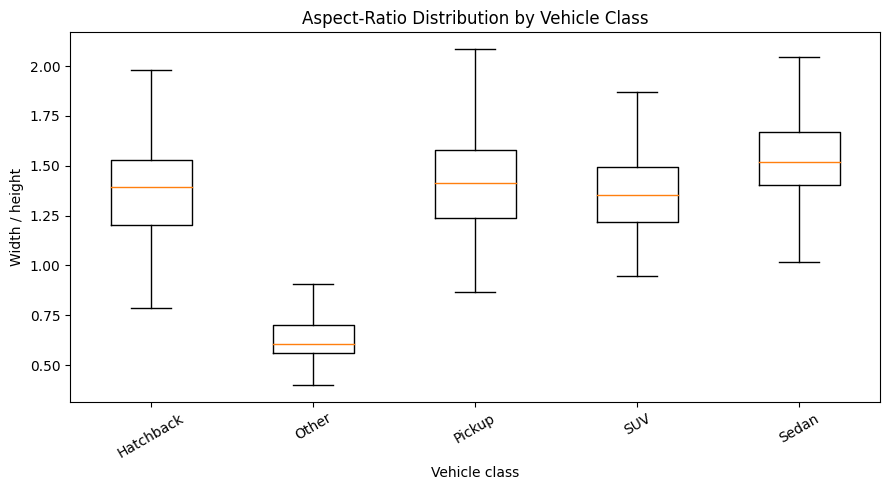


CLASS AND GEOMETRY SUMMARY
Images analysed        : 4,356
Largest class          : Pickup (1,240)
Smallest class         : Other (600)
Imbalance ratio        : 2.07 : 1


In [3]:
# ============================================================
# 3.2 Class Distribution and Spatial Characteristics
# ============================================================

# ------------------------------------------------------------
# Per-class image counts
# ------------------------------------------------------------

class_counts_df = (

    valid_metadata_df
    .groupby(
        "class_name"
    )
    .size()
    .rename(
        "Images"
    )
    .reset_index()
    .rename(
        columns={
            "class_name":
                "Class"
        }
    )
    .sort_values(
        "Images",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


largest_class_count = int(
    class_counts_df[
        "Images"
    ].max()
)

smallest_class_count = int(
    class_counts_df[
        "Images"
    ].min()
)

initial_imbalance_ratio = (
    largest_class_count
    / smallest_class_count
)


class_counts_df[
    "Percentage"
] = (
    class_counts_df[
        "Images"
    ]
    / len(
        valid_metadata_df
    )
    * 100
)


show_table(
    class_counts_df,
    caption=(
        "Original VTID2 class distribution "
        "before duplicate removal."
    ),
    filename=(
        "original_class_distribution.csv"
    ),
    decimals=2,
)


print(
    "\nOriginal class imbalance ratio "
    f"(largest : smallest) = "
    f"{initial_imbalance_ratio:.2f} : 1"
)



# ------------------------------------------------------------
# Spatial characteristics by class
# ------------------------------------------------------------

spatial_summary_df = (

    valid_metadata_df
    .groupby(
        "class_name"
    )
    .agg(
        Images=(
            "path",
            "size",
        ),
        Width_Median=(
            "width",
            "median",
        ),
        Width_Min=(
            "width",
            "min",
        ),
        Width_Max=(
            "width",
            "max",
        ),
        Height_Median=(
            "height",
            "median",
        ),
        Height_Min=(
            "height",
            "min",
        ),
        Height_Max=(
            "height",
            "max",
        ),
        Aspect_Ratio_Median=(
            "aspect_ratio",
            "median",
        ),
        Aspect_Ratio_Min=(
            "aspect_ratio",
            "min",
        ),
        Aspect_Ratio_Max=(
            "aspect_ratio",
            "max",
        ),
    )
    .reset_index()
    .rename(
        columns={
            "class_name":
                "Class"
        }
    )
)


show_table(
    spatial_summary_df,
    caption=(
        "Spatial characteristics of valid "
        "images by class."
    ),
    filename=(
        "spatial_characteristics_by_class.csv"
    ),
    decimals=3,
)


# ------------------------------------------------------------
# Aspect-ratio distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5)
)


aspect_data = [
    valid_metadata_df.loc[
        valid_metadata_df[
            "class_name"
        ] == class_name,
        "aspect_ratio",
    ].to_numpy()

    for class_name
    in sorted(
        EXPECTED_CLASSES
    )
]


ax.boxplot(
    aspect_data,
    labels=sorted(
        EXPECTED_CLASSES
    ),
    showfliers=False,
)


ax.set_xlabel(
    "Vehicle class"
)

ax.set_ylabel(
    "Width / height"
)

ax.set_title(
    "Aspect-Ratio Distribution by Vehicle Class"
)

ax.tick_params(
    axis="x",
    rotation=30,
)

fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Aspect-ratio distribution across "
        "the five vehicle classes."
    ),
    filename=(
        "aspect_ratio_distribution.png"
    ),
)


# ------------------------------------------------------------
# Key checks
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "CLASS AND GEOMETRY SUMMARY"
)

print(
    "=" * 68
)

print(
    f"Images analysed        : "
    f"{len(valid_metadata_df):,}"
)

print(
    f"Largest class          : "
    f"{class_counts_df.iloc[0]['Class']} "
    f"({int(class_counts_df.iloc[0]['Images']):,})"
)

print(
    f"Smallest class         : "
    f"{class_counts_df.iloc[-1]['Class']} "
    f"({int(class_counts_df.iloc[-1]['Images']):,})"
)

print(
    f"Imbalance ratio        : "
    f"{initial_imbalance_ratio:.2f} : 1"
)

print(
    "=" * 68
)

### 3.3 Exact Duplicate Audit

In [4]:
# ============================================================
# 3.3 Exact Duplicate Audit
# ============================================================

def decoded_rgb_sha256(image_path):
    """
    Compute SHA-256 from decoded RGB pixel content.

    Image dimensions are included in the hashed payload so that
    identical byte sequences with different spatial shapes cannot
    be treated as the same decoded image.
    """

    with Image.open(image_path) as image:

        rgb_image = image.convert(
            "RGB"
        )

        rgb_array = np.asarray(
            rgb_image,
            dtype=np.uint8,
        )

    hasher = hashlib.sha256()

    hasher.update(
        np.asarray(
            rgb_array.shape,
            dtype=np.int64,
        ).tobytes()
    )

    hasher.update(
        rgb_array.tobytes()
    )

    return hasher.hexdigest()


# ------------------------------------------------------------
# Hash every valid image
# ------------------------------------------------------------

exact_audit_df = (
    valid_metadata_df
    .copy()
    .reset_index(
        drop=True
    )
)


exact_hashes = []


for image_path in exact_audit_df[
    "path"
]:

    exact_hashes.append(
        decoded_rgb_sha256(
            image_path
        )
    )


exact_audit_df[
    "decoded_rgb_sha256"
] = exact_hashes


# ------------------------------------------------------------
# Exact-content group sizes
# ------------------------------------------------------------

exact_group_sizes = (
    exact_audit_df
    .groupby(
        "decoded_rgb_sha256"
    )
    .size()
    .rename(
        "exact_group_size"
    )
)


exact_audit_df[
    "exact_group_size"
] = (
    exact_audit_df[
        "decoded_rgb_sha256"
    ]
    .map(
        exact_group_sizes
    )
)


exact_audit_df[
    "is_exact_duplicate_member"
] = (
    exact_audit_df[
        "exact_group_size"
    ]
    > 1
)


# ------------------------------------------------------------
# Stable exact-group identifier
# ------------------------------------------------------------

unique_hashes = sorted(
    exact_audit_df[
        "decoded_rgb_sha256"
    ]
    .unique()
)


hash_to_exact_group = {
    hash_value:
        f"EXACT_{index:04d}"

    for index, hash_value
    in enumerate(
        unique_hashes,
        start=1,
    )
}


exact_audit_df[
    "exact_group_id"
] = (
    exact_audit_df[
        "decoded_rgb_sha256"
    ]
    .map(
        hash_to_exact_group
    )
)


# ------------------------------------------------------------
# Overall duplicate statistics
# ------------------------------------------------------------

total_images = len(
    exact_audit_df
)


unique_exact_contents = (
    exact_audit_df[
        "decoded_rgb_sha256"
    ]
    .nunique()
)


redundant_exact_copies = (
    total_images
    - unique_exact_contents
)


redundant_exact_percent = (
    redundant_exact_copies
    / total_images
    * 100
)


duplicate_group_sizes = (
    exact_group_sizes[
        exact_group_sizes > 1
    ]
)


exact_duplicate_group_count = len(
    duplicate_group_sizes
)


images_in_exact_duplicate_groups = int(
    duplicate_group_sizes.sum()
)


largest_exact_group = (
    int(
        duplicate_group_sizes.max()
    )
    if len(
        duplicate_group_sizes
    ) > 0
    else 1
)


# ------------------------------------------------------------
# Cross-class exact duplicate check
# ------------------------------------------------------------

exact_group_class_counts = (

    exact_audit_df
    .groupby(
        "decoded_rgb_sha256"
    )[
        "class_name"
    ]
    .nunique()
)


cross_class_exact_hashes = (
    exact_group_class_counts[
        exact_group_class_counts > 1
    ]
    .index
)


cross_class_exact_group_count = len(
    cross_class_exact_hashes
)


# ------------------------------------------------------------
# Overall exact-duplicate summary
# ------------------------------------------------------------

exact_summary_df = pd.DataFrame(
    {
        "Measure": [
            "Valid images analysed",
            "Unique decoded-RGB contents",
            "Exact duplicate groups",
            "Images in duplicate groups",
            "Redundant exact copies",
            "Redundant exact copies (%)",
            "Largest exact group",
            "Cross-class exact groups",
        ],
        "Value": [
            total_images,
            unique_exact_contents,
            exact_duplicate_group_count,
            images_in_exact_duplicate_groups,
            redundant_exact_copies,
            redundant_exact_percent,
            largest_exact_group,
            cross_class_exact_group_count,
        ],
    }
)


show_table(
    exact_summary_df,
    caption=(
        "Exact duplicate audit based on "
        "decoded RGB pixel content."
    ),
    filename=(
        "exact_duplicate_summary.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Per-class redundancy
# ------------------------------------------------------------

per_class_exact_rows = []


for class_name in sorted(
    EXPECTED_CLASSES
):

    class_df = (
        exact_audit_df[
            exact_audit_df[
                "class_name"
            ] == class_name
        ]
    )


    class_total = len(
        class_df
    )


    class_unique = (
        class_df[
            "decoded_rgb_sha256"
        ]
        .nunique()
    )


    class_redundant = (
        class_total
        - class_unique
    )


    class_redundancy_percent = (
        class_redundant
        / class_total
        * 100
    )


    per_class_exact_rows.append(
        {
            "Class": class_name,
            "Original_Images": class_total,
            "Exact_Unique_Contents": class_unique,
            "Redundant_Exact_Copies": class_redundant,
            "Redundancy_Percent": class_redundancy_percent,
        }
    )


per_class_exact_df = pd.DataFrame(
    per_class_exact_rows
)


show_table(
    per_class_exact_df,
    caption=(
        "Exact-content redundancy by vehicle class."
    ),
    filename=(
        "exact_redundancy_by_class.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Duplicate-group size distribution
# ------------------------------------------------------------

duplicate_group_distribution_df = (

    duplicate_group_sizes
    .value_counts()
    .sort_index()
    .rename_axis(
        "Group_Size"
    )
    .rename(
        "Number_of_Groups"
    )
    .reset_index()
)


show_table(
    duplicate_group_distribution_df,
    caption=(
        "Distribution of exact duplicate-group sizes."
    ),
    filename=(
        "exact_duplicate_group_size_distribution.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Construct exact-unique working set
# ------------------------------------------------------------

exact_unique_df = (

    exact_audit_df
    .sort_values(
        [
            "class_name",
            "filename",
        ]
    )
    .drop_duplicates(
        subset=[
            "decoded_rgb_sha256"
        ],
        keep="first",
    )
    .reset_index(
        drop=True
    )
)


# Preserve exact-group identity on retained representatives
exact_unique_df[
    "exact_group_size"
] = (
    exact_unique_df[
        "decoded_rgb_sha256"
    ]
    .map(
        exact_group_sizes
    )
)


# ------------------------------------------------------------
# Save audit metadata
# ------------------------------------------------------------

exact_audit_export_df = (
    exact_audit_df
    .copy()
)


exact_audit_export_df[
    "path"
] = (
    exact_audit_export_df[
        "path"
    ]
    .astype(
        str
    )
)


exact_audit_export_df.to_csv(
    OUTPUT_DIR
    / "exact_duplicate_audit_full.csv",
    index=False,
)


exact_unique_export_df = (
    exact_unique_df
    .copy()
)


exact_unique_export_df[
    "path"
] = (
    exact_unique_export_df[
        "path"
    ]
    .astype(
        str
    )
)


exact_unique_export_df.to_csv(
    OUTPUT_DIR
    / "exact_unique_images.csv",
    index=False,
)


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "EXACT DUPLICATE AUDIT CHECKS"
)

print(
    "=" * 68
)

print(
    f"Original valid images       : "
    f"{total_images:,}"
)

print(
    f"Exact-unique contents       : "
    f"{unique_exact_contents:,}"
)

print(
    f"Redundant exact copies      : "
    f"{redundant_exact_copies:,}"
)

print(
    f"Redundancy percentage       : "
    f"{redundant_exact_percent:.2f}%"
)

print(
    f"Cross-class exact groups    : "
    f"{cross_class_exact_group_count:,}"
)

print(
    f"Exact-unique working images : "
    f"{len(exact_unique_df):,}"
)

print(
    "=" * 68
)


if cross_class_exact_group_count > 0:

    print(
        "\nWARNING: Cross-class exact duplicates detected."
    )

    display(
        exact_audit_df[
            exact_audit_df[
                "decoded_rgb_sha256"
            ].isin(
                cross_class_exact_hashes
            )
        ][
            [
                "class_name",
                "filename",
                "decoded_rgb_sha256",
            ]
        ]
        .sort_values(
            "decoded_rgb_sha256"
        )
    )


Table 6. Exact duplicate audit based on decoded RGB pixel content.


,Measure,Value
0,Valid images analysed,4356.00
1,Unique decoded-RGB contents,1931.00
2,Exact duplicate groups,1310.00
3,Images in duplicate groups,3735.00
4,Redundant exact copies,2425.00
5,Redundant exact copies (%),55.67
6,Largest exact group,6.00
7,Cross-class exact groups,0.00



Table 7. Exact-content redundancy by vehicle class.


,Class,Original_Images,Exact_Unique_Contents,Redundant_Exact_Copies,Redundancy_Percent
0,Hatchback,606,203,403,66.50
1,Other,600,489,111,18.50
2,Pickup,1240,670,570,45.97
3,SUV,680,138,542,79.71
4,Sedan,1230,431,799,64.96



Table 8. Distribution of exact duplicate-group sizes.


,Group_Size,Number_of_Groups
0,2,645
1,3,369
2,4,192
3,5,54
4,6,50



EXACT DUPLICATE AUDIT CHECKS
Original valid images       : 4,356
Exact-unique contents       : 1,931
Redundant exact copies      : 2,425
Redundancy percentage       : 55.67%
Cross-class exact groups    : 0
Exact-unique working images : 1,931


### 3.4 Deduplication Decision

One representative per exact content was retained, avoiding repeated-image weighting.

In [5]:
# ============================================================
# 3.4 Deduplication Decision and Its Consequences
# ============================================================

# ------------------------------------------------------------
# Compare class distributions before and after exact deduplication
# ------------------------------------------------------------

before_dedup_counts = (
    valid_metadata_df
    .groupby("class_name")
    .size()
)

after_dedup_counts = (
    exact_unique_df
    .groupby("class_name")
    .size()
)


dedup_impact_df = pd.DataFrame(
    {
        "Class": sorted(EXPECTED_CLASSES)
    }
)


dedup_impact_df[
    "Before_Dedup"
] = (
    dedup_impact_df[
        "Class"
    ]
    .map(
        before_dedup_counts
    )
    .astype(int)
)


dedup_impact_df[
    "After_Dedup"
] = (
    dedup_impact_df[
        "Class"
    ]
    .map(
        after_dedup_counts
    )
    .astype(int)
)


dedup_impact_df[
    "Removed"
] = (
    dedup_impact_df[
        "Before_Dedup"
    ]
    -
    dedup_impact_df[
        "After_Dedup"
    ]
)


dedup_impact_df[
    "Removed_Percent"
] = (
    dedup_impact_df[
        "Removed"
    ]
    /
    dedup_impact_df[
        "Before_Dedup"
    ]
    * 100
)


# ------------------------------------------------------------
# Imbalance before and after exact deduplication
# ------------------------------------------------------------

imbalance_before_dedup = (
    dedup_impact_df[
        "Before_Dedup"
    ].max()
    /
    dedup_impact_df[
        "Before_Dedup"
    ].min()
)


imbalance_after_dedup = (
    dedup_impact_df[
        "After_Dedup"
    ].max()
    /
    dedup_impact_df[
        "After_Dedup"
    ].min()
)


show_table(
    dedup_impact_df,
    caption=(
        "Effect of exact-content deduplication "
        "on class representation."
    ),
    filename=(
        "deduplication_impact_by_class.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------

dedup_summary_df = pd.DataFrame(
    {
        "Measure": [
            "Images before exact deduplication",
            "Images after exact deduplication",
            "Images removed",
            "Imbalance ratio before deduplication",
            "Imbalance ratio after deduplication",
        ],
        "Value": [
            len(valid_metadata_df),
            len(exact_unique_df),
            len(valid_metadata_df) - len(exact_unique_df),
            imbalance_before_dedup,
            imbalance_after_dedup,
        ],
    }
)


show_table(
    dedup_summary_df,
    caption=(
        "Overall effect of exact-content "
        "deduplication."
    ),
    filename=(
        "deduplication_overall_impact.csv"
    ),
    decimals=2,
)



# ------------------------------------------------------------
# Checks
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "DEDUPLICATION IMPACT CHECKS"
)

print(
    "=" * 68
)

print(
    f"Images before deduplication : "
    f"{len(valid_metadata_df):,}"
)

print(
    f"Images after deduplication  : "
    f"{len(exact_unique_df):,}"
)

print(
    f"Images removed              : "
    f"{len(valid_metadata_df) - len(exact_unique_df):,}"
)

print(
    f"Imbalance before            : "
    f"{imbalance_before_dedup:.2f} : 1"
)

print(
    f"Imbalance after             : "
    f"{imbalance_after_dedup:.2f} : 1"
)

print(
    "=" * 68
)


Table 9. Effect of exact-content deduplication on class representation.


,Class,Before_Dedup,After_Dedup,Removed,Removed_Percent
0,Hatchback,606,203,403,66.50
1,Other,600,489,111,18.50
2,Pickup,1240,670,570,45.97
3,SUV,680,138,542,79.71
4,Sedan,1230,431,799,64.96



Table 10. Overall effect of exact-content deduplication.


,Measure,Value
0,Images before exact deduplication,4356.00
1,Images after exact deduplication,1931.00
2,Images removed,2425.00
3,Imbalance ratio before deduplication,2.07
4,Imbalance ratio after deduplication,4.86



DEDUPLICATION IMPACT CHECKS
Images before deduplication : 4,356
Images after deduplication  : 1,931
Images removed              : 2,425
Imbalance before            : 2.07 : 1
Imbalance after             : 4.86 : 1


### 3.5 Near-Duplicate Candidate Screening

Computing perceptual hashes for 1,931 exact-unique images...
Perceptual hashing completed.

Screening 1,863,415 unique image pairs...
Candidate pairs after pHash+dHash: 477

Calculating SSIM for retrieved candidates...

Table 11. Perceptual-hash near-duplicate candidate screening summary.


,Measure,Value
0,Exact-unique images screened,1931
1,Unique image pairs screened,1863415
2,pHash threshold,8
3,dHash threshold,8
4,pHash+dHash candidate pairs,477
5,Cross-class candidate pairs,1



Table 12. SSIM distribution summary for perceptual-hash candidate pairs.


,Measure,Value
0,Candidate pairs scored,477.0000
1,Minimum SSIM,0.2007
2,Median SSIM,0.7475
3,Mean SSIM,0.7349
4,Maximum SSIM,0.9999



Figure 2. SSIM scores for image pairs retrieved by the pHash+dHash candidate stage.


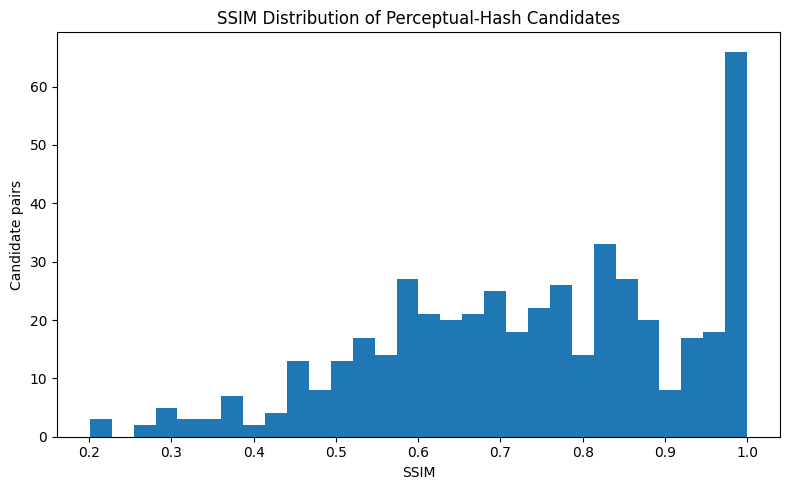


NEAR-DUPLICATE CANDIDATE SCREENING
Exact-unique images    : 1,931
All image pairs        : 1,863,415
Hash candidate pairs   : 477
Cross-class candidates : 1


In [6]:
# ============================================================
# 3.5 Near-Duplicate Candidate Screening
# ============================================================

from scipy.fftpack import dct


# ------------------------------------------------------------
# Candidate-retrieval settings
# ------------------------------------------------------------

PHASH_SIZE = 8
PHASH_HIGHFREQ_FACTOR = 4

PHASH_THRESHOLD = 8
DHASH_THRESHOLD = 8

VERIFY_SIZE = 128


# ------------------------------------------------------------
# Perceptual-hash functions
# ------------------------------------------------------------

def phash_image(
    image_path,
    hash_size=8,
    highfreq_factor=4,
):
    """
    Compute a 64-bit perceptual hash using a two-dimensional DCT.

    The hash is used only for candidate retrieval.
    """

    size = (
        hash_size
        * highfreq_factor
    )

    with Image.open(
        image_path
    ) as image:

        grayscale = (
            image
            .convert("L")
            .resize(
                (size, size),
                Image.Resampling.LANCZOS,
            )
        )

        pixels = np.asarray(
            grayscale,
            dtype=np.float32,
        )


    dct_rows = dct(
        pixels,
        axis=0,
        norm="ortho",
    )

    dct_values = dct(
        dct_rows,
        axis=1,
        norm="ortho",
    )


    low_frequency = (
        dct_values[
            :hash_size,
            :hash_size
        ]
        .copy()
    )


    median_value = np.median(
        low_frequency
        .flatten()[1:]
    )


    bits = (
        low_frequency
        > median_value
    ).flatten()


    hash_value = 0


    for bit in bits:

        hash_value = (
            hash_value << 1
        ) | int(bit)


    return hash_value


def dhash_image(
    image_path,
    hash_size=8,
):
    """
    Compute a 64-bit difference hash.
    """

    with Image.open(
        image_path
    ) as image:

        grayscale = (
            image
            .convert("L")
            .resize(
                (
                    hash_size + 1,
                    hash_size,
                ),
                Image.Resampling.LANCZOS,
            )
        )

        pixels = np.asarray(
            grayscale,
            dtype=np.int16,
        )


    differences = (
        pixels[:, 1:]
        >
        pixels[:, :-1]
    ).flatten()


    hash_value = 0


    for bit in differences:

        hash_value = (
            hash_value << 1
        ) | int(bit)


    return hash_value


def hamming_distance(
    hash_a,
    hash_b,
):
    """
    Return the Hamming distance between two integer hashes.
    """

    return int(
        (
            hash_a
            ^ hash_b
        ).bit_count()
    )


# ------------------------------------------------------------
# Aspect-ratio-preserving representation for SSIM
# ------------------------------------------------------------

def verification_image(
    image_path,
    output_size=128,
    fill=128,
):
    """
    Convert an image to grayscale and centre it on a square
    mid-grey canvas while preserving aspect ratio.

    This representation is used only for similarity verification,
    independently of the later model preprocessing pipeline.
    """

    with Image.open(
        image_path
    ) as image:

        grayscale = image.convert(
            "L"
        )

        width, height = (
            grayscale.size
        )


        scale = min(
            output_size / width,
            output_size / height,
        )


        new_width = max(
            1,
            int(
                round(
                    width
                    * scale
                )
            ),
        )

        new_height = max(
            1,
            int(
                round(
                    height
                    * scale
                )
            ),
        )


        resized = grayscale.resize(
            (
                new_width,
                new_height,
            ),
            Image.Resampling.LANCZOS,
        )


        canvas = Image.new(
            "L",
            (
                output_size,
                output_size,
            ),
            color=fill,
        )


        left = (
            output_size
            - new_width
        ) // 2

        top = (
            output_size
            - new_height
        ) // 2


        canvas.paste(
            resized,
            (
                left,
                top,
            ),
        )


    return np.asarray(
        canvas,
        dtype=np.uint8,
    )


# ------------------------------------------------------------
# Compute pHash and dHash for every exact-unique image
# ------------------------------------------------------------

print(
    "Computing perceptual hashes for "
    f"{len(exact_unique_df):,} exact-unique images..."
)


perceptual_records = []


for row in exact_unique_df.to_dict(
    "records"
):

    image_path = Path(
        row["path"]
    )


    perceptual_records.append(
        {
            "path": image_path,
            "class_name": row[
                "class_name"
            ],
            "filename": row[
                "filename"
            ],
            "aspect_ratio": row[
                "aspect_ratio"
            ],
            "phash": phash_image(
                image_path
            ),
            "dhash": dhash_image(
                image_path
            ),
        }
    )


perceptual_df = pd.DataFrame(
    perceptual_records
)


print(
    "Perceptual hashing completed."
)


# ------------------------------------------------------------
# Exhaustive all-pairs hash screening
# ------------------------------------------------------------

n_images = len(
    perceptual_df
)


total_possible_pairs = (
    n_images
    * (
        n_images - 1
    )
) // 2


print(
    f"\nScreening {total_possible_pairs:,} "
    "unique image pairs..."
)


records = (
    perceptual_df
    .to_dict(
        "records"
    )
)


candidate_records = []


for i in range(
    n_images - 1
):

    first = records[
        i
    ]


    for j in range(
        i + 1,
        n_images,
    ):

        second = records[
            j
        ]


        phash_distance = (
            hamming_distance(
                first[
                    "phash"
                ],
                second[
                    "phash"
                ],
            )
        )


        # First inexpensive similarity gate
        if (
            phash_distance
            > PHASH_THRESHOLD
        ):
            continue


        dhash_distance = (
            hamming_distance(
                first[
                    "dhash"
                ],
                second[
                    "dhash"
                ],
            )
        )


        # Both hashes must satisfy their thresholds
        if (
            dhash_distance
            > DHASH_THRESHOLD
        ):
            continue


        candidate_records.append(
            {
                "index_a": i,
                "index_b": j,
                "path_a": first[
                    "path"
                ],
                "path_b": second[
                    "path"
                ],
                "class_a": first[
                    "class_name"
                ],
                "class_b": second[
                    "class_name"
                ],
                "filename_a": first[
                    "filename"
                ],
                "filename_b": second[
                    "filename"
                ],
                "phash_distance":
                    phash_distance,
                "dhash_distance":
                    dhash_distance,
                "cross_class": (
                    first[
                        "class_name"
                    ]
                    !=
                    second[
                        "class_name"
                    ]
                ),
            }
        )


candidate_df = pd.DataFrame(
    candidate_records
)


print(
    f"Candidate pairs after pHash+dHash: "
    f"{len(candidate_df):,}"
)


# ------------------------------------------------------------
# Calculate SSIM for every retrieved candidate
# ------------------------------------------------------------

print(
    "\nCalculating SSIM for retrieved candidates..."
)


verified_records = []


for row in candidate_df.to_dict(
    "records"
):

    image_a = verification_image(
        row[
            "path_a"
        ],
        output_size=VERIFY_SIZE,
    )

    image_b = verification_image(
        row[
            "path_b"
        ],
        output_size=VERIFY_SIZE,
    )


    similarity = ssim(
        image_a,
        image_b,
        data_range=255,
    )


    verified_row = (
        row.copy()
    )

    verified_row[
        "ssim"
    ] = float(
        similarity
    )


    verified_records.append(
        verified_row
    )


verified_pairs_df = pd.DataFrame(
    verified_records
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

cross_class_candidates = (
    int(
        candidate_df[
            "cross_class"
        ].sum()
    )
    if len(
        candidate_df
    ) > 0
    else 0
)


candidate_summary_df = pd.DataFrame(
    {
        "Measure": [
            "Exact-unique images screened",
            "Unique image pairs screened",
            "pHash threshold",
            "dHash threshold",
            "pHash+dHash candidate pairs",
            "Cross-class candidate pairs",
        ],
        "Value": [
            n_images,
            total_possible_pairs,
            PHASH_THRESHOLD,
            DHASH_THRESHOLD,
            len(
                candidate_df
            ),
            cross_class_candidates,
        ],
    }
)


show_table(
    candidate_summary_df,
    caption=(
        "Perceptual-hash near-duplicate "
        "candidate screening summary."
    ),
    filename=(
        "near_duplicate_candidate_summary.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# SSIM distribution
# ------------------------------------------------------------

if len(
    verified_pairs_df
) > 0:

    ssim_summary_df = pd.DataFrame(
        {
            "Measure": [
                "Candidate pairs scored",
                "Minimum SSIM",
                "Median SSIM",
                "Mean SSIM",
                "Maximum SSIM",
            ],
            "Value": [
                len(
                    verified_pairs_df
                ),
                verified_pairs_df[
                    "ssim"
                ].min(),
                verified_pairs_df[
                    "ssim"
                ].median(),
                verified_pairs_df[
                    "ssim"
                ].mean(),
                verified_pairs_df[
                    "ssim"
                ].max(),
            ],
        }
    )


    show_table(
        ssim_summary_df,
        caption=(
            "SSIM distribution summary for "
            "perceptual-hash candidate pairs."
        ),
        filename=(
            "candidate_ssim_summary.csv"
        ),
        decimals=4,
    )


    fig, ax = plt.subplots(
        figsize=(8, 5)
    )


    ax.hist(
        verified_pairs_df[
            "ssim"
        ],
        bins=30,
    )


    ax.set_xlabel(
        "SSIM"
    )

    ax.set_ylabel(
        "Candidate pairs"
    )

    ax.set_title(
        "SSIM Distribution of Perceptual-Hash Candidates"
    )


    fig.tight_layout()


    show_figure(
        fig,
        caption=(
            "SSIM scores for image pairs retrieved "
            "by the pHash+dHash candidate stage."
        ),
        filename=(
            "candidate_ssim_distribution.png"
        ),
    )


# ------------------------------------------------------------
# Save detailed candidate results
# ------------------------------------------------------------

candidate_export_df = (
    candidate_df
    .copy()
)

verified_export_df = (
    verified_pairs_df
    .copy()
)


for dataframe in [
    candidate_export_df,
    verified_export_df,
]:

    for column in [
        "path_a",
        "path_b",
    ]:

        if column in dataframe.columns:

            dataframe[
                column
            ] = (
                dataframe[
                    column
                ]
                .astype(
                    str
                )
            )


candidate_export_df.to_csv(
    OUTPUT_DIR
    / "near_duplicate_candidates.csv",
    index=False,
)


verified_export_df.to_csv(
    OUTPUT_DIR
    / "near_duplicate_candidates_with_ssim.csv",
    index=False,
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "NEAR-DUPLICATE CANDIDATE SCREENING"
)

print(
    "=" * 68
)

print(
    f"Exact-unique images    : "
    f"{n_images:,}"
)

print(
    f"All image pairs        : "
    f"{total_possible_pairs:,}"
)

print(
    f"Hash candidate pairs   : "
    f"{len(candidate_df):,}"
)

print(
    f"Cross-class candidates : "
    f"{cross_class_candidates:,}"
)

print(
    "=" * 68
)

### 3.6 SSIM Threshold Selection and Near-Duplicate Verification

SSIM verified structural similarity (Wang et al., 2004). Sensitivity from 0.80 to 0.94 gave zero cross-class links at every threshold, demonstrating label consistency rather than threshold validity. SSIM was computed on mid-grey letterboxed canvases, so constant padding contributes near-unit local similarity and raises scores in proportion to padding area, making the threshold less strict for elongated images such as `Other`. The adopted 0.88 threshold retained 120 same-class links, but rejected pairs with pHash distance 0 fall within 0.003 SSIM of the cut, so residual leakage is possible.


Table 13. Sensitivity of candidate acceptance to the SSIM threshold.


,SSIM_Threshold,Pairs_Above_Threshold,Same_Class_Pairs,Cross_Class_Pairs
0,0.80,199,199,0
1,0.82,176,176,0
2,0.84,156,156,0
3,0.86,136,136,0
4,0.88,120,120,0
5,0.90,108,108,0
6,0.92,101,101,0
7,0.94,89,89,0



Figure 3. Number of candidate pairs retained across candidate SSIM thresholds.


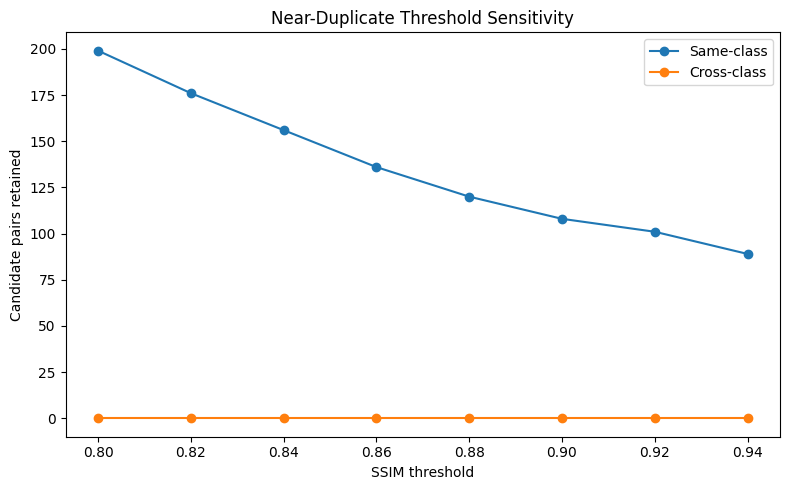


Table 14. Final SSIM operating point for near-duplicate linkage.


,Measure,Value
0,Final SSIM threshold,0.8800
1,Accepted same-class edges,120.0000
2,Accepted cross-class edges,0.0000
3,Lowest accepted same-class SSIM,0.8813
4,Highest accepted same-class SSIM,0.9999



Table 15. Candidate pairs closest to the selected SSIM operating point.


,class_a,filename_a,class_b,filename_b,phash_distance,dhash_distance,ssim,same_class
0,Pickup,PHOTO_23.jpg,Pickup,PHOTO_314.jpg,0,1,0.8787,True
1,Pickup,PHOTO_290.jpg,Pickup,PHOTO_817.jpg,0,0,0.8813,True
2,Pickup,PHOTO_297.jpg,Pickup,PHOTO_622.jpg,0,1,0.8784,True
3,Pickup,PHOTO_1052.jpg,Pickup,PHOTO_297.jpg,0,1,0.8784,True
4,Pickup,PHOTO_1195.jpg,Pickup,PHOTO_210.jpg,2,5,0.8822,True
5,Sedan,PHOTO_1133.jpg,Sedan,PHOTO_751.jpg,2,2,0.8831,True
6,Pickup,PHOTO_176.jpg,Pickup,PHOTO_477.jpg,4,2,0.8767,True
7,Hatchback,PHOTO_403.jpg,Hatchback,PHOTO_595.jpg,0,2,0.8759,True
8,Pickup,PHOTO_241.jpg,Pickup,PHOTO_932.jpg,2,0,0.8754,True
9,Hatchback,PHOTO_110.jpg,Hatchback,PHOTO_595.jpg,0,2,0.8867,True



Figure 4. Visual inspection of candidate pairs nearest the selected SSIM threshold.


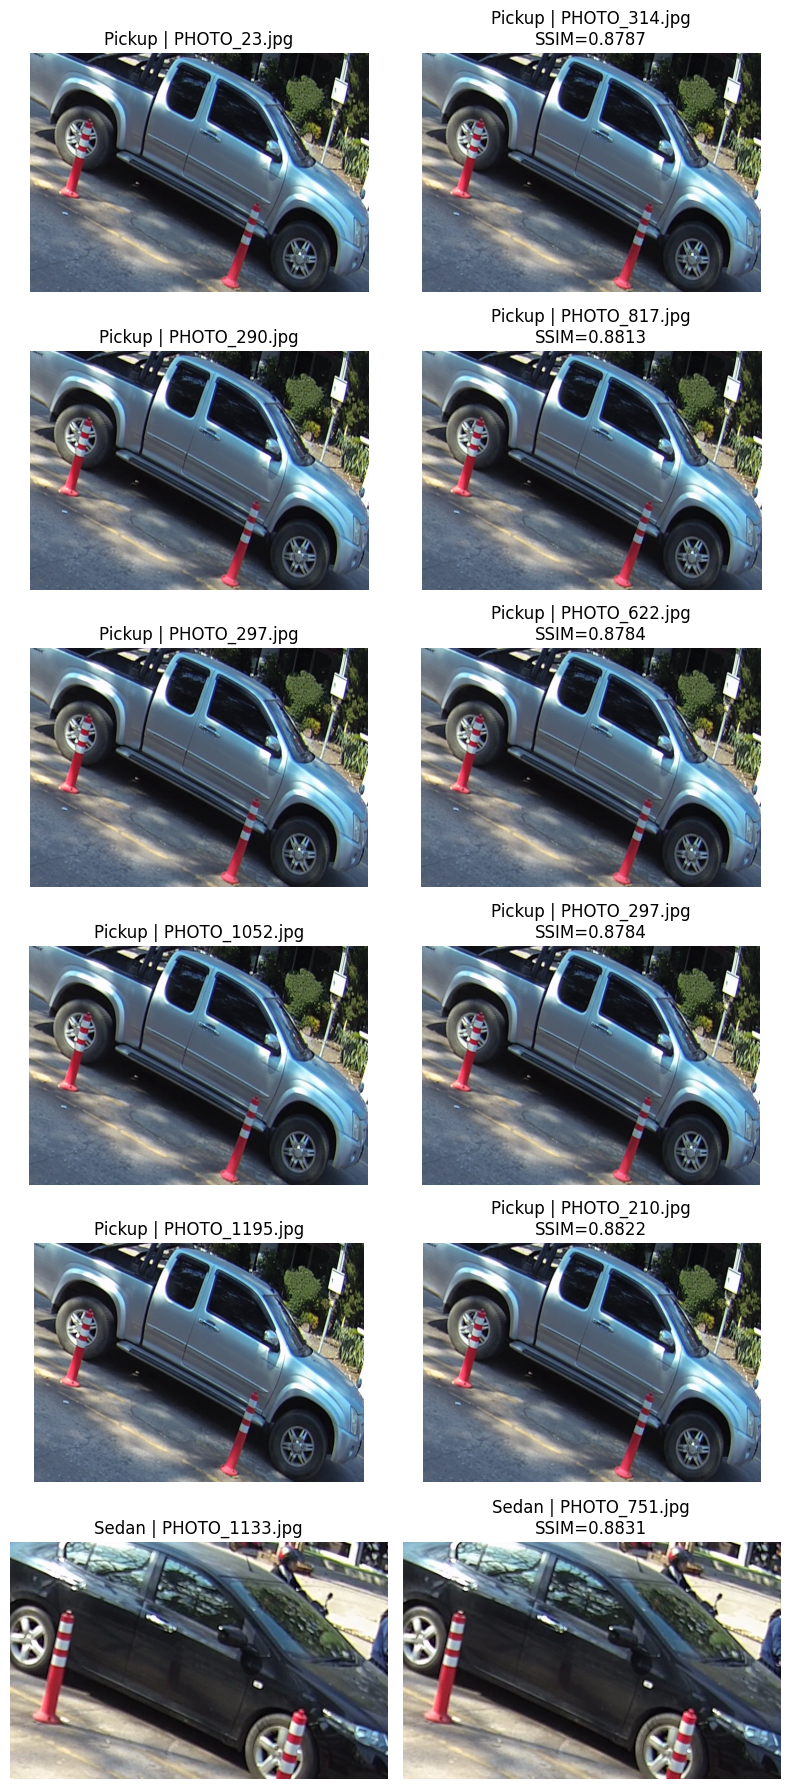


NEAR-DUPLICATE VERIFICATION CHECKS
Final SSIM threshold       : 0.88
Accepted same-class edges  : 120
Accepted cross-class edges : 0


In [7]:
# ============================================================
# 3.6 SSIM Threshold Selection and Near-Duplicate Verification
# ============================================================

if verified_pairs_df.empty:
    raise RuntimeError(
        "No candidate pairs are available for SSIM threshold analysis."
    )


# ------------------------------------------------------------
# Add explicit same-class indicator
# ------------------------------------------------------------

verified_pairs_df = (
    verified_pairs_df
    .copy()
)


verified_pairs_df[
    "same_class"
] = (
    verified_pairs_df[
        "class_a"
    ]
    ==
    verified_pairs_df[
        "class_b"
    ]
)


# ------------------------------------------------------------
# Threshold sensitivity analysis
# ------------------------------------------------------------

SSIM_THRESHOLDS = [
    0.80,
    0.82,
    0.84,
    0.86,
    0.88,
    0.90,
    0.92,
    0.94,
]


threshold_rows = []


for threshold in SSIM_THRESHOLDS:

    above_threshold = (
        verified_pairs_df[
            verified_pairs_df[
                "ssim"
            ] >= threshold
        ]
    )


    same_class_count = int(
        above_threshold[
            "same_class"
        ].sum()
    )


    cross_class_count = int(
        (
            ~above_threshold[
                "same_class"
            ]
        ).sum()
    )


    threshold_rows.append(
        {
            "SSIM_Threshold": threshold,
            "Pairs_Above_Threshold":
                len(
                    above_threshold
                ),
            "Same_Class_Pairs":
                same_class_count,
            "Cross_Class_Pairs":
                cross_class_count,
        }
    )


ssim_threshold_df = pd.DataFrame(
    threshold_rows
)


show_table(
    ssim_threshold_df,
    caption=(
        "Sensitivity of candidate acceptance "
        "to the SSIM threshold."
    ),
    filename=(
        "ssim_threshold_sensitivity.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Threshold-sensitivity figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5)
)


ax.plot(
    ssim_threshold_df[
        "SSIM_Threshold"
    ],
    ssim_threshold_df[
        "Same_Class_Pairs"
    ],
    marker="o",
    label="Same-class",
)


ax.plot(
    ssim_threshold_df[
        "SSIM_Threshold"
    ],
    ssim_threshold_df[
        "Cross_Class_Pairs"
    ],
    marker="o",
    label="Cross-class",
)


ax.set_xlabel(
    "SSIM threshold"
)

ax.set_ylabel(
    "Candidate pairs retained"
)

ax.set_title(
    "Near-Duplicate Threshold Sensitivity"
)

ax.legend()

fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Number of candidate pairs retained "
        "across candidate SSIM thresholds."
    ),
    filename=(
        "ssim_threshold_sensitivity.png"
    ),
)


# ------------------------------------------------------------
# Final threshold
# ------------------------------------------------------------

FINAL_SSIM_THRESHOLD = 0.88


accepted_candidate_df = (
    verified_pairs_df[
        verified_pairs_df[
            "ssim"
        ]
        >= FINAL_SSIM_THRESHOLD
    ]
    .copy()
    .sort_values(
        "ssim",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


accepted_same_class_df = (
    accepted_candidate_df[
        accepted_candidate_df[
            "same_class"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


accepted_cross_class_df = (
    accepted_candidate_df[
        ~accepted_candidate_df[
            "same_class"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Final operating-point summary
# ------------------------------------------------------------

final_threshold_summary_df = pd.DataFrame(
    {
        "Measure": [
            "Final SSIM threshold",
            "Accepted same-class edges",
            "Accepted cross-class edges",
            "Lowest accepted same-class SSIM",
            "Highest accepted same-class SSIM",
        ],
        "Value": [
            FINAL_SSIM_THRESHOLD,
            len(
                accepted_same_class_df
            ),
            len(
                accepted_cross_class_df
            ),
            (
                accepted_same_class_df[
                    "ssim"
                ].min()
                if len(
                    accepted_same_class_df
                ) > 0
                else np.nan
            ),
            (
                accepted_same_class_df[
                    "ssim"
                ].max()
                if len(
                    accepted_same_class_df
                ) > 0
                else np.nan
            ),
        ],
    }
)


show_table(
    final_threshold_summary_df,
    caption=(
        "Final SSIM operating point for "
        "near-duplicate linkage."
    ),
    filename=(
        "final_ssim_threshold_summary.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Borderline pairs for visual verification
# ------------------------------------------------------------

borderline_window = 0.02


borderline_pairs_df = (
    verified_pairs_df[
        (
            verified_pairs_df[
                "ssim"
            ]
            >=
            (
                FINAL_SSIM_THRESHOLD
                -
                borderline_window
            )
        )
        &
        (
            verified_pairs_df[
                "ssim"
            ]
            <=
            (
                FINAL_SSIM_THRESHOLD
                +
                borderline_window
            )
        )
    ]
    .copy()
)


borderline_pairs_df[
    "distance_from_threshold"
] = (
    (
        borderline_pairs_df[
            "ssim"
        ]
        -
        FINAL_SSIM_THRESHOLD
    )
    .abs()
)


borderline_pairs_df = (
    borderline_pairs_df
    .sort_values(
        "distance_from_threshold"
    )
    .reset_index(
        drop=True
    )
)


borderline_display_df = (
    borderline_pairs_df[
        [
            "class_a",
            "filename_a",
            "class_b",
            "filename_b",
            "phash_distance",
            "dhash_distance",
            "ssim",
            "same_class",
        ]
    ]
    .head(12)
    .copy()
)


show_table(
    borderline_display_df,
    caption=(
        "Candidate pairs closest to the "
        "selected SSIM operating point."
    ),
    filename=(
        "borderline_ssim_pairs.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Visualise the closest borderline pairs
# ------------------------------------------------------------

visual_pairs = (
    borderline_pairs_df
    .head(6)
    .copy()
)


if len(
    visual_pairs
) > 0:

    fig, axes = plt.subplots(
        nrows=len(
            visual_pairs
        ),
        ncols=2,
        figsize=(
            8,
            3 * len(
                visual_pairs
            ),
        ),
    )


    if len(
        visual_pairs
    ) == 1:

        axes = np.array(
            [axes]
        )


    for row_index, row in enumerate(
        visual_pairs.to_dict(
            "records"
        )
    ):

        for column_index, key in enumerate(
            [
                "path_a",
                "path_b",
            ]
        ):

            with Image.open(
                row[
                    key
                ]
            ) as image:

                display_image = (
                    image
                    .convert("RGB")
                    .copy()
                )


            axes[
                row_index,
                column_index
            ].imshow(
                display_image
            )


            axes[
                row_index,
                column_index
            ].axis(
                "off"
            )


        axes[
            row_index,
            0
        ].set_title(
            f"{row['class_a']} | "
            f"{row['filename_a']}"
        )


        axes[
            row_index,
            1
        ].set_title(
            f"{row['class_b']} | "
            f"{row['filename_b']}\n"
            f"SSIM={row['ssim']:.4f}"
        )


    fig.tight_layout()


    show_figure(
        fig,
        caption=(
            "Visual inspection of candidate pairs "
            "nearest the selected SSIM threshold."
        ),
        filename=(
            "borderline_ssim_pair_examples.png"
        ),
    )


# ------------------------------------------------------------
# Save accepted edges
# ------------------------------------------------------------

accepted_same_class_export_df = (
    accepted_same_class_df
    .copy()
)


for column in [
    "path_a",
    "path_b",
]:

    accepted_same_class_export_df[
        column
    ] = (
        accepted_same_class_export_df[
            column
        ]
        .astype(
            str
        )
    )


accepted_same_class_export_df.to_csv(
    OUTPUT_DIR
    / "accepted_near_duplicate_edges.csv",
    index=False,
)


# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "NEAR-DUPLICATE VERIFICATION CHECKS"
)

print(
    "=" * 68
)

print(
    f"Final SSIM threshold       : "
    f"{FINAL_SSIM_THRESHOLD:.2f}"
)

print(
    f"Accepted same-class edges  : "
    f"{len(accepted_same_class_df):,}"
)

print(
    f"Accepted cross-class edges : "
    f"{len(accepted_cross_class_df):,}"
)

print(
    "=" * 68
)


if len(
    accepted_cross_class_df
) > 0:

    print(
        "\nWARNING: Cross-class high-SSIM pairs "
        "require manual review."
    )

    display(
        accepted_cross_class_df[
            [
                "class_a",
                "filename_a",
                "class_b",
                "filename_b",
                "phash_distance",
                "dhash_distance",
                "ssim",
            ]
        ]
    )

### 3.7 Visual Groups and Leakage-Containment Groups

Connected components defined leakage-containment groups, reducing the risk that related samples span training and evaluation sets and inflate performance (Kaufman et al., 2012).

In [8]:
# ============================================================
# 3.7 Visual Groups and Leakage-Containment Groups
# ============================================================

class UnionFind:
    """
    Disjoint-set structure used to form connected components.
    """

    def __init__(self, n):
        self.parent = list(
            range(n)
        )

        self.rank = [
            0
            for _ in range(n)
        ]


    def find(self, x):

        if self.parent[x] != x:

            self.parent[x] = self.find(
                self.parent[x]
            )

        return self.parent[x]


    def union(self, a, b):

        root_a = self.find(
            a
        )

        root_b = self.find(
            b
        )


        if root_a == root_b:
            return


        if (
            self.rank[root_a]
            <
            self.rank[root_b]
        ):

            self.parent[root_a] = root_b


        elif (
            self.rank[root_a]
            >
            self.rank[root_b]
        ):

            self.parent[root_b] = root_a


        else:

            self.parent[root_b] = root_a

            self.rank[root_a] += 1


# ------------------------------------------------------------
# Working dataframe
# ------------------------------------------------------------

grouped_unique_df = (
    exact_unique_df
    .copy()
    .reset_index(
        drop=True
    )
)


n_unique = len(
    grouped_unique_df
)


if n_unique != len(
    perceptual_df
):

    raise RuntimeError(
        "Exact-unique and perceptual-analysis tables "
        "are not aligned."
    )


# ------------------------------------------------------------
# Cache SSIM values already calculated for candidate pairs
# ------------------------------------------------------------

ssim_cache = {}


for row in verified_pairs_df.itertuples(
    index=False
):

    pair_key = tuple(
        sorted(
            (
                int(
                    row.index_a
                ),
                int(
                    row.index_b
                ),
            )
        )
    )

    ssim_cache[
        pair_key
    ] = float(
        row.ssim
    )


def get_pair_ssim(
    index_a,
    index_b,
):
    """
    Return SSIM for an image pair.

    Previously scored candidate values are reused. A missing pair
    is calculated on demand only when strict-group consistency
    requires it.
    """

    if index_a == index_b:
        return 1.0


    pair_key = tuple(
        sorted(
            (
                int(
                    index_a
                ),
                int(
                    index_b
                ),
            )
        )
    )


    if pair_key not in ssim_cache:

        image_a = verification_image(
            grouped_unique_df.loc[
                pair_key[0],
                "path",
            ],
            output_size=VERIFY_SIZE,
        )

        image_b = verification_image(
            grouped_unique_df.loc[
                pair_key[1],
                "path",
            ],
            output_size=VERIFY_SIZE,
        )


        ssim_cache[
            pair_key
        ] = float(
            ssim(
                image_a,
                image_b,
                data_range=255,
            )
        )


    return ssim_cache[
        pair_key
    ]


# ------------------------------------------------------------
# 1. Leakage-containment groups
#
# Every accepted edge is unioned. Therefore, if A~B and B~C,
# all three remain in the same containment group even if
# A and C are not sufficiently similar to form one strict group.
# ------------------------------------------------------------

leakage_union = UnionFind(
    n_unique
)


for row in accepted_same_class_df.itertuples(
    index=False
):

    leakage_union.union(
        int(
            row.index_a
        ),
        int(
            row.index_b
        ),
    )


leakage_components = defaultdict(
    list
)


for index in range(
    n_unique
):

    leakage_components[
        leakage_union.find(
            index
        )
    ].append(
        index
    )


# Stable ordering for reproducible group IDs
ordered_leakage_components = sorted(
    leakage_components.values(),
    key=lambda members: min(
        members
    ),
)


leakage_group_lookup = {}


for group_number, members in enumerate(
    ordered_leakage_components,
    start=1,
):

    group_id = (
        f"LEAK_{group_number:04d}"
    )

    for index in members:

        leakage_group_lookup[
            index
        ] = group_id


grouped_unique_df[
    "leakage_group_id"
] = [
    leakage_group_lookup[
        index
    ]
    for index
    in range(
        n_unique
    )
]


# ------------------------------------------------------------
# 2. Strict visual groups
#
# Connected components are refined so that every new image must
# meet the SSIM threshold against every existing group member.
# This prevents pure transitive chaining.
# ------------------------------------------------------------

strict_groups = []

containment_components_split = 0


for component_members in ordered_leakage_components:

    component_members = sorted(
        component_members
    )


    if len(
        component_members
    ) == 1:

        strict_groups.append(
            component_members
        )

        continue


    component_strict_groups = []


    for candidate_index in component_members:

        placed = False


        for current_group in component_strict_groups:

            pairwise_consistent = all(

                get_pair_ssim(
                    candidate_index,
                    existing_index,
                )
                >=
                FINAL_SSIM_THRESHOLD

                for existing_index
                in current_group
            )


            if pairwise_consistent:

                current_group.append(
                    candidate_index
                )

                placed = True

                break


        if not placed:

            component_strict_groups.append(
                [
                    candidate_index
                ]
            )


    if len(
        component_strict_groups
    ) > 1:

        containment_components_split += 1


    strict_groups.extend(
        component_strict_groups
    )


# Stable ordering
strict_groups = sorted(
    strict_groups,
    key=lambda members: min(
        members
    ),
)


visual_group_lookup = {}


for group_number, members in enumerate(
    strict_groups,
    start=1,
):

    group_id = (
        f"VIS_{group_number:04d}"
    )

    for index in members:

        visual_group_lookup[
            index
        ] = group_id


grouped_unique_df[
    "visual_group_id"
] = [
    visual_group_lookup[
        index
    ]
    for index
    in range(
        n_unique
    )
]


# ------------------------------------------------------------
# Group sizes
# ------------------------------------------------------------

visual_group_sizes = (
    grouped_unique_df
    .groupby(
        "visual_group_id"
    )
    .size()
)


leakage_group_sizes = (
    grouped_unique_df
    .groupby(
        "leakage_group_id"
    )
    .size()
)


grouped_unique_df[
    "visual_group_size"
] = (
    grouped_unique_df[
        "visual_group_id"
    ]
    .map(
        visual_group_sizes
    )
)


grouped_unique_df[
    "leakage_group_size"
] = (
    grouped_unique_df[
        "leakage_group_id"
    ]
    .map(
        leakage_group_sizes
    )
)


# ------------------------------------------------------------
# Verify class consistency
# ------------------------------------------------------------

visual_group_class_counts = (

    grouped_unique_df
    .groupby(
        "visual_group_id"
    )[
        "class_name"
    ]
    .nunique()
)


leakage_group_class_counts = (

    grouped_unique_df
    .groupby(
        "leakage_group_id"
    )[
        "class_name"
    ]
    .nunique()
)


cross_class_visual_groups = int(
    (
        visual_group_class_counts
        > 1
    ).sum()
)


cross_class_leakage_groups = int(
    (
        leakage_group_class_counts
        > 1
    ).sum()
)


# ------------------------------------------------------------
# Critical check:
# accepted edges that would cross strict visual groups
# ------------------------------------------------------------

accepted_edge_checks = []


for row in accepted_same_class_df.itertuples(
    index=False
):

    index_a = int(
        row.index_a
    )

    index_b = int(
        row.index_b
    )


    visual_a = (
        grouped_unique_df.loc[
            index_a,
            "visual_group_id",
        ]
    )

    visual_b = (
        grouped_unique_df.loc[
            index_b,
            "visual_group_id",
        ]
    )


    leakage_a = (
        grouped_unique_df.loc[
            index_a,
            "leakage_group_id",
        ]
    )

    leakage_b = (
        grouped_unique_df.loc[
            index_b,
            "leakage_group_id",
        ]
    )


    accepted_edge_checks.append(
        {
            "index_a": index_a,
            "index_b": index_b,
            "visual_group_a":
                visual_a,
            "visual_group_b":
                visual_b,
            "same_visual_group":
                visual_a == visual_b,
            "leakage_group_a":
                leakage_a,
            "leakage_group_b":
                leakage_b,
            "same_leakage_group":
                leakage_a == leakage_b,
            "ssim":
                float(
                    row.ssim
                ),
        }
    )


accepted_edge_check_df = pd.DataFrame(
    accepted_edge_checks
)


accepted_edges_crossing_visual_groups = int(
    (
        ~accepted_edge_check_df[
            "same_visual_group"
        ]
    ).sum()
)


accepted_edges_crossing_leakage_groups = int(
    (
        ~accepted_edge_check_df[
            "same_leakage_group"
        ]
    ).sum()
)


# ------------------------------------------------------------
# Group summary table
# ------------------------------------------------------------

group_summary_df = pd.DataFrame(
    {
        "Measure": [
            "Exact-unique images",
            "Accepted near-duplicate edges",
            "Strict visual groups",
            "Strict multi-image groups",
            "Largest strict visual group",
            "Leakage-containment groups",
            "Leakage multi-image groups",
            "Largest leakage-containment group",
            "Containment components split by strict refinement",
            "Accepted edges crossing strict visual groups",
            "Accepted edges crossing leakage groups",
            "Cross-class strict visual groups",
            "Cross-class leakage groups",
        ],
        "Value": [
            n_unique,
            len(
                accepted_same_class_df
            ),
            grouped_unique_df[
                "visual_group_id"
            ].nunique(),
            int(
                (
                    visual_group_sizes
                    > 1
                ).sum()
            ),
            int(
                visual_group_sizes.max()
            ),
            grouped_unique_df[
                "leakage_group_id"
            ].nunique(),
            int(
                (
                    leakage_group_sizes
                    > 1
                ).sum()
            ),
            int(
                leakage_group_sizes.max()
            ),
            containment_components_split,
            accepted_edges_crossing_visual_groups,
            accepted_edges_crossing_leakage_groups,
            cross_class_visual_groups,
            cross_class_leakage_groups,
        ],
    }
)


show_table(
    group_summary_df,
    caption=(
        "Strict visual-group and "
        "leakage-containment summary."
    ),
    filename=(
        "visual_and_leakage_group_summary.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Leakage-group size distribution
# ------------------------------------------------------------

leakage_group_distribution_df = (

    leakage_group_sizes
    .value_counts()
    .sort_index()
    .rename_axis(
        "Group_Size"
    )
    .rename(
        "Number_of_Groups"
    )
    .reset_index()
)


show_table(
    leakage_group_distribution_df,
    caption=(
        "Distribution of leakage-containment "
        "group sizes."
    ),
    filename=(
        "leakage_group_size_distribution.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Save grouped working dataset
# ------------------------------------------------------------

grouped_unique_export_df = (
    grouped_unique_df
    .copy()
)


grouped_unique_export_df[
    "path"
] = (
    grouped_unique_export_df[
        "path"
    ]
    .astype(
        str
    )
)


grouped_unique_export_df.to_csv(
    OUTPUT_DIR
    / "exact_unique_with_visual_and_leakage_groups.csv",
    index=False,
)


accepted_edge_check_df.to_csv(
    OUTPUT_DIR
    / "accepted_edge_group_consistency.csv",
    index=False,
)


# ------------------------------------------------------------
# Hard integrity checks
# ------------------------------------------------------------

if (
    accepted_edges_crossing_leakage_groups
    != 0
):

    raise RuntimeError(
        "At least one accepted near-duplicate edge "
        "crosses leakage-containment groups."
    )


if (
    cross_class_leakage_groups
    != 0
):

    raise RuntimeError(
        "A leakage-containment group contains "
        "multiple class labels."
    )


print(
    "\n"
    + "=" * 68
)

print(
    "GROUPING INTEGRITY CHECKS"
)

print(
    "=" * 68
)

print(
    f"Strict visual groups             : "
    f"{grouped_unique_df['visual_group_id'].nunique():,}"
)

print(
    f"Leakage-containment groups       : "
    f"{grouped_unique_df['leakage_group_id'].nunique():,}"
)

print(
    f"Accepted edges crossing visual   : "
    f"{accepted_edges_crossing_visual_groups:,}"
)

print(
    f"Accepted edges crossing leakage  : "
    f"{accepted_edges_crossing_leakage_groups:,}"
)

print(
    f"Cross-class leakage groups       : "
    f"{cross_class_leakage_groups:,}"
)

print(
    "=" * 68
)


Table 16. Strict visual-group and leakage-containment summary.


,Measure,Value
0,Exact-unique images,1931
1,Accepted near-duplicate edges,120
2,Strict visual groups,1863
3,Strict multi-image groups,53
4,Largest strict visual group,7
5,Leakage-containment groups,1855
6,Leakage multi-image groups,50
7,Largest leakage-containment group,13
8,Containment components split by strict refinement,4
9,Accepted edges crossing strict visual groups,21



Table 17. Distribution of leakage-containment group sizes.


,Group_Size,Number_of_Groups
0,1,1805
1,2,43
2,3,3
3,5,2
4,8,1
5,13,1



GROUPING INTEGRITY CHECKS
Strict visual groups             : 1,863
Leakage-containment groups       : 1,855
Accepted edges crossing visual   : 21
Accepted edges crossing leakage  : 0
Cross-class leakage groups       : 0


### 3.8 Data-Quality Interpretation

Deduplication reduced 4,356 images to 1,931 unique contents (55.67% redundant). Of 1,855 leakage-containment groups, 1,805 were singletons, so near-duplicate linkage strengthened split independence rather than shrinking the dataset. Published VTID2 accuracies reach 95.61% under ten-fold cross-validation over the undeduplicated archive, where Section 4.1 measured 73.93% test contamination.

## 4. Data Preparation and Leakage-Controlled Splitting


### 4.1 Naive Image-Level Leakage Diagnostic

Repeated image-level splits quantify duplicate and leakage-group contamination.



Table 18. Naive image-level test contamination across repeated stratified splits.


,Measure,Mean,SD,Minimum,Maximum
0,Test exact leakage (%),73.93,1.65,69.42,78.59
1,Test group contamination (%),75.66,1.70,70.95,79.66



Table 19. Naive image-level leakage diagnostic at the final split seed.


,Seed,Train_Images,Validation_Images,Test_Images,Validation_Exact_Leakage_Percent,Validation_Group_Contamination_Percent,Test_Exact_Leakage_Percent,Test_Group_Contamination_Percent
0,42,3049,653,654,75.8,77.18,72.63,74.01



Figure 5. Distribution of test contamination across repeated naive image-level splits.


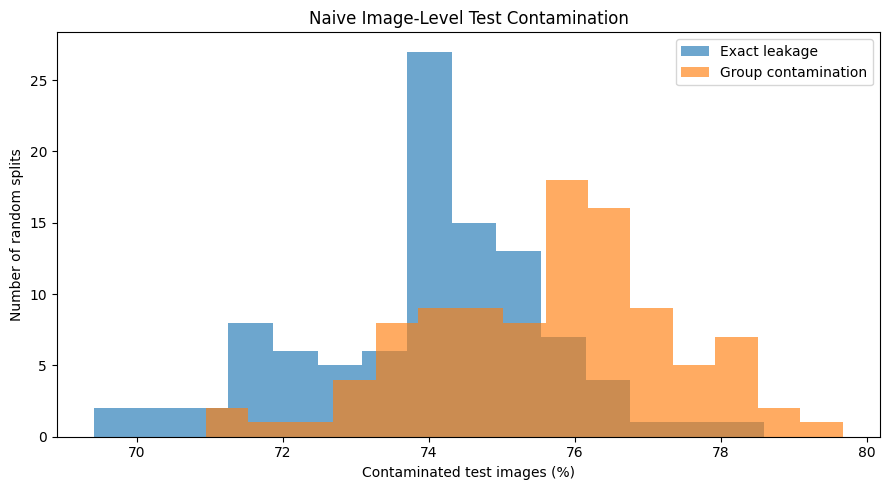


NAIVE SPLIT LEAKAGE DIAGNOSTIC
Repeated splits              : 100
Mean test exact leakage     : 73.93% ± 1.65
Mean test group contamination: 75.66% ± 1.70


In [9]:
# ============================================================
# 4.1 Naive Image-Level Leakage Diagnostic
# ============================================================

FINAL_SPLIT_SEED = SEED

TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
TEST_FRACTION = 0.15

N_DIAGNOSTIC_SPLITS = 100


# ------------------------------------------------------------
# Propagate leakage-group IDs from exact-unique representatives
# back to every image in the original archive.
# ------------------------------------------------------------

hash_to_leakage_group = (

    grouped_unique_df
    .set_index(
        "decoded_rgb_sha256"
    )[
        "leakage_group_id"
    ]
    .to_dict()
)


original_grouped_df = (
    exact_audit_df
    .copy()
    .reset_index(
        drop=True
    )
)


original_grouped_df[
    "leakage_group_id"
] = (
    original_grouped_df[
        "decoded_rgb_sha256"
    ]
    .map(
        hash_to_leakage_group
    )
)


if original_grouped_df[
    "leakage_group_id"
].isna().any():

    raise RuntimeError(
        "Some original images could not be mapped "
        "to a leakage-containment group."
    )


# ------------------------------------------------------------
# Reusable conventional image-level split
# ------------------------------------------------------------

def naive_image_split(
    dataframe,
    seed,
):
    """
    Create a stratified 70/15/15 image-level split.

    Duplicate and related-image groups are deliberately ignored.
    This function is used only for leakage diagnostics and the
    later protocol-comparison experiment.
    """

    indices = np.arange(
        len(
            dataframe
        )
    )


    labels = dataframe[
        "class_name"
    ].to_numpy()


    train_indices, temporary_indices = train_test_split(

        indices,

        test_size=(
            VALIDATION_FRACTION
            +
            TEST_FRACTION
        ),

        stratify=labels,

        random_state=seed,
    )


    temporary_labels = labels[
        temporary_indices
    ]


    test_fraction_of_temporary = (

        TEST_FRACTION
        /
        (
            VALIDATION_FRACTION
            +
            TEST_FRACTION
        )
    )


    validation_indices, test_indices = train_test_split(

        temporary_indices,

        test_size=test_fraction_of_temporary,

        stratify=temporary_labels,

        random_state=seed,
    )


    return {
        "train": np.asarray(
            train_indices
        ),
        "validation": np.asarray(
            validation_indices
        ),
        "test": np.asarray(
            test_indices
        ),
    }


# ------------------------------------------------------------
# One diagnostic run
# ------------------------------------------------------------

def measure_naive_leakage(
    dataframe,
    seed,
):
    """
    Measure contamination in the test partition relative
    to the training partition.
    """

    split_indices = naive_image_split(
        dataframe,
        seed,
    )


    train_df = dataframe.iloc[
        split_indices[
            "train"
        ]
    ]


    validation_df = dataframe.iloc[
        split_indices[
            "validation"
        ]
    ]


    test_df = dataframe.iloc[
        split_indices[
            "test"
        ]
    ]


    train_exact_hashes = set(
        train_df[
            "decoded_rgb_sha256"
        ]
    )


    train_leakage_groups = set(
        train_df[
            "leakage_group_id"
        ]
    )


    test_exact_leakage = (
        test_df[
            "decoded_rgb_sha256"
        ]
        .isin(
            train_exact_hashes
        )
    )


    test_group_contamination = (
        test_df[
            "leakage_group_id"
        ]
        .isin(
            train_leakage_groups
        )
    )


    validation_exact_leakage = (
        validation_df[
            "decoded_rgb_sha256"
        ]
        .isin(
            train_exact_hashes
        )
    )


    validation_group_contamination = (
        validation_df[
            "leakage_group_id"
        ]
        .isin(
            train_leakage_groups
        )
    )


    return {
        "Seed": int(seed),

        "Train_Images":
            len(
                train_df
            ),

        "Validation_Images":
            len(
                validation_df
            ),

        "Test_Images":
            len(
                test_df
            ),

        "Validation_Exact_Leakage_Percent":
            float(
                validation_exact_leakage.mean()
                * 100
            ),

        "Validation_Group_Contamination_Percent":
            float(
                validation_group_contamination.mean()
                * 100
            ),

        "Test_Exact_Leakage_Percent":
            float(
                test_exact_leakage.mean()
                * 100
            ),

        "Test_Group_Contamination_Percent":
            float(
                test_group_contamination.mean()
                * 100
            ),
    }


# ------------------------------------------------------------
# Repeat over 100 stratified random splits
# ------------------------------------------------------------

diagnostic_records = []


for diagnostic_seed in range(

    FINAL_SPLIT_SEED,

    FINAL_SPLIT_SEED
    +
    N_DIAGNOSTIC_SPLITS,
):

    diagnostic_records.append(

        measure_naive_leakage(
            original_grouped_df,
            diagnostic_seed,
        )
    )


naive_leakage_df = pd.DataFrame(
    diagnostic_records
)


# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------

naive_leakage_summary_df = pd.DataFrame(
    {
        "Measure": [
            "Test exact leakage (%)",
            "Test group contamination (%)",
        ],

        "Mean": [
            naive_leakage_df[
                "Test_Exact_Leakage_Percent"
            ].mean(),

            naive_leakage_df[
                "Test_Group_Contamination_Percent"
            ].mean(),
        ],

        "SD": [
            naive_leakage_df[
                "Test_Exact_Leakage_Percent"
            ].std(
                ddof=1
            ),

            naive_leakage_df[
                "Test_Group_Contamination_Percent"
            ].std(
                ddof=1
            ),
        ],

        "Minimum": [
            naive_leakage_df[
                "Test_Exact_Leakage_Percent"
            ].min(),

            naive_leakage_df[
                "Test_Group_Contamination_Percent"
            ].min(),
        ],

        "Maximum": [
            naive_leakage_df[
                "Test_Exact_Leakage_Percent"
            ].max(),

            naive_leakage_df[
                "Test_Group_Contamination_Percent"
            ].max(),
        ],
    }
)


show_table(
    naive_leakage_summary_df,
    caption=(
        "Naive image-level test contamination "
        "across repeated stratified splits."
    ),
    filename=(
        "naive_split_leakage_summary.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Final-split-seed diagnostic
# ------------------------------------------------------------

final_seed_diagnostic_df = (

    naive_leakage_df[
        naive_leakage_df[
            "Seed"
        ]
        ==
        FINAL_SPLIT_SEED
    ]
    .reset_index(
        drop=True
    )
)


show_table(
    final_seed_diagnostic_df,
    caption=(
        "Naive image-level leakage diagnostic "
        "at the final split seed."
    ),
    filename=(
        "naive_split_seed42_diagnostic.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Distribution figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5)
)


ax.hist(
    naive_leakage_df[
        "Test_Exact_Leakage_Percent"
    ],
    bins=15,
    alpha=0.65,
    label="Exact leakage",
)


ax.hist(
    naive_leakage_df[
        "Test_Group_Contamination_Percent"
    ],
    bins=15,
    alpha=0.65,
    label="Group contamination",
)


ax.set_xlabel(
    "Contaminated test images (%)"
)

ax.set_ylabel(
    "Number of random splits"
)

ax.set_title(
    "Naive Image-Level Test Contamination"
)

ax.legend()

fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Distribution of test contamination "
        "across repeated naive image-level splits."
    ),
    filename=(
        "naive_split_leakage_distribution.png"
    ),
)


# ------------------------------------------------------------
# Save full diagnostic
# ------------------------------------------------------------

naive_leakage_df.to_csv(
    OUTPUT_DIR
    / "naive_split_leakage_100_runs.csv",
    index=False,
)


# ------------------------------------------------------------
# Checks
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "NAIVE SPLIT LEAKAGE DIAGNOSTIC"
)

print(
    "=" * 68
)

print(
    f"Repeated splits              : "
    f"{len(naive_leakage_df):,}"
)

print(
    "Mean test exact leakage     : "
    f"{naive_leakage_df['Test_Exact_Leakage_Percent'].mean():.2f}% "
    f"± "
    f"{naive_leakage_df['Test_Exact_Leakage_Percent'].std(ddof=1):.2f}"
)

print(
    "Mean test group contamination: "
    f"{naive_leakage_df['Test_Group_Contamination_Percent'].mean():.2f}% "
    f"± "
    f"{naive_leakage_df['Test_Group_Contamination_Percent'].std(ddof=1):.2f}"
)

print(
    "=" * 68
)

### 4.2 Leakage-Controlled Group Split

Leakage-containment groups are assigned exclusively to one partition, so detected exact and near-duplicate relations cannot cross train, validation and test sets. Hash-retrieval recall is unmeasured, so this control covers detected groups rather than all visual similarity.

In [10]:
# ============================================================
# 4.2 Leakage-Controlled Group Split
# ============================================================

# ------------------------------------------------------------
# One record per leakage-containment group
# ------------------------------------------------------------

leakage_group_table = (

    grouped_unique_df
    .groupby(
        "leakage_group_id"
    )
    .agg(
        class_name=(
            "class_name",
            "first",
        ),
        group_size=(
            "path",
            "size",
        ),
    )
    .reset_index()
)


# Every containment group must contain one label only
group_label_counts = (

    grouped_unique_df
    .groupby(
        "leakage_group_id"
    )[
        "class_name"
    ]
    .nunique()
)


if (
    group_label_counts
    > 1
).any():

    raise RuntimeError(
        "A leakage-containment group contains "
        "more than one class label."
    )


# ------------------------------------------------------------
# Group-level 70 / 15 / 15 split
# ------------------------------------------------------------

group_ids = (
    leakage_group_table[
        "leakage_group_id"
    ]
    .to_numpy()
)


group_labels = (
    leakage_group_table[
        "class_name"
    ]
    .to_numpy()
)


temporary_fraction = (
    VALIDATION_FRACTION
    +
    TEST_FRACTION
)


train_group_ids, temporary_group_ids = train_test_split(

    group_ids,

    test_size=temporary_fraction,

    stratify=group_labels,

    random_state=FINAL_SPLIT_SEED,
)


# Labels corresponding to the temporary groups
group_label_lookup = (

    leakage_group_table
    .set_index(
        "leakage_group_id"
    )[
        "class_name"
    ]
)


temporary_labels = (

    group_label_lookup
    .loc[
        temporary_group_ids
    ]
    .to_numpy()
)


test_fraction_of_temporary = (

    TEST_FRACTION
    /
    temporary_fraction
)


validation_group_ids, test_group_ids = train_test_split(

    temporary_group_ids,

    test_size=test_fraction_of_temporary,

    stratify=temporary_labels,

    random_state=FINAL_SPLIT_SEED,
)


# ------------------------------------------------------------
# Assign partitions to every exact-unique image
# ------------------------------------------------------------

split_lookup = {
    group_id: "Train"
    for group_id
    in train_group_ids
}


split_lookup.update(
    {
        group_id: "Validation"
        for group_id
        in validation_group_ids
    }
)


split_lookup.update(
    {
        group_id: "Test"
        for group_id
        in test_group_ids
    }
)


split_df = (
    grouped_unique_df
    .copy()
)


split_df[
    "split"
] = (

    split_df[
        "leakage_group_id"
    ]
    .map(
        split_lookup
    )
)


if split_df[
    "split"
].isna().any():

    raise RuntimeError(
        "At least one image was not assigned "
        "to a dataset partition."
    )


# ------------------------------------------------------------
# Partition dataframes
# ------------------------------------------------------------

train_df = (

    split_df[
        split_df[
            "split"
        ] == "Train"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


validation_df = (

    split_df[
        split_df[
            "split"
        ] == "Validation"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


test_df = (

    split_df[
        split_df[
            "split"
        ] == "Test"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Partition summary
# ------------------------------------------------------------

partition_summary_df = pd.DataFrame(
    {
        "Partition": [
            "Train",
            "Validation",
            "Test",
            "Total",
        ],
        "Images": [
            len(
                train_df
            ),
            len(
                validation_df
            ),
            len(
                test_df
            ),
            len(
                split_df
            ),
        ],
        "Percentage": [
            len(
                train_df
            )
            / len(
                split_df
            )
            * 100,

            len(
                validation_df
            )
            / len(
                split_df
            )
            * 100,

            len(
                test_df
            )
            / len(
                split_df
            )
            * 100,

            100.0,
        ],
    }
)


show_table(
    partition_summary_df,
    caption=(
        "Leakage-controlled dataset partition sizes."
    ),
    filename=(
        "final_partition_summary.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Per-class partition counts
# ------------------------------------------------------------

partition_class_df = (

    pd.crosstab(
        split_df[
            "class_name"
        ],
        split_df[
            "split"
        ],
    )
    .reindex(
        index=sorted(
            EXPECTED_CLASSES
        ),
        columns=[
            "Train",
            "Validation",
            "Test",
        ],
        fill_value=0,
    )
    .reset_index()
    .rename(
        columns={
            "class_name":
                "Class"
        }
    )
)


show_table(
    partition_class_df,
    caption=(
        "Class distribution in the frozen "
        "leakage-controlled partitions."
    ),
    filename=(
        "final_partition_class_counts.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Training-partition imbalance
# ------------------------------------------------------------

training_class_counts = (

    train_df[
        "class_name"
    ]
    .value_counts()
)


training_imbalance_ratio = (

    training_class_counts.max()
    /
    training_class_counts.min()
)


print(
    "\nTraining-partition imbalance ratio: "
    f"{training_imbalance_ratio:.2f} : 1"
)


# ------------------------------------------------------------
# Hard partition-independence checks
# ------------------------------------------------------------

def group_set(
    dataframe,
    column,
):
    return set(
        dataframe[
            column
        ]
    )


train_leakage_groups = group_set(
    train_df,
    "leakage_group_id",
)

validation_leakage_groups = group_set(
    validation_df,
    "leakage_group_id",
)

test_leakage_groups = group_set(
    test_df,
    "leakage_group_id",
)


train_visual_groups = group_set(
    train_df,
    "visual_group_id",
)

validation_visual_groups = group_set(
    validation_df,
    "visual_group_id",
)

test_visual_groups = group_set(
    test_df,
    "visual_group_id",
)


leakage_train_validation = (
    train_leakage_groups
    &
    validation_leakage_groups
)

leakage_train_test = (
    train_leakage_groups
    &
    test_leakage_groups
)

leakage_validation_test = (
    validation_leakage_groups
    &
    test_leakage_groups
)


visual_train_validation = (
    train_visual_groups
    &
    validation_visual_groups
)

visual_train_test = (
    train_visual_groups
    &
    test_visual_groups
)

visual_validation_test = (
    validation_visual_groups
    &
    test_visual_groups
)


# Exact hashes should also be disjoint
train_exact_hashes = set(
    train_df[
        "decoded_rgb_sha256"
    ]
)

validation_exact_hashes = set(
    validation_df[
        "decoded_rgb_sha256"
    ]
)

test_exact_hashes = set(
    test_df[
        "decoded_rgb_sha256"
    ]
)


partition_check_df = pd.DataFrame(
    {
        "Check": [
            "Leakage groups: Train vs Validation",
            "Leakage groups: Train vs Test",
            "Leakage groups: Validation vs Test",
            "Visual groups: Train vs Validation",
            "Visual groups: Train vs Test",
            "Visual groups: Validation vs Test",
            "Exact contents: Train vs Validation",
            "Exact contents: Train vs Test",
            "Exact contents: Validation vs Test",
        ],
        "Crossing_Count": [
            len(
                leakage_train_validation
            ),
            len(
                leakage_train_test
            ),
            len(
                leakage_validation_test
            ),
            len(
                visual_train_validation
            ),
            len(
                visual_train_test
            ),
            len(
                visual_validation_test
            ),
            len(
                train_exact_hashes
                &
                validation_exact_hashes
            ),
            len(
                train_exact_hashes
                &
                test_exact_hashes
            ),
            len(
                validation_exact_hashes
                &
                test_exact_hashes
            ),
        ],
    }
)


show_table(
    partition_check_df,
    caption=(
        "Partition-independence verification."
    ),
    filename=(
        "partition_independence_checks.csv"
    ),
    decimals=0,
)



# ------------------------------------------------------------
# Save frozen split
# ------------------------------------------------------------

split_export_df = (
    split_df
    .copy()
)


split_export_df[
    "path"
] = (
    split_export_df[
        "path"
    ]
    .astype(
        str
    )
)


split_export_df.to_csv(
    OUTPUT_DIR
    / "vtid2_frozen_leakage_controlled_split.csv",
    index=False,
)


# ------------------------------------------------------------
# Final integrity assertions
# ------------------------------------------------------------

assert len(
    leakage_train_validation
) == 0

assert len(
    leakage_train_test
) == 0

assert len(
    leakage_validation_test
) == 0


assert (
    partition_check_df[
        "Crossing_Count"
    ] == 0
).all()


print(
    "\n"
    + "=" * 68
)

print(
    "FROZEN PARTITION CHECK"
)

print(
    "=" * 68
)

print(
    f"Train images      : "
    f"{len(train_df):,}"
)

print(
    f"Validation images : "
    f"{len(validation_df):,}"
)

print(
    f"Test images       : "
    f"{len(test_df):,}"
)

print(
    f"Total images      : "
    f"{len(split_df):,}"
)

print(
    f"Training imbalance: "
    f"{training_imbalance_ratio:.2f} : 1"
)

print(
    "Groups crossing partitions: "
    f"{int(partition_check_df['Crossing_Count'].sum())}"
)

print(
    "=" * 68
)


Table 20. Leakage-controlled dataset partition sizes.


,Partition,Images,Percentage
0,Train,1344,69.60
1,Validation,288,14.91
2,Test,299,15.48
3,Total,1931,100.00



Table 21. Class distribution in the frozen leakage-controlled partitions.


split,Class,Train,Validation,Test
0,Hatchback,139,31,33
1,Other,342,74,73
2,Pickup,462,98,110
3,SUV,98,20,20
4,Sedan,303,65,63



Training-partition imbalance ratio: 4.71 : 1

Table 22. Partition-independence verification.


,Check,Crossing_Count
0,Leakage groups: Train vs Validation,0
1,Leakage groups: Train vs Test,0
2,Leakage groups: Validation vs Test,0
3,Visual groups: Train vs Validation,0
4,Visual groups: Train vs Test,0
5,Visual groups: Validation vs Test,0
6,Exact contents: Train vs Validation,0
7,Exact contents: Train vs Test,0
8,Exact contents: Validation vs Test,0



FROZEN PARTITION CHECK
Train images      : 1,344
Validation images : 288
Test images       : 299
Total images      : 1,931
Training imbalance: 4.71 : 1
Groups crossing partitions: 0


### 4.3 Input Resolution Selection

Input size is selected from training data using enlargement requirements under aspect-ratio-preserving resizing.

In [11]:
# ============================================================
# 4.3 Input Resolution Selection
# ============================================================

CANDIDATE_INPUT_SIZES = [
    64,
    96,
    128,
    224,
]


# ------------------------------------------------------------
# Analyse resize behaviour using training images only
# ------------------------------------------------------------

resolution_rows = []


for candidate_size in CANDIDATE_INPUT_SIZES:

    widths = (
        train_df[
            "width"
        ]
        .to_numpy(
            dtype=np.float64
        )
    )

    heights = (
        train_df[
            "height"
        ]
        .to_numpy(
            dtype=np.float64
        )
    )


    # Aspect-ratio-preserving scale factor used to fit
    # the entire image inside a square canvas.
    scale_factors = np.minimum(
        candidate_size
        / widths,
        candidate_size
        / heights,
    )


    requires_upscaling = (
        scale_factors
        > 1.0
    )


    upscaled_images = int(
        requires_upscaling.sum()
    )


    upscaled_percent = float(
        requires_upscaling.mean()
        * 100
    )


    median_scale_factor = float(
        np.median(
            scale_factors
        )
    )


    resolution_rows.append(
        {
            "Input_Size":
                f"{candidate_size}×{candidate_size}",

            "Pixels_Per_Image":
                candidate_size
                * candidate_size,

            "Upscaled_Training_Images":
                upscaled_images,

            "Upscaled_Training_Percent":
                upscaled_percent,

            "Median_Resize_Scale":
                median_scale_factor,
        }
    )


resolution_analysis_df = pd.DataFrame(
    resolution_rows
)


show_table(
    resolution_analysis_df,
    caption=(
        "Training-only evidence for candidate "
        "input resolutions."
    ),
    filename=(
        "input_resolution_analysis.csv"
    ),
    decimals=4,
)



# ------------------------------------------------------------
# Freeze selected input size
# ------------------------------------------------------------

TARGET_SIZE = 96


selected_resolution_row = (

    resolution_analysis_df[
        resolution_analysis_df[
            "Input_Size"
        ]
        ==
        f"{TARGET_SIZE}×{TARGET_SIZE}"
    ]
    .copy()
)


show_table(
    selected_resolution_row,
    caption=(
        "Selected input resolution."
    ),
    filename=(
        "selected_input_resolution.csv"
    ),
    decimals=4,
)


print(
    "\n"
    + "=" * 68
)

print(
    "INPUT RESOLUTION SELECTION"
)

print(
    "=" * 68
)

print(
    f"Training images analysed : "
    f"{len(train_df):,}"
)

print(
    f"Selected input size      : "
    f"{TARGET_SIZE} × {TARGET_SIZE}"
)

print(
    "Training images requiring "
    "upscaling at selected size: "
    f"{int(selected_resolution_row.iloc[0]['Upscaled_Training_Images']):,}"
)

print(
    "Upscaling percentage    : "
    f"{float(selected_resolution_row.iloc[0]['Upscaled_Training_Percent']):.2f}%"
)

print(
    "=" * 68
)


Table 23. Training-only evidence for candidate input resolutions.


,Input_Size,Pixels_Per_Image,Upscaled_Training_Images,Upscaled_Training_Percent,Median_Resize_Scale
0,64×64,4096,0,0.0000,0.1758
1,96×96,9216,0,0.0000,0.2637
2,128×128,16384,30,2.2321,0.3516
3,224×224,50176,183,13.6161,0.6154



Table 24. Selected input resolution.


,Input_Size,Pixels_Per_Image,Upscaled_Training_Images,Upscaled_Training_Percent,Median_Resize_Scale
1,96×96,9216,0,0.0,0.2637



INPUT RESOLUTION SELECTION
Training images analysed : 1,344
Selected input size      : 96 × 96
Training images requiring upscaling at selected size: 0
Upscaling percentage    : 0.00%


### 4.4 Neutral Letterbox Preprocessing

Aspect ratio is preserved using resizing and training-derived neutral padding; padding masks are retained for later Grad-CAM analysis.


Table 25. Training-only per-image RGB statistics used to define neutral letterbox padding.


,Channel,Mean_of_Per_Image_RGB_Means,Neutral_Padding_Value
0,Red,95.58,96
1,Green,96.28,96
2,Blue,98.38,98



Figure 6. Examples of aspect-ratio-preserving neutral letterbox preprocessing.


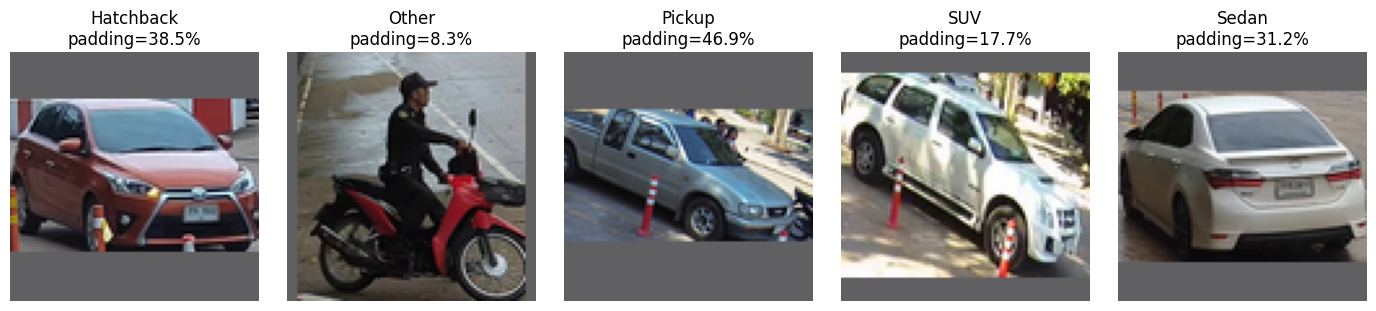


NEUTRAL LETTERBOX CHECK
Training image-weighted RGB mean : [95.58, 96.28, 98.38]
Neutral padding RGB             : (96, 96, 98)
Resize interpolation            : LANCZOS
Output size                     : 96 × 96
Padding-mask values             : [0, 1]


In [12]:
# ============================================================
# 4.4 Neutral Letterbox Preprocessing
# ============================================================

# ------------------------------------------------------------
# Training-only RGB statistics for neutral padding
#
# Each training image contributes equally:
# 1. compute the mean RGB of each image;
# 2. average those per-image means.
#
# This prevents high-resolution images from receiving greater
# influence simply because they contain more pixels.
# ------------------------------------------------------------

per_image_rgb_means = []


for image_path in train_df["path"]:

    with Image.open(image_path) as image:

        rgb_array = np.asarray(
            image.convert("RGB"),
            dtype=np.float64,
        )

    per_image_rgb_means.append(
        rgb_array.mean(
            axis=(0, 1)
        )
    )


TRAIN_RAW_RGB_MEAN = (
    np.vstack(
        per_image_rgb_means
    )
    .mean(
        axis=0
    )
)


PADDING_RGB = tuple(
    int(
        round(value)
    )
    for value
    in TRAIN_RAW_RGB_MEAN
)


# ------------------------------------------------------------
# Display training-only padding statistics
# ------------------------------------------------------------

padding_statistics_df = pd.DataFrame(
    {
        "Channel": [
            "Red",
            "Green",
            "Blue",
        ],

        "Mean_of_Per_Image_RGB_Means":
            TRAIN_RAW_RGB_MEAN,

        "Neutral_Padding_Value":
            PADDING_RGB,
    }
)


show_table(
    padding_statistics_df,
    caption=(
        "Training-only per-image RGB statistics "
        "used to define neutral letterbox padding."
    ),
    filename=(
        "neutral_padding_statistics.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Neutral letterbox transform
# ------------------------------------------------------------

class NeutralLetterboxResize:
    """
    Resize an RGB image while preserving aspect ratio and centre
    it on a fixed-size canvas with neutral constant padding.

    Padding mask:
        1 = padding
        0 = image content
    """

    def __init__(
        self,
        size,
        fill_rgb,
    ):

        self.size = int(size)

        self.fill_rgb = tuple(
            int(value)
            for value
            in fill_rgb
        )


    def _resize_geometry(
        self,
        image,
    ):

        width, height = image.size


        scale = min(
            self.size / width,
            self.size / height,
        )


        new_width = max(
            1,
            int(
                round(
                    width * scale
                )
            ),
        )


        new_height = max(
            1,
            int(
                round(
                    height * scale
                )
            ),
        )


        left = (
            self.size
            - new_width
        ) // 2


        top = (
            self.size
            - new_height
        ) // 2


        return (
            new_width,
            new_height,
            left,
            top,
        )


    def apply_with_mask(
        self,
        image,
    ):

        image = image.convert(
            "RGB"
        )


        (
            new_width,
            new_height,
            left,
            top,
        ) = self._resize_geometry(
            image
        )


        # Final frozen interpolation method
        resized = image.resize(
            (
                new_width,
                new_height,
            ),
            Image.Resampling.LANCZOS,
        )


        canvas = Image.new(
            "RGB",
            (
                self.size,
                self.size,
            ),
            color=self.fill_rgb,
        )


        canvas.paste(
            resized,
            (
                left,
                top,
            ),
        )


        padding_mask = np.ones(
            (
                self.size,
                self.size,
            ),
            dtype=np.uint8,
        )


        padding_mask[
            top:
            top + new_height,

            left:
            left + new_width,
        ] = 0


        return (
            canvas,
            padding_mask,
        )


    def __call__(
        self,
        image,
    ):

        canvas, _ = self.apply_with_mask(
            image
        )

        return canvas


# ------------------------------------------------------------
# Freeze final preprocessing transform
# ------------------------------------------------------------

LETTERBOX = NeutralLetterboxResize(
    size=TARGET_SIZE,
    fill_rgb=PADDING_RGB,
)


# ------------------------------------------------------------
# Visual verification:
# one training example per class
# ------------------------------------------------------------

preview_rows = []


for class_name in sorted(
    EXPECTED_CLASSES
):

    sample_row = (
        train_df[
            train_df[
                "class_name"
            ] == class_name
        ]
        .iloc[0]
    )


    with Image.open(
        sample_row["path"]
    ) as image:

        processed_image, padding_mask = (
            LETTERBOX.apply_with_mask(
                image
            )
        )


    padding_percent = float(
        padding_mask.mean()
        * 100
    )


    preview_rows.append(
        {
            "Class":
                class_name,

            "Image":
                processed_image,

            "Padding_Percent":
                padding_percent,
        }
    )


fig, axes = plt.subplots(
    1,
    len(preview_rows),
    figsize=(14, 3),
)


for axis, preview in zip(
    axes,
    preview_rows,
):

    axis.imshow(
        preview["Image"]
    )


    axis.set_title(
        f"{preview['Class']}\n"
        f"padding={preview['Padding_Percent']:.1f}%"
    )


    axis.axis(
        "off"
    )


fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Examples of aspect-ratio-preserving "
        "neutral letterbox preprocessing."
    ),
    filename=(
        "neutral_letterbox_examples.png"
    ),
)


# ------------------------------------------------------------
# Transform integrity checks
# ------------------------------------------------------------

test_sample_path = (
    train_df.iloc[0]["path"]
)


with Image.open(
    test_sample_path
) as image:

    test_letterbox, test_padding_mask = (
        LETTERBOX.apply_with_mask(
            image
        )
    )


assert (
    test_letterbox.size
    ==
    (
        TARGET_SIZE,
        TARGET_SIZE,
    )
)


assert (
    test_padding_mask.shape
    ==
    (
        TARGET_SIZE,
        TARGET_SIZE,
    )
)


assert set(
    np.unique(
        test_padding_mask
    )
).issubset(
    {
        0,
        1,
    }
)


# Frozen-protocol consistency check
assert PADDING_RGB == (
    96,
    96,
    98,
), (
    "Unexpected neutral padding value: "
    f"{PADDING_RGB}"
)


print(
    "\n"
    + "=" * 68
)

print(
    "NEUTRAL LETTERBOX CHECK"
)

print(
    "=" * 68
)

print(
    "Training image-weighted RGB mean : "
    f"{[round(value, 2) for value in TRAIN_RAW_RGB_MEAN]}"
)

print(
    f"Neutral padding RGB             : "
    f"{PADDING_RGB}"
)

print(
    f"Resize interpolation            : "
    f"LANCZOS"
)

print(
    f"Output size                     : "
    f"{TARGET_SIZE} × {TARGET_SIZE}"
)

print(
    f"Padding-mask values             : "
    f"{sorted(np.unique(test_padding_mask).tolist())}"
)

print(
    "=" * 68
)

### 4.5 Training-Only Normalisation Statistics

Channel statistics are estimated only from the frozen training partition after letterboxing.

In [13]:
# ============================================================
# 4.5 Training-Only Normalisation Statistics
# ============================================================

TO_TENSOR = transforms.ToTensor()


# ------------------------------------------------------------
# Accumulate channel statistics after final letterboxing
# ------------------------------------------------------------

channel_sum = torch.zeros(
    3,
    dtype=torch.float64,
)

channel_squared_sum = torch.zeros(
    3,
    dtype=torch.float64,
)

pixel_count = 0


for image_path in train_df[
    "path"
]:

    with Image.open(
        image_path
    ) as image:

        processed_image = LETTERBOX(
            image
        )


    tensor = TO_TENSOR(
        processed_image
    ).to(
        dtype=torch.float64
    )


    channel_sum += tensor.sum(
        dim=(1, 2)
    )


    channel_squared_sum += (
        tensor ** 2
    ).sum(
        dim=(1, 2)
    )


    pixel_count += (
        tensor.shape[1]
        *
        tensor.shape[2]
    )


# ------------------------------------------------------------
# Mean and standard deviation
# ------------------------------------------------------------

mean_tensor = (
    channel_sum
    /
    pixel_count
)


variance_tensor = (
    channel_squared_sum
    /
    pixel_count
    -
    mean_tensor ** 2
)


std_tensor = torch.sqrt(
    torch.clamp(
        variance_tensor,
        min=1e-12,
    )
)


TRAIN_MEAN = tuple(
    float(value)
    for value
    in mean_tensor
)


TRAIN_STD = tuple(
    float(value)
    for value
    in std_tensor
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

normalisation_statistics_df = pd.DataFrame(
    {
        "Channel": [
            "Red",
            "Green",
            "Blue",
        ],

        "Mean": TRAIN_MEAN,

        "Standard_Deviation":
            TRAIN_STD,
    }
)


show_table(
    normalisation_statistics_df,
    caption=(
        "Training-only normalisation statistics "
        "after neutral letterbox preprocessing."
    ),
    filename=(
        "training_normalisation_statistics.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Normalisation transform
# ------------------------------------------------------------

NORMALISE = transforms.Normalize(
    mean=TRAIN_MEAN,
    std=TRAIN_STD,
)


# ------------------------------------------------------------
# Sanity check on the whole training partition
# ------------------------------------------------------------

normalised_sum = torch.zeros(
    3,
    dtype=torch.float64,
)

normalised_squared_sum = torch.zeros(
    3,
    dtype=torch.float64,
)

normalised_pixel_count = 0


for image_path in train_df[
    "path"
]:

    with Image.open(
        image_path
    ) as image:

        tensor = TO_TENSOR(
            LETTERBOX(
                image
            )
        )


    normalised_tensor = NORMALISE(
        tensor
    ).to(
        dtype=torch.float64
    )


    normalised_sum += (
        normalised_tensor.sum(
            dim=(1, 2)
        )
    )


    normalised_squared_sum += (
        normalised_tensor ** 2
    ).sum(
        dim=(1, 2)
    )


    normalised_pixel_count += (
        normalised_tensor.shape[1]
        *
        normalised_tensor.shape[2]
    )


post_normalisation_mean = (
    normalised_sum
    /
    normalised_pixel_count
)


post_normalisation_variance = (
    normalised_squared_sum
    /
    normalised_pixel_count
    -
    post_normalisation_mean ** 2
)


post_normalisation_std = torch.sqrt(
    torch.clamp(
        post_normalisation_variance,
        min=1e-12,
    )
)


# ------------------------------------------------------------
# Final output
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "TRAINING-ONLY NORMALISATION CHECK"
)

print(
    "=" * 68
)

print(
    "TRAIN_MEAN :",
    [
        round(
            value,
            4,
        )
        for value
        in TRAIN_MEAN
    ],
)

print(
    "TRAIN_STD  :",
    [
        round(
            value,
            4,
        )
        for value
        in TRAIN_STD
    ],
)

print(
    "\nMean after normalisation:",
    [
        round(
            float(value),
            4,
        )
        for value
        in post_normalisation_mean
    ],
)

print(
    "Std after normalisation :",
    [
        round(
            float(value),
            4,
        )
        for value
        in post_normalisation_std
    ],
)

print(
    "=" * 68
)


Table 26. Training-only normalisation statistics after neutral letterbox preprocessing.


,Channel,Mean,Standard_Deviation
0,Red,0.3764,0.2072
1,Green,0.3776,0.2147
2,Blue,0.3848,0.2152



TRAINING-ONLY NORMALISATION CHECK
TRAIN_MEAN : [0.3764, 0.3776, 0.3848]
TRAIN_STD  : [0.2072, 0.2147, 0.2152]

Mean after normalisation: [-0.0, 0.0, 0.0]
Std after normalisation : [1.0, 1.0, 1.0]


### 4.6 Class Imbalance and Candidate Class Weights

After deduplication the training split remains imbalanced (4.71:1). Inverse-frequency class weights were computed but untested given available time, so training uses unweighted cross-entropy. This is a limitation, since Macro-F1 is primary and minority-class performance, particularly SUV, may be sensitive to loss weighting.

In [14]:
# ============================================================
# 4.6 Class Imbalance and Candidate Class Weights
# ============================================================

# ------------------------------------------------------------
# Frozen class order used throughout modelling
# ------------------------------------------------------------

CLASS_NAMES = [
    "Hatchback",
    "Other",
    "Pickup",
    "SUV",
    "Sedan",
]


CLASS_TO_INDEX = {
    class_name: index
    for index, class_name
    in enumerate(CLASS_NAMES)
}


INDEX_TO_CLASS = {
    index: class_name
    for class_name, index
    in CLASS_TO_INDEX.items()
}


# ------------------------------------------------------------
# Training-partition class counts
# ------------------------------------------------------------

training_class_counts = (
    train_df[
        "class_name"
    ]
    .value_counts()
    .reindex(
        CLASS_NAMES
    )
)


if training_class_counts.isna().any():

    raise RuntimeError(
        "At least one expected class is missing "
        "from the training partition."
    )


training_class_counts = (
    training_class_counts
    .astype(int)
)


largest_training_class = int(
    training_class_counts.max()
)


smallest_training_class = int(
    training_class_counts.min()
)


TRAINING_IMBALANCE_RATIO = (
    largest_training_class
    /
    smallest_training_class
)


# ------------------------------------------------------------
# Inverse-frequency candidate weights
#
# Formula:
#
#     weight_c = N / (K * n_c)
#
# where:
#     N   = total number of training images
#     K   = number of classes
#     n_c = training images in class c
#
# A weight above 1 increases that class's contribution to the
# loss; a value below 1 reduces it.
# ------------------------------------------------------------

n_training_images = len(
    train_df
)


n_classes = len(
    CLASS_NAMES
)


candidate_class_weights = (
    n_training_images
    /
    (
        n_classes
        *
        training_class_counts.to_numpy(
            dtype=np.float64
        )
    )
)


CANDIDATE_CLASS_WEIGHTS = {
    class_name: float(weight)

    for class_name, weight
    in zip(
        CLASS_NAMES,
        candidate_class_weights,
    )
}


# Tensor version for later CrossEntropyLoss experiments
CANDIDATE_CLASS_WEIGHT_TENSOR = torch.tensor(
    [
        CANDIDATE_CLASS_WEIGHTS[
            class_name
        ]
        for class_name
        in CLASS_NAMES
    ],
    dtype=torch.float32,
)


# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

class_balance_df = pd.DataFrame(
    {
        "Class":
            CLASS_NAMES,

        "Training_Images":
            training_class_counts
            .to_numpy(),

        "Training_Percent":
            (
                training_class_counts
                .to_numpy(
                    dtype=np.float64
                )
                /
                n_training_images
                *
                100
            ),

        "Candidate_Weight":
            [
                CANDIDATE_CLASS_WEIGHTS[
                    class_name
                ]
                for class_name
                in CLASS_NAMES
            ],
    }
)


show_table(
    class_balance_df,
    caption=(
        "Training class distribution and "
        "candidate inverse-frequency weights."
    ),
    filename=(
        "training_class_balance_and_weights.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Save frozen class mapping
# ------------------------------------------------------------

class_mapping_df = pd.DataFrame(
    {
        "Class":
            CLASS_NAMES,

        "Class_Index":
            [
                CLASS_TO_INDEX[
                    class_name
                ]
                for class_name
                in CLASS_NAMES
            ],
    }
)


show_table(
    class_mapping_df,
    caption=(
        "Class-index mapping used for all models."
    ),
    filename=(
        "class_index_mapping.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "CLASS IMBALANCE AND CANDIDATE WEIGHTS"
)

print(
    "=" * 68
)


for class_name in CLASS_NAMES:

    print(
        f"{class_name:10s} : "
        f"{training_class_counts[class_name]:4d} images"
        f" | weight = "
        f"{CANDIDATE_CLASS_WEIGHTS[class_name]:.4f}"
    )


print()

print(
    f"Training images        : "
    f"{n_training_images:,}"
)

print(
    f"Training imbalance     : "
    f"{TRAINING_IMBALANCE_RATIO:.2f} : 1"
)

print(
    "=" * 68
)


Table 27. Training class distribution and candidate inverse-frequency weights.


,Class,Training_Images,Training_Percent,Candidate_Weight
0,Hatchback,139,10.3423,1.9338
1,Other,342,25.4464,0.7860
2,Pickup,462,34.3750,0.5818
3,SUV,98,7.2917,2.7429
4,Sedan,303,22.5446,0.8871



Table 28. Class-index mapping used for all models.


,Class,Class_Index
0,Hatchback,0
1,Other,1
2,Pickup,2
3,SUV,3
4,Sedan,4



CLASS IMBALANCE AND CANDIDATE WEIGHTS
Hatchback  :  139 images | weight = 1.9338
Other      :  342 images | weight = 0.7860
Pickup     :  462 images | weight = 0.5818
SUV        :   98 images | weight = 2.7429
Sedan      :  303 images | weight = 0.8871

Training images        : 1,344
Training imbalance     : 4.71 : 1


### 4.7 Training Augmentation and Dataset Pipeline

Mild augmentation is applied to training only; validation and test preprocessing stays deterministic. Augmentation precedes letterboxing and introduces controlled variation intended to improve robustness (Shorten and Khoshgoftaar, 2019).


Figure 7. Examples of stochastic training augmentation before tensor conversion and normalisation.


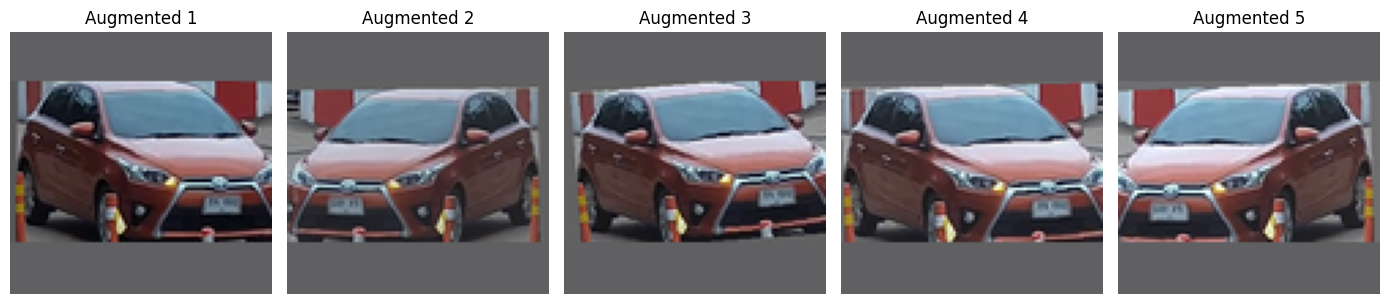


Table 29. Final training and evaluation preprocessing pipeline.


,Stage,Training,Validation_Test
0,Horizontal flip,p = 0.50,None
1,Affine rotation,±5°,None
2,Affine translation,±5%,None
3,Affine scale,0.95–1.05,None
4,Brightness jitter,±20%,None
5,Contrast jitter,±20%,None
6,Letterbox,"96×96, neutral padding","96×96, neutral padding"
7,Normalisation,Training statistics,Training statistics



DATASET AND AUGMENTATION CHECK
Training dataset   : 1,344
Validation dataset : 288
Test dataset       : 299
Tensor shape       : (3, 96, 96)
Target dtype       : torch.int64
Padding RGB        : (96, 96, 98)
Training augmentation: ENABLED
Validation/Test augmentation: DISABLED


In [15]:
# ============================================================
# 4.7 Training Augmentation and Dataset Pipeline
# ============================================================

# ------------------------------------------------------------
# Final transforms
# ------------------------------------------------------------

TRAIN_TRANSFORM = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(
            p=0.5
        ),

        transforms.RandomAffine(
            degrees=5,
            translate=(
                0.05,
                0.05,
            ),
            scale=(
                0.95,
                1.05,
            ),
            fill=PADDING_RGB,
        ),

        transforms.ColorJitter(
            brightness=0.20,
            contrast=0.20,
        ),

        LETTERBOX,

        transforms.ToTensor(),

        transforms.Normalize(
            mean=TRAIN_MEAN,
            std=TRAIN_STD,
        ),
    ]
)


EVAL_TRANSFORM = transforms.Compose(
    [
        LETTERBOX,

        transforms.ToTensor(),

        transforms.Normalize(
            mean=TRAIN_MEAN,
            std=TRAIN_STD,
        ),
    ]
)


# ------------------------------------------------------------
# Dataset class
# ------------------------------------------------------------

class VTID2Dataset(torch.utils.data.Dataset):
    """
    VTID2 dataset wrapper used throughout model development.

    Each item returns:
        image tensor
        numeric target
        canonical class name
        original path
        strict visual-group ID
        leakage-containment-group ID
    """

    def __init__(
        self,
        dataframe,
        transform,
    ):

        self.dataframe = (
            dataframe
            .copy()
            .reset_index(
                drop=True
            )
        )

        self.transform = transform


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]


        image_path = Path(
            row[
                "path"
            ]
        )


        with Image.open(
            image_path
        ) as image:

            image = image.convert(
                "RGB"
            )

            if self.transform is not None:

                image = self.transform(
                    image
                )


        class_name = row[
            "class_name"
        ]


        target = CLASS_TO_INDEX[
            class_name
        ]


        return {
            "image":
                image,

            "target":
                torch.tensor(
                    target,
                    dtype=torch.long,
                ),

            "class_name":
                class_name,

            "path":
                str(
                    image_path
                ),

            "visual_group_id":
                row[
                    "visual_group_id"
                ],

            "leakage_group_id":
                row[
                    "leakage_group_id"
                ],
        }


# ------------------------------------------------------------
# Frozen dataset objects
# ------------------------------------------------------------

train_dataset = VTID2Dataset(
    train_df,
    transform=TRAIN_TRANSFORM,
)


validation_dataset = VTID2Dataset(
    validation_df,
    transform=EVAL_TRANSFORM,
)


test_dataset = VTID2Dataset(
    test_df,
    transform=EVAL_TRANSFORM,
)


# ------------------------------------------------------------
# Dataset integrity checks
# ------------------------------------------------------------

assert (
    len(
        train_dataset
    )
    ==
    1344
)


assert (
    len(
        validation_dataset
    )
    ==
    288
)


assert (
    len(
        test_dataset
    )
    ==
    299
)


sample = train_dataset[
    0
]


assert (
    sample[
        "image"
    ].shape
    ==
    (
        3,
        TARGET_SIZE,
        TARGET_SIZE,
    )
)


assert (
    sample[
        "target"
    ].dtype
    ==
    torch.long
)


assert (
    sample[
        "class_name"
    ]
    in
    CLASS_NAMES
)


# ------------------------------------------------------------
# Visual augmentation check
#
# Repeatedly transform one training image to verify that
# stochastic augmentation is functioning as intended.
# ------------------------------------------------------------

preview_row = (
    train_df
    .iloc[0]
)


preview_path = Path(
    preview_row[
        "path"
    ]
)


fig, axes = plt.subplots(
    1,
    5,
    figsize=(
        14,
        3,
    ),
)


with Image.open(
    preview_path
) as original_image:

    original_image = (
        original_image
        .convert(
            "RGB"
        )
    )


    for index, axis in enumerate(
        axes
    ):

        # Apply augmentation up to the letterbox stage
        augmented_pil = transforms.Compose(
            [
                transforms.RandomHorizontalFlip(
                    p=0.5
                ),

                transforms.RandomAffine(
                    degrees=5,
                    translate=(
                        0.05,
                        0.05,
                    ),
                    scale=(
                        0.95,
                        1.05,
                    ),
                    fill=PADDING_RGB,
                ),

                transforms.ColorJitter(
                    brightness=0.20,
                    contrast=0.20,
                ),

                LETTERBOX,
            ]
        )(
            original_image
        )


        axis.imshow(
            augmented_pil
        )


        axis.set_title(
            f"Augmented {index + 1}"
        )


        axis.axis(
            "off"
        )


fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Examples of stochastic training augmentation "
        "before tensor conversion and normalisation."
    ),
    filename=(
        "training_augmentation_examples.png"
    ),
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

augmentation_summary_df = pd.DataFrame(
    {
        "Stage": [
            "Horizontal flip",
            "Affine rotation",
            "Affine translation",
            "Affine scale",
            "Brightness jitter",
            "Contrast jitter",
            "Letterbox",
            "Normalisation",
        ],

        "Training": [
            "p = 0.50",
            "±5°",
            "±5%",
            "0.95–1.05",
            "±20%",
            "±20%",
            "96×96, neutral padding",
            "Training statistics",
        ],

        "Validation_Test": [
            "None",
            "None",
            "None",
            "None",
            "None",
            "None",
            "96×96, neutral padding",
            "Training statistics",
        ],
    }
)


show_table(
    augmentation_summary_df,
    caption=(
        "Final training and evaluation preprocessing pipeline."
    ),
    filename=(
        "final_preprocessing_pipeline.csv"
    ),
    decimals=2,
)


print(
    "\n"
    + "=" * 68
)

print(
    "DATASET AND AUGMENTATION CHECK"
)

print(
    "=" * 68
)

print(
    f"Training dataset   : "
    f"{len(train_dataset):,}"
)

print(
    f"Validation dataset : "
    f"{len(validation_dataset):,}"
)

print(
    f"Test dataset       : "
    f"{len(test_dataset):,}"
)

print(
    f"Tensor shape       : "
    f"{tuple(sample['image'].shape)}"
)

print(
    f"Target dtype       : "
    f"{sample['target'].dtype}"
)

print(
    f"Padding RGB        : "
    f"{PADDING_RGB}"
)

print(
    "Training augmentation: ENABLED"
)

print(
    "Validation/Test augmentation: DISABLED"
)

print(
    "=" * 68
)

### 4.8 Conventional Image-Level Diagnostic for RQ2

For RQ2 a conventional split was rebuilt from the original archive with duplicates retained (3,049/653/654, lr = 1e-3, batch = 32), against the leakage-controlled 1,344/288/299 (lr = 0.01, batch = 64). Training-set size, optimisation settings and dataset composition therefore vary alongside the split rule, so this is a non-equivalent diagnostic contrast rather than a causal leakage estimate — a caveat that governs every RQ2 figure reported below. Normalisation statistics also remain fixed at leakage-controlled values derived partly from this partition's images, though channel statistics carry negligible class information relative to its 72.63% duplicate contamination.

In [16]:
# ============================================================
# 4.8 Performance Inflation under Naive Splitting
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
)


# ------------------------------------------------------------
# Diagnostic configuration
# ------------------------------------------------------------

DIAGNOSTIC_SEEDS = [
    42,
    123,
    2026,
]

DIAGNOSTIC_BATCH_SIZE = 32

DIAGNOSTIC_LEARNING_RATE = 1e-3

DIAGNOSTIC_WEIGHT_DECAY = 1e-4

DIAGNOSTIC_MAX_EPOCHS = 50

DIAGNOSTIC_EARLY_STOPPING_PATIENCE = 8

DIAGNOSTIC_LR_PATIENCE = 3

DIAGNOSTIC_LR_FACTOR = 0.5

DIAGNOSTIC_MIN_LR = 1e-6


DIAGNOSTIC_DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)




print(
    "Diagnostic device:",
    DIAGNOSTIC_DEVICE,
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )


# ------------------------------------------------------------
# Preserve global random states so this diagnostic does not
# alter later main-pipeline random sequences.
# ------------------------------------------------------------

python_rng_state = random.getstate()

numpy_rng_state = np.random.get_state()

torch_rng_state = torch.random.get_rng_state()

cuda_rng_states = (
    torch.cuda.get_rng_state_all()
    if torch.cuda.is_available()
    else None
)


def set_diagnostic_seed(
    seed,
):
    """
    Fix all random generators used by the diagnostic run.
    """

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed(
            seed
        )

        torch.cuda.manual_seed_all(
            seed
        )


    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# Rebuild the conventional image-level split
#
# Important:
# - original archive
# - duplicates retained
# - no group constraint
# - same partition for all three training seeds
# ------------------------------------------------------------

naive_split_indices = naive_image_split(
    original_grouped_df,
    seed=FINAL_SPLIT_SEED,
)


naive_train_df = (
    original_grouped_df
    .iloc[
        naive_split_indices[
            "train"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


naive_validation_df = (
    original_grouped_df
    .iloc[
        naive_split_indices[
            "validation"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


naive_test_df = (
    original_grouped_df
    .iloc[
        naive_split_indices[
            "test"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


naive_partition_df = pd.DataFrame(
    {
        "Partition": [
            "Train",
            "Validation",
            "Test",
            "Total",
        ],

        "Images": [
            len(
                naive_train_df
            ),
            len(
                naive_validation_df
            ),
            len(
                naive_test_df
            ),
            len(
                original_grouped_df
            ),
        ],
    }
)


show_table(
    naive_partition_df,
    caption=(
        "Conventional image-level diagnostic "
        "partition with duplicates retained."
    ),
    filename=(
        "naive_protocol_partition_sizes.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Confirm contamination in this exact diagnostic split
# ------------------------------------------------------------

naive_train_hashes = set(
    naive_train_df[
        "decoded_rgb_sha256"
    ]
)


naive_train_groups = set(
    naive_train_df[
        "leakage_group_id"
    ]
)


naive_test_exact_leakage = float(
    naive_test_df[
        "decoded_rgb_sha256"
    ]
    .isin(
        naive_train_hashes
    )
    .mean()
    * 100
)


naive_test_group_contamination = float(
    naive_test_df[
        "leakage_group_id"
    ]
    .isin(
        naive_train_groups
    )
    .mean()
    * 100
)


print(
    "\nExact diagnostic split contamination:"
)

print(
    f"Test exact leakage       : "
    f"{naive_test_exact_leakage:.2f}%"
)

print(
    f"Test group contamination : "
    f"{naive_test_group_contamination:.2f}%"
)


# ------------------------------------------------------------
# Diagnostic dataset
# ------------------------------------------------------------

class NaiveDiagnosticDataset(
    torch.utils.data.Dataset
):
    """
    Minimal dataset for the protocol-level diagnostic.
    """

    def __init__(
        self,
        dataframe,
        transform,
    ):

        self.dataframe = (
            dataframe
            .copy()
            .reset_index(
                drop=True
            )
        )

        self.transform = transform


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index,
    ):

        row = self.dataframe.iloc[
            index
        ]


        image_path = Path(
            row[
                "path"
            ]
        )


        with Image.open(
            image_path
        ) as image:

            image = image.convert(
                "RGB"
            )

            image = self.transform(
                image
            )


        target = CLASS_TO_INDEX[
            row[
                "class_name"
            ]
        ]


        return (
            image,
            torch.tensor(
                target,
                dtype=torch.long,
            ),
        )


# ------------------------------------------------------------
# Diagnostic Standard CNN
#
# This matches the frozen main Standard-CNN architecture:
#
# 3 -> 32 stem
# 32 -> 64
# 64 -> 128
# 128 -> 128
# GAP -> Dropout -> 5 classes
# ------------------------------------------------------------

class DiagnosticConvBNReLU(
    torch.nn.Module
):

    def __init__(
        self,
        in_channels,
        out_channels,
    ):

        super().__init__()


        self.block = torch.nn.Sequential(

            torch.nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            torch.nn.BatchNorm2d(
                out_channels
            ),

            torch.nn.ReLU(
                inplace=True
            ),
        )


    def forward(
        self,
        x,
    ):

        return self.block(
            x
        )


class DiagnosticStandardCNN(
    torch.nn.Module
):

    def __init__(
        self,
        num_classes=5,
    ):

        super().__init__()


        self.stem = torch.nn.Sequential(

            DiagnosticConvBNReLU(
                3,
                32,
            ),

            torch.nn.MaxPool2d(
                kernel_size=2
            ),
        )


        self.features = torch.nn.Sequential(

            DiagnosticConvBNReLU(
                32,
                64,
            ),

            torch.nn.MaxPool2d(
                kernel_size=2
            ),

            DiagnosticConvBNReLU(
                64,
                128,
            ),

            torch.nn.MaxPool2d(
                kernel_size=2
            ),

            DiagnosticConvBNReLU(
                128,
                128,
            ),

            torch.nn.MaxPool2d(
                kernel_size=2
            ),
        )


        self.pool = (
            torch.nn.AdaptiveAvgPool2d(
                1
            )
        )


        self.dropout = torch.nn.Dropout(
            p=0.30
        )


        self.classifier = torch.nn.Linear(
            128,
            num_classes,
        )


    def forward(
        self,
        x,
    ):

        x = self.stem(
            x
        )

        x = self.features(
            x
        )

        x = self.pool(
            x
        )

        x = torch.flatten(
            x,
            1,
        )

        x = self.dropout(
            x
        )

        return self.classifier(
            x
        )


# ------------------------------------------------------------
# Architecture integrity check
# ------------------------------------------------------------

diagnostic_model_check = (
    DiagnosticStandardCNN(
        num_classes=len(
            CLASS_NAMES
        )
    )
)


diagnostic_parameter_count = sum(
    parameter.numel()

    for parameter
    in diagnostic_model_check.parameters()

    if parameter.requires_grad
)


print(
    "\nDiagnostic Standard-CNN parameters:",
    f"{diagnostic_parameter_count:,}",
)


assert (
    diagnostic_parameter_count
    ==
    241829
), (
    "The diagnostic Standard CNN does not match "
    "the frozen architecture."
)


del diagnostic_model_check


# ------------------------------------------------------------
# Loader construction
# ------------------------------------------------------------

def make_naive_diagnostic_loaders(
    seed,
):

    training_dataset = (
        NaiveDiagnosticDataset(
            naive_train_df,
            transform=TRAIN_TRANSFORM,
        )
    )


    validation_dataset = (
        NaiveDiagnosticDataset(
            naive_validation_df,
            transform=EVAL_TRANSFORM,
        )
    )


    testing_dataset = (
        NaiveDiagnosticDataset(
            naive_test_df,
            transform=EVAL_TRANSFORM,
        )
    )


    generator = (
        torch.Generator()
        .manual_seed(
            seed
        )
    )


    common_loader_settings = {
        "num_workers": 0,
        "pin_memory":
            torch.cuda.is_available(),
    }


    training_loader = (
        torch.utils.data.DataLoader(

            training_dataset,

            batch_size=(
                DIAGNOSTIC_BATCH_SIZE
            ),

            shuffle=True,

            generator=generator,

            **common_loader_settings,
        )
    )


    validation_loader = (
        torch.utils.data.DataLoader(

            validation_dataset,

            batch_size=(
                DIAGNOSTIC_BATCH_SIZE
            ),

            shuffle=False,

            **common_loader_settings,
        )
    )


    testing_loader = (
        torch.utils.data.DataLoader(

            testing_dataset,

            batch_size=(
                DIAGNOSTIC_BATCH_SIZE
            ),

            shuffle=False,

            **common_loader_settings,
        )
    )


    return (
        training_loader,
        validation_loader,
        testing_loader,
    )


# ------------------------------------------------------------
# Evaluation helper
# ------------------------------------------------------------

def evaluate_diagnostic_model(
    model,
    loader,
):

    model.eval()


    true_targets = []

    predictions = []


    with torch.no_grad():

        for images, targets in loader:

            images = images.to(
                DIAGNOSTIC_DEVICE,
                non_blocking=True,
            )

            targets = targets.to(
                DIAGNOSTIC_DEVICE,
                non_blocking=True,
            )


            logits = model(
                images
            )


            predicted = torch.argmax(
                logits,
                dim=1,
            )


            true_targets.extend(
                targets
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


            predictions.extend(
                predicted
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


    macro_f1 = f1_score(
        true_targets,
        predictions,
        average="macro",
        zero_division=0,
    )


    accuracy = accuracy_score(
        true_targets,
        predictions,
    )


    return (
        float(
            macro_f1
        ),
        float(
            accuracy
        ),
    )


# ------------------------------------------------------------
# Train one diagnostic seed
# ------------------------------------------------------------

def run_naive_diagnostic_seed(
    seed,
):

    set_diagnostic_seed(
        seed
    )


    (
        training_loader,
        validation_loader,
        testing_loader,
    ) = make_naive_diagnostic_loaders(
        seed
    )


    model = (
        DiagnosticStandardCNN(
            num_classes=len(
                CLASS_NAMES
            )
        )
        .to(
            DIAGNOSTIC_DEVICE
        )
    )


    criterion = (
        torch.nn.CrossEntropyLoss()
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=(
            DIAGNOSTIC_LEARNING_RATE
        ),

        weight_decay=(
            DIAGNOSTIC_WEIGHT_DECAY
        ),
    )


    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(

            optimizer,

            mode="max",

            factor=(
                DIAGNOSTIC_LR_FACTOR
            ),

            patience=(
                DIAGNOSTIC_LR_PATIENCE
            ),

            min_lr=(
                DIAGNOSTIC_MIN_LR
            ),
        )
    )


    best_validation_f1 = (
        -np.inf
    )

    best_epoch = None

    best_state = None

    epochs_without_improvement = 0

    history_rows = []


    for epoch in range(
        1,
        DIAGNOSTIC_MAX_EPOCHS + 1,
    ):

        model.train()


        running_loss = 0.0

        running_examples = 0


        for images, targets in training_loader:

            images = images.to(
                DIAGNOSTIC_DEVICE,
                non_blocking=True,
            )

            targets = targets.to(
                DIAGNOSTIC_DEVICE,
                non_blocking=True,
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                targets,
            )


            loss.backward()


            optimizer.step()


            batch_size = (
                images.size(0)
            )


            running_loss += (
                float(
                    loss.item()
                )
                *
                batch_size
            )


            running_examples += (
                batch_size
            )


        training_loss = (
            running_loss
            /
            running_examples
        )


        (
            validation_f1,
            validation_accuracy,
        ) = evaluate_diagnostic_model(
            model,
            validation_loader,
        )


        scheduler.step(
            validation_f1
        )


        current_lr = (
            optimizer.param_groups[0][
                "lr"
            ]
        )


        history_rows.append(
            {
                "Seed":
                    seed,

                "Epoch":
                    epoch,

                "Training_Loss":
                    training_loss,

                "Validation_Macro_F1":
                    validation_f1,

                "Validation_Accuracy":
                    validation_accuracy,

                "Learning_Rate":
                    current_lr,
            }
        )


        improved = (
            validation_f1
            >
            best_validation_f1
        )


        if improved:

            best_validation_f1 = (
                validation_f1
            )

            best_epoch = (
                epoch
            )

            best_state = (
                copy.deepcopy(
                    model.state_dict()
                )
            )

            epochs_without_improvement = (
                0
            )


        else:

            epochs_without_improvement += (
                1
            )


        print(
            f"Seed {seed} | "
            f"Epoch {epoch:02d} | "
            f"loss={training_loss:.4f} | "
            f"valF1={validation_f1:.4f} | "
            f"lr={current_lr:.6f}"
        )


        if (
            epochs_without_improvement
            >=
            DIAGNOSTIC_EARLY_STOPPING_PATIENCE
        ):

            print(
                f"Early stopping: seed {seed} "
                f"at epoch {epoch}."
            )

            break


    if best_state is None:

        raise RuntimeError(
            "No best diagnostic checkpoint was created."
        )


    model.load_state_dict(
        best_state
    )


    (
        test_macro_f1,
        test_accuracy,
    ) = evaluate_diagnostic_model(
        model,
        testing_loader,
    )


    history_df = pd.DataFrame(
        history_rows
    )


    history_df.to_csv(
        OUTPUT_DIR
        /
        f"naive_protocol_history_seed_{seed}.csv",

        index=False,
    )


    result = {
        "Seed":
            seed,

        "Best_Epoch":
            best_epoch,

        "Best_Validation_Macro_F1":
            best_validation_f1,

        "Naive_Test_Macro_F1":
            test_macro_f1,

        "Naive_Test_Accuracy":
            test_accuracy,
    }


    del model

    del optimizer

    del scheduler


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return result


# ------------------------------------------------------------
# Execute the three diagnostic runs
# ------------------------------------------------------------

naive_protocol_results = []


try:

    for diagnostic_seed in DIAGNOSTIC_SEEDS:

        print(
            "\n"
            + "=" * 68
        )

        print(
            f"NAIVE PROTOCOL — SEED "
            f"{diagnostic_seed}"
        )

        print(
            "=" * 68
        )


        result = (
            run_naive_diagnostic_seed(
                diagnostic_seed
            )
        )


        naive_protocol_results.append(
            result
        )


finally:

    # Restore RNG states so this diagnostic remains isolated
    random.setstate(
        python_rng_state
    )

    np.random.set_state(
        numpy_rng_state
    )

    torch.random.set_rng_state(
        torch_rng_state
    )

    if (
        torch.cuda.is_available()
        and
        cuda_rng_states is not None
    ):

        torch.cuda.set_rng_state_all(
            cuda_rng_states
        )


# ------------------------------------------------------------
# Per-seed results
# ------------------------------------------------------------

naive_protocol_results_df = pd.DataFrame(
    naive_protocol_results
)


show_table(
    naive_protocol_results_df,
    caption=(
        "Standard-CNN results under the "
        "conventional image-level protocol."
    ),
    filename=(
        "naive_protocol_standard_cnn_per_seed.csv"
    ),
    decimals=4,
)


naive_protocol_results_df.to_csv(
    OUTPUT_DIR
    / "naive_protocol_standard_cnn_per_seed.csv",
    index=False,
)


# ------------------------------------------------------------
# Mean ± SD across three seeds
# ------------------------------------------------------------

naive_macro_f1_mean = float(
    naive_protocol_results_df[
        "Naive_Test_Macro_F1"
    ].mean()
)


naive_macro_f1_sd = float(
    naive_protocol_results_df[
        "Naive_Test_Macro_F1"
    ].std(
        ddof=1
    )
)


naive_accuracy_mean = float(
    naive_protocol_results_df[
        "Naive_Test_Accuracy"
    ].mean()
)


naive_accuracy_sd = float(
    naive_protocol_results_df[
        "Naive_Test_Accuracy"
    ].std(
        ddof=1
    )
)
# ------------------------------------------------------------
# Naive-protocol result only
#
# The comparison with the final leakage-controlled result is
# intentionally deferred to Section 7.1, where it is computed
# from final_test_summary_df.
# ------------------------------------------------------------

naive_diagnostic_summary_df = pd.DataFrame(
    {
        "Measure": [
            "Naive test Macro-F1 mean",
            "Naive test Macro-F1 SD",
            "Naive test accuracy mean",
            "Naive test accuracy SD",
        ],
        "Value": [
            naive_macro_f1_mean,
            naive_macro_f1_sd,
            naive_accuracy_mean,
            naive_accuracy_sd,
        ],
    }
)

show_table(
    naive_diagnostic_summary_df,
    caption=(
        "Conventional image-level protocol "
        "performance diagnostic."
    ),
    filename="naive_protocol_performance_diagnostic.csv",
    decimals=4,
)

print("\n" + "=" * 68)
print("NAIVE PROTOCOL PERFORMANCE DIAGNOSTIC")
print("=" * 68)

print(
    "Naive test Macro-F1 : "
    f"{naive_macro_f1_mean:.4f} "
    f"± {naive_macro_f1_sd:.4f}"
)

print(
    "Naive test accuracy : "
    f"{naive_accuracy_mean:.4f} "
    f"± {naive_accuracy_sd:.4f}"
)

print(
    "\nFinal protocol comparison is deferred "
    "to Section 7.1."
)

print("=" * 68)



Diagnostic device: cuda
GPU: Quadro M3000M

Table 30. Conventional image-level diagnostic partition with duplicates retained.


,Partition,Images
0,Train,3049
1,Validation,653
2,Test,654
3,Total,4356



Exact diagnostic split contamination:
Test exact leakage       : 72.63%
Test group contamination : 74.01%

Diagnostic Standard-CNN parameters: 241,829

NAIVE PROTOCOL — SEED 42
Seed 42 | Epoch 01 | loss=1.0100 | valF1=0.5403 | lr=0.001000
Seed 42 | Epoch 02 | loss=0.7688 | valF1=0.7476 | lr=0.001000
Seed 42 | Epoch 03 | loss=0.6841 | valF1=0.7788 | lr=0.001000
Seed 42 | Epoch 04 | loss=0.6067 | valF1=0.7425 | lr=0.001000
Seed 42 | Epoch 05 | loss=0.5342 | valF1=0.5959 | lr=0.001000
Seed 42 | Epoch 06 | loss=0.4988 | valF1=0.8113 | lr=0.001000
Seed 42 | Epoch 07 | loss=0.4584 | valF1=0.6750 | lr=0.001000
Seed 42 | Epoch 08 | loss=0.4067 | valF1=0.7223 | lr=0.001000
Seed 42 | Epoch 09 | loss=0.3981 | valF1=0.7133 | lr=0.001000
Seed 42 | Epoch 10 | loss=0.3742 | valF1=0.6691 | lr=0.000500
Seed 42 | Epoch 11 | loss=0.2901 | valF1=0.7691 | lr=0.000500
Seed 42 | Epoch 12 | loss=0.2590 | valF1=0.7990 | lr=0.000500
Seed 42 | Epoch 13 | loss=0.2379 | valF1=0.7790 | lr=0.000500
Seed 42 | Epoch 

,Seed,Best_Epoch,Best_Validation_Macro_F1,Naive_Test_Macro_F1,Naive_Test_Accuracy
0,42,38,0.9903,0.9853,0.9862
1,123,36,0.9967,0.9832,0.9847
2,2026,37,0.9889,0.9819,0.9832



Table 32. Conventional image-level protocol performance diagnostic.


,Measure,Value
0,Naive test Macro-F1 mean,0.9835
1,Naive test Macro-F1 SD,0.0017
2,Naive test accuracy mean,0.9847
3,Naive test accuracy SD,0.0015



NAIVE PROTOCOL PERFORMANCE DIAGNOSTIC
Naive test Macro-F1 : 0.9835 ± 0.0017
Naive test accuracy : 0.9847 ± 0.0015

Final protocol comparison is deferred to Section 7.1.


## 5. Model Design

### 5.1 Controlled Architecture Comparison

All models use the same 96×96 RGB input. The MLP removes spatial structure by flattening the image before hidden layers of **512 and 128 units**; its parameter implications are discussed in Section 5.2.

The CNN family follows the classic convolutional template (LeCun et al., 1998), using a 32-channel stem followed by **64/128/128** channels. Each 2×2 pooling stage halves spatial resolution (**96→48→24→12→6**) while channel width increases, shifting capacity from fine local detail toward higher-level vehicle-shape features. Holding the final two stages at 128 channels avoids unnecessary expansion on the relatively small VTID2 dataset. Global average pooling replaces a large dense head, and dropout **0.30** regularises the classifier interface.

The Efficient CNN keeps the same stage widths and downsampling schedule but replaces standard convolutions with depthwise–pointwise factorisation, making operator type the principal architectural change. SE reduction **8** produces compact channel bottlenecks (**8 or 16 units** here), enabling channel recalibration while adding little capacity relative to the backbone (Hu, Shen and Sun, 2018).

Unlike Howard et al. (2017), BN and ReLU are applied only after pointwise convolution. This deliberately matches the Standard CNN's one nonlinearity per block, making operator type the main comparison.


In [17]:
# ============================================================
# 5.1 Controlled Architecture Comparison
# ============================================================


# ------------------------------------------------------------
# MLP baseline
# ------------------------------------------------------------

class MLPBaseline(torch.nn.Module):
    """
    Fully connected baseline.

    Spatial image structure is discarded by flattening the
    3 × 96 × 96 input before classification.
    """

    def __init__(
        self,
        num_classes=5,
    ):

        super().__init__()


        flattened_features = (
            3
            *
            TARGET_SIZE
            *
            TARGET_SIZE
        )


        self.network = torch.nn.Sequential(

            torch.nn.Flatten(),

            torch.nn.Linear(
                flattened_features,
                512,
            ),

            torch.nn.BatchNorm1d(
                512
            ),

            torch.nn.ReLU(
                inplace=True
            ),

            torch.nn.Dropout(
                p=0.40
            ),

            torch.nn.Linear(
                512,
                128,
            ),

            torch.nn.BatchNorm1d(
                128
            ),

            torch.nn.ReLU(
                inplace=True
            ),

            torch.nn.Dropout(
                p=0.30
            ),

            torch.nn.Linear(
                128,
                num_classes,
            ),
        )


    def forward(
        self,
        x,
    ):

        return self.network(
            x
        )


# ------------------------------------------------------------
# Standard convolutional block
# ------------------------------------------------------------

class StandardConvBlock(torch.nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
    ):

        super().__init__()


        self.block = torch.nn.Sequential(

            torch.nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False,
            ),

            torch.nn.BatchNorm2d(
                out_channels
            ),

            torch.nn.ReLU(
                inplace=True
            ),
        )


    def forward(
        self,
        x,
    ):

        return self.block(
            x
        )


# ------------------------------------------------------------
# Controlled depthwise-separable block
#
# One BatchNorm + ReLU is applied after pointwise mixing.
# ------------------------------------------------------------

class DepthwiseSeparableBlock(torch.nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
    ):

        super().__init__()


        self.depthwise = torch.nn.Conv2d(

            in_channels,
            in_channels,

            kernel_size=3,
            padding=1,

            groups=in_channels,

            bias=False,
        )


        self.pointwise = torch.nn.Conv2d(

            in_channels,
            out_channels,

            kernel_size=1,

            bias=False,
        )


        self.batch_norm = torch.nn.BatchNorm2d(
            out_channels
        )


        self.relu = torch.nn.ReLU(
            inplace=True
        )


    def forward(
        self,
        x,
    ):

        x = self.depthwise(
            x
        )

        x = self.pointwise(
            x
        )

        x = self.batch_norm(
            x
        )

        x = self.relu(
            x
        )

        return x


# ------------------------------------------------------------
# Squeeze-and-Excitation block
# ------------------------------------------------------------

class SqueezeExcitation(torch.nn.Module):

    def __init__(
        self,
        channels,
        reduction=8,
    ):

        super().__init__()


        reduced_channels = max(
            1,
            channels // reduction,
        )


        self.pool = (
            torch.nn.AdaptiveAvgPool2d(
                1
            )
        )


        self.fc1 = torch.nn.Linear(
            channels,
            reduced_channels,
        )


        self.relu = torch.nn.ReLU(
            inplace=True
        )


        self.fc2 = torch.nn.Linear(
            reduced_channels,
            channels,
        )


        self.sigmoid = torch.nn.Sigmoid()


    def forward(
        self,
        x,
    ):

        batch_size, channels, _, _ = (
            x.shape
        )


        weights = self.pool(
            x
        ).view(
            batch_size,
            channels,
        )


        weights = self.fc1(
            weights
        )

        weights = self.relu(
            weights
        )

        weights = self.fc2(
            weights
        )

        weights = self.sigmoid(
            weights
        )


        weights = weights.view(
            batch_size,
            channels,
            1,
            1,
        )


        return (
            x
            *
            weights
        )


# ------------------------------------------------------------
# Shared CNN architecture
# ------------------------------------------------------------

class VehicleCNN(torch.nn.Module):
    """
    Controlled CNN family.

    mode:
        "standard"  -> regular 3×3 convolutions
        "efficient" -> depthwise + pointwise convolutions

    use_se:
        adds Squeeze-and-Excitation after each main block
    """

    def __init__(
        self,
        mode="standard",
        use_se=False,
        num_classes=5,
    ):

        super().__init__()


        if mode not in {
            "standard",
            "efficient",
        }:

            raise ValueError(
                "mode must be 'standard' or 'efficient'."
            )


        self.mode = mode

        self.use_se = use_se


        # Shared conventional stem
        self.stem = torch.nn.Sequential(

            StandardConvBlock(
                3,
                32,
            ),

            torch.nn.MaxPool2d(
                kernel_size=2
            ),
        )


        block_class = (
            StandardConvBlock
            if mode == "standard"
            else DepthwiseSeparableBlock
        )


        self.block1 = block_class(
            32,
            64,
        )


        self.block2 = block_class(
            64,
            128,
        )


        self.block3 = block_class(
            128,
            128,
        )


        if use_se:

            self.se1 = SqueezeExcitation(
                64,
                reduction=8,
            )

            self.se2 = SqueezeExcitation(
                128,
                reduction=8,
            )

            self.se3 = SqueezeExcitation(
                128,
                reduction=8,
            )


        self.pool1 = torch.nn.MaxPool2d(
            kernel_size=2
        )

        self.pool2 = torch.nn.MaxPool2d(
            kernel_size=2
        )

        self.pool3 = torch.nn.MaxPool2d(
            kernel_size=2
        )


        self.global_pool = (
            torch.nn.AdaptiveAvgPool2d(
                1
            )
        )


        self.dropout = torch.nn.Dropout(
            p=0.30
        )


        self.classifier = torch.nn.Linear(
            128,
            num_classes,
        )


    def forward(
        self,
        x,
    ):

        x = self.stem(
            x
        )


        x = self.block1(
            x
        )

        if self.use_se:

            x = self.se1(
                x
            )

        x = self.pool1(
            x
        )


        x = self.block2(
            x
        )

        if self.use_se:

            x = self.se2(
                x
            )

        x = self.pool2(
            x
        )


        x = self.block3(
            x
        )

        if self.use_se:

            x = self.se3(
                x
            )

        x = self.pool3(
            x
        )


        x = self.global_pool(
            x
        )


        x = torch.flatten(
            x,
            1,
        )


        x = self.dropout(
            x
        )


        return self.classifier(
            x
        )


# ------------------------------------------------------------
# Instantiate the four frozen architectures
# ------------------------------------------------------------

MODEL_BUILDERS = {

    "MLP":
        lambda: MLPBaseline(
            num_classes=len(
                CLASS_NAMES
            )
        ),

    "Standard CNN":
        lambda: VehicleCNN(
            mode="standard",
            use_se=False,
            num_classes=len(
                CLASS_NAMES
            ),
        ),

    "Efficient CNN":
        lambda: VehicleCNN(
            mode="efficient",
            use_se=False,
            num_classes=len(
                CLASS_NAMES
            ),
        ),

    "Efficient CNN + SE":
        lambda: VehicleCNN(
            mode="efficient",
            use_se=True,
            num_classes=len(
                CLASS_NAMES
            ),
        ),
}


# ------------------------------------------------------------
# Parameter counting and forward-pass integrity check
# ------------------------------------------------------------

architecture_rows = []


dummy_input = torch.zeros(
    2,
    3,
    TARGET_SIZE,
    TARGET_SIZE,
)


for model_name, builder in (
    MODEL_BUILDERS.items()
):

    model = builder()


    model.eval()


    parameter_count = sum(
        parameter.numel()

        for parameter
        in model.parameters()

        if parameter.requires_grad
    )


    with torch.no_grad():

        dummy_output = model(
            dummy_input
        )


    assert (
        dummy_output.shape
        ==
        (
            2,
            len(
                CLASS_NAMES
            ),
        )
    )


    architecture_rows.append(
        {
            "Model":
                model_name,

            "Trainable_Parameters":
                parameter_count,

            "Output_Shape":
                str(
                    tuple(
                        dummy_output.shape
                    )
                ),
        }
    )


architecture_df = pd.DataFrame(
    architecture_rows
)


show_table(
    architecture_df,
    caption=(
        "Trainable parameter counts for the "
        "four controlled neural-network architectures."
    ),
    filename=(
        "model_architecture_parameter_counts.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Frozen architecture checks
# ------------------------------------------------------------

expected_parameter_counts = {

    "MLP":
        14223877,

    "Standard CNN":
        241829,

    "Efficient CNN":
        30853,

    "Efficient CNN + SE":
        40429,
}


for model_name, expected_count in (
    expected_parameter_counts.items()
):

    measured_count = int(
        architecture_df.loc[
            architecture_df[
                "Model"
            ]
            ==
            model_name,

            "Trainable_Parameters",
        ].iloc[0]
    )


    assert (
        measured_count
        ==
        expected_count
    ), (
        f"{model_name} parameter count mismatch: "
        f"{measured_count:,} != {expected_count:,}"
    )


print(
    "\n"
    + "=" * 68
)

print(
    "MODEL ARCHITECTURE CHECK"
)

print(
    "=" * 68
)


for row in architecture_rows:

    print(
        f"{row['Model']:20s} : "
        f"{row['Trainable_Parameters']:,} parameters"
    )


print(
    "\nAll forward-pass shapes and frozen "
    "parameter counts are correct."
)

print(
    "=" * 68
)


Table 33. Trainable parameter counts for the four controlled neural-network architectures.


,Model,Trainable_Parameters,Output_Shape
0,MLP,14223877,"(2, 5)"
1,Standard CNN,241829,"(2, 5)"
2,Efficient CNN,30853,"(2, 5)"
3,Efficient CNN + SE,40429,"(2, 5)"



MODEL ARCHITECTURE CHECK
MLP                  : 14,223,877 parameters
Standard CNN         : 241,829 parameters
Efficient CNN        : 30,853 parameters
Efficient CNN + SE   : 40,429 parameters

All forward-pass shapes and frozen parameter counts are correct.


### 5.2 Architectural Complexity and Design Rationale

The architectures are not parameter-matched: the MLP has 58.82× more parameters than the Standard CNN, so RQ1 is an empirical comparison, not an isolated test of spatial inductive bias. One limit is structural: the stem is a standard convolution at full 96×96 resolution, costing 7.96M of the Efficient CNN's 20.92M MACs, bounding what depthwise factorisation can save. Table 34 reports the full parameter comparisons. The innovation is mainly the evaluation design: leakage-group partitioning and full-test Grad-CAM padding analysis.

In [18]:
# ============================================================
# 5.2 Architectural Complexity and Design Rationale
# ============================================================


# ------------------------------------------------------------
# Retrieve parameter counts measured in Section 5.1
# ------------------------------------------------------------

parameter_lookup = (
    architecture_df
    .set_index(
        "Model"
    )[
        "Trainable_Parameters"
    ]
    .to_dict()
)


standard_parameters = int(
    parameter_lookup[
        "Standard CNN"
    ]
)


efficient_parameters = int(
    parameter_lookup[
        "Efficient CNN"
    ]
)


se_parameters = int(
    parameter_lookup[
        "Efficient CNN + SE"
    ]
)


mlp_parameters = int(
    parameter_lookup[
        "MLP"
    ]
)


# ------------------------------------------------------------
# Controlled parameter comparisons
# ------------------------------------------------------------

efficient_reduction_vs_standard = (
    1
    -
    efficient_parameters
    /
    standard_parameters
) * 100


se_reduction_vs_standard = (
    1
    -
    se_parameters
    /
    standard_parameters
) * 100


se_increase_vs_efficient = (
    se_parameters
    /
    efficient_parameters
    -
    1
) * 100


mlp_multiple_vs_standard = (
    mlp_parameters
    /
    standard_parameters
)


complexity_comparison_df = pd.DataFrame(
    {
        "Comparison": [
            "Efficient CNN vs Standard CNN",
            "Efficient CNN + SE vs Standard CNN",
            "Efficient CNN + SE vs Efficient CNN",
            "MLP vs Standard CNN",
        ],

        "Measure": [
            "Parameter reduction (%)",
            "Parameter reduction (%)",
            "Parameter increase (%)",
            "Parameter multiple (×)",
        ],

        "Value": [
            efficient_reduction_vs_standard,
            se_reduction_vs_standard,
            se_increase_vs_efficient,
            mlp_multiple_vs_standard,
        ],
    }
)


show_table(
    complexity_comparison_df,
    caption=(
        "Parameter-complexity comparisons "
        "between the controlled architectures."
    ),
    filename=(
        "architecture_parameter_comparisons.csv"
    ),
    decimals=2,
)


# ------------------------------------------------------------
# Compact architecture summary
# ------------------------------------------------------------

architecture_design_df = pd.DataFrame(
    {
        "Model": [
            "MLP",
            "Standard CNN",
            "Efficient CNN",
            "Efficient CNN + SE",
        ],

        "Primary_Design_Feature": [
            "Flattened fully connected representation",
            "Regular 3×3 spatial convolution",
            "Depthwise + pointwise convolution",
            "Depthwise + pointwise convolution with SE",
        ],

        "Spatial_Convolution": [
            "No",
            "Yes",
            "Yes",
            "Yes",
        ],

        "Channel_Attention": [
            "No",
            "No",
            "No",
            "Yes",
        ],

        "Trainable_Parameters": [
            mlp_parameters,
            standard_parameters,
            efficient_parameters,
            se_parameters,
        ],
    }
)


show_table(
    architecture_design_df,
    caption=(
        "Controlled architectural characteristics "
        "of the four neural-network models."
    ),
    filename=(
        "architecture_design_summary.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Final output
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "ARCHITECTURAL COMPLEXITY CHECK"
)

print(
    "=" * 68
)

print(
    "Efficient vs Standard parameter reduction : "
    f"{efficient_reduction_vs_standard:.2f}%"
)

print(
    "Efficient + SE vs Standard reduction       : "
    f"{se_reduction_vs_standard:.2f}%"
)

print(
    "SE parameter increase over Efficient       : "
    f"{se_increase_vs_efficient:.2f}%"
)

print(
    "MLP parameters relative to Standard CNN    : "
    f"{mlp_multiple_vs_standard:.2f}×"
)

print(
    "=" * 68
)


Table 34. Parameter-complexity comparisons between the controlled architectures.


,Comparison,Measure,Value
0,Efficient CNN vs Standard CNN,Parameter reduction (%),87.24
1,Efficient CNN + SE vs Standard CNN,Parameter reduction (%),83.28
2,Efficient CNN + SE vs Efficient CNN,Parameter increase (%),31.04
3,MLP vs Standard CNN,Parameter multiple (×),58.82



Table 35. Controlled architectural characteristics of the four neural-network models.


,Model,Primary_Design_Feature,Spatial_Convolution,Channel_Attention,Trainable_Parameters
0,MLP,Flattened fully connected representation,No,No,14223877
1,Standard CNN,Regular 3×3 spatial convolution,Yes,No,241829
2,Efficient CNN,Depthwise + pointwise convolution,Yes,No,30853
3,Efficient CNN + SE,Depthwise + pointwise convolution with SE,Yes,Yes,40429



ARCHITECTURAL COMPLEXITY CHECK
Efficient vs Standard parameter reduction : 87.24%
Efficient + SE vs Standard reduction       : 83.28%
SE parameter increase over Efficient       : 31.04%
MLP parameters relative to Standard CNN    : 58.82×


## 6. Model Training and Optimisation

### 6.1 Validation-Only Hyperparameter Pilot

A six-configuration pilot on Efficient CNN + SE tested three learning rates and two batch sizes using validation Macro-F1. The selected settings were transferred unchanged to all architectures, providing a common training protocol but potentially favouring the pilot architecture. The held-out test set was not accessed.


In [19]:
# ============================================================
# 6.1 Validation-Only Hyperparameter Pilot
# ============================================================

from sklearn.metrics import f1_score


# ------------------------------------------------------------
# Pilot search space
#
# One model only:
#     Efficient CNN + SE
#
# Explored:
#     3 learning rates × 2 batch sizes = 6 configurations
#
# Selection:
#     Best validation Macro-F1
#
# The held-out test set is never accessed in this pilot.
# ------------------------------------------------------------

PILOT_MODEL_NAME = "Efficient CNN + SE"

PILOT_LEARNING_RATES = [
    3e-4,
    1e-3,
    1e-2,
]

PILOT_BATCH_SIZES = [
    32,
    64,
]

PILOT_SEED = 42

PILOT_MAX_EPOCHS = 12

PILOT_EARLY_STOPPING_PATIENCE = 4

PILOT_WEIGHT_DECAY = 1e-4

PILOT_LR_SCHEDULER_FACTOR = 0.5

PILOT_LR_SCHEDULER_PATIENCE = 2

PILOT_MIN_LEARNING_RATE = 1e-6


PILOT_DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print(
    "Pilot device:",
    PILOT_DEVICE,
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )


# ------------------------------------------------------------
# Preserve current RNG states
# ------------------------------------------------------------

python_rng_state = random.getstate()

numpy_rng_state = np.random.get_state()

torch_rng_state = torch.random.get_rng_state()

cuda_rng_states = (
    torch.cuda.get_rng_state_all()
    if torch.cuda.is_available()
    else None
)


# ------------------------------------------------------------
# Pilot reproducibility helper
# ------------------------------------------------------------

def set_pilot_seed(
    seed,
):
    """
    Fix Python, NumPy and PyTorch random generators.
    """

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    if torch.cuda.is_available():

        torch.cuda.manual_seed(
            seed
        )

        torch.cuda.manual_seed_all(
            seed
        )


    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# Pilot DataLoader factory
#
# Important:
# - training partition only for optimisation
# - validation partition only for model selection
# - no test loader is created
# ------------------------------------------------------------

def make_pilot_loaders(
    batch_size,
    seed,
):

    generator = torch.Generator()

    generator.manual_seed(
        seed
    )


    common_settings = {
        "num_workers":
            0,

        "pin_memory":
            torch.cuda.is_available(),
    }


    training_loader = (
        torch.utils.data.DataLoader(

            train_dataset,

            batch_size=batch_size,

            shuffle=True,

            generator=generator,

            **common_settings,
        )
    )


    validation_loader = (
        torch.utils.data.DataLoader(

            validation_dataset,

            batch_size=batch_size,

            shuffle=False,

            **common_settings,
        )
    )


    return (
        training_loader,
        validation_loader,
    )


# ------------------------------------------------------------
# One pilot training epoch
# ------------------------------------------------------------

def pilot_train_epoch(
    model,
    loader,
    criterion,
    optimizer,
):

    model.train()


    true_targets = []

    predictions = []


    for batch in loader:

        images = (
            batch["image"]
            .to(
                PILOT_DEVICE,
                non_blocking=True,
            )
        )

        targets = (
            batch["target"]
            .to(
                PILOT_DEVICE,
                non_blocking=True,
            )
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            images
        )


        loss = criterion(
            logits,
            targets
        )


        loss.backward()

        optimizer.step()


        predicted = torch.argmax(
            logits,
            dim=1,
        )


        true_targets.extend(
            targets
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )


        predictions.extend(
            predicted
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )


    return float(
        f1_score(
            true_targets,
            predictions,
            average="macro",
            zero_division=0,
        )
    )


# ------------------------------------------------------------
# Validation-only evaluation
# ------------------------------------------------------------

def pilot_validate(
    model,
    loader,
    criterion,
):

    model.eval()


    true_targets = []

    predictions = []


    with torch.no_grad():

        for batch in loader:

            images = (
                batch["image"]
                .to(
                    PILOT_DEVICE,
                    non_blocking=True,
                )
            )

            targets = (
                batch["target"]
                .to(
                    PILOT_DEVICE,
                    non_blocking=True,
                )
            )


            logits = model(
                images
            )


            _ = criterion(
                logits,
                targets
            )


            predicted = torch.argmax(
                logits,
                dim=1,
            )


            true_targets.extend(
                targets
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


            predictions.extend(
                predicted
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


    return float(
        f1_score(
            true_targets,
            predictions,
            average="macro",
            zero_division=0,
        )
    )


# ------------------------------------------------------------
# Execute the six validation-only configurations
# ------------------------------------------------------------

pilot_rows = []


configuration_number = 0

total_configurations = (
    len(
        PILOT_LEARNING_RATES
    )
    *
    len(
        PILOT_BATCH_SIZES
    )
)


for learning_rate in PILOT_LEARNING_RATES:

    for batch_size in PILOT_BATCH_SIZES:

        configuration_number += 1


        print(
            "\n"
            + "=" * 72
        )

        print(
            f"PILOT {configuration_number}/"
            f"{total_configurations}"
            f" | lr={learning_rate}"
            f" | batch={batch_size}"
        )

        print(
            "=" * 72
        )


        # Reset randomness so every configuration begins
        # from the same fixed seed.
        set_pilot_seed(
            PILOT_SEED
        )


        (
            pilot_train_loader,
            pilot_validation_loader,
        ) = make_pilot_loaders(
            batch_size=batch_size,
            seed=PILOT_SEED,
        )


        pilot_model = (
            MODEL_BUILDERS[
                PILOT_MODEL_NAME
            ]()
            .to(
                PILOT_DEVICE
            )
        )


        pilot_criterion = (
            torch.nn.CrossEntropyLoss()
        )


        pilot_optimizer = (
            torch.optim.AdamW(

                pilot_model.parameters(),

                lr=learning_rate,

                weight_decay=(
                    PILOT_WEIGHT_DECAY
                ),
            )
        )


        pilot_scheduler = (
            torch.optim.lr_scheduler.ReduceLROnPlateau(

                pilot_optimizer,

                mode="max",

                factor=(
                    PILOT_LR_SCHEDULER_FACTOR
                ),

                patience=(
                    PILOT_LR_SCHEDULER_PATIENCE
                ),

                min_lr=(
                    PILOT_MIN_LEARNING_RATE
                ),
            )
        )


        best_validation_f1 = (
            -np.inf
        )

        best_epoch = None

        epochs_without_improvement = 0


        for epoch in range(
            1,
            PILOT_MAX_EPOCHS + 1,
        ):

            train_macro_f1 = (
                pilot_train_epoch(

                    model=pilot_model,

                    loader=pilot_train_loader,

                    criterion=pilot_criterion,

                    optimizer=pilot_optimizer,
                )
            )


            validation_macro_f1 = (
                pilot_validate(

                    model=pilot_model,

                    loader=pilot_validation_loader,

                    criterion=pilot_criterion,
                )
            )


            pilot_scheduler.step(
                validation_macro_f1
            )


            if (
                validation_macro_f1
                >
                best_validation_f1
            ):

                best_validation_f1 = (
                    validation_macro_f1
                )

                best_epoch = (
                    epoch
                )

                epochs_without_improvement = (
                    0
                )

            else:

                epochs_without_improvement += (
                    1
                )


            print(
                f"Epoch {epoch:02d} | "
                f"trainF1="
                f"{train_macro_f1:.4f} | "
                f"valF1="
                f"{validation_macro_f1:.4f}"
            )


            if (
                epochs_without_improvement
                >=
                PILOT_EARLY_STOPPING_PATIENCE
            ):

                print(
                    "Pilot early stopping triggered "
                    f"at epoch {epoch}."
                )

                break


        pilot_rows.append(
            {
                "Model":
                    PILOT_MODEL_NAME,

                "Seed":
                    PILOT_SEED,

                "Learning_Rate":
                    learning_rate,

                "Batch_Size":
                    batch_size,

                "Best_Epoch":
                    int(
                        best_epoch
                    ),

                "Best_Validation_Macro_F1":
                    float(
                        best_validation_f1
                    ),
            }
        )


        print(
            "Best validation Macro-F1: "
            f"{best_validation_f1:.4f} "
            f"(epoch {best_epoch})"
        )


        del pilot_model

        del pilot_optimizer

        del pilot_scheduler


        if torch.cuda.is_available():

            torch.cuda.empty_cache()


# ------------------------------------------------------------
# Pilot results table
# ------------------------------------------------------------

pilot_results_df = (
    pd.DataFrame(
        pilot_rows
    )
    .sort_values(
        "Best_Validation_Macro_F1",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


show_table(
    pilot_results_df,
    caption=(
        "Executed validation-only hyperparameter pilot "
        "for Efficient CNN + SE."
    ),
    filename=(
        "validation_only_hyperparameter_pilot.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Freeze the best learning rate and batch size
# ------------------------------------------------------------

best_pilot_row = (
    pilot_results_df
    .iloc[0]
)


LEARNING_RATE = float(
    best_pilot_row[
        "Learning_Rate"
    ]
)


BATCH_SIZE = int(
    best_pilot_row[
        "Batch_Size"
    ]
)


# ------------------------------------------------------------
# Remaining main-training settings
#
# Only learning rate and batch size were selected by the pilot.
# The remaining settings are fixed in advance.
# ------------------------------------------------------------

WEIGHT_DECAY = 1e-4

USE_CLASS_WEIGHTS = False

EARLY_STOPPING_PATIENCE = 8

LR_SCHEDULER_PATIENCE = 3

LR_SCHEDULER_FACTOR = 0.5

MIN_LEARNING_RATE = 1e-6

MAX_EPOCHS = 50

TRAINING_SEEDS = [
    42,
    123,
    2026,
]


# ------------------------------------------------------------
# Frozen main-training configuration
# ------------------------------------------------------------

training_configuration_df = pd.DataFrame(
    {
        "Setting": [
            "Learning rate",
            "Batch size",
            "Loss",
            "Weight decay",
            "Optimiser",
            "LR scheduler",
            "Scheduler factor",
            "Scheduler patience",
            "Minimum learning rate",
            "Early-stopping patience",
            "Maximum epochs",
            "Training seeds",
        ],

        "Value": [
            LEARNING_RATE,
            BATCH_SIZE,
            "Unweighted CrossEntropyLoss",
            WEIGHT_DECAY,
            "AdamW",
            "ReduceLROnPlateau",
            LR_SCHEDULER_FACTOR,
            LR_SCHEDULER_PATIENCE,
            MIN_LEARNING_RATE,
            EARLY_STOPPING_PATIENCE,
            MAX_EPOCHS,
            "42, 123, 2026",
        ],
    }
)


show_table(
    training_configuration_df,
    caption=(
        "Frozen optimisation configuration used "
        "for subsequent multi-seed model training."
    ),
    filename=(
        "frozen_training_configuration.csv"
    ),
    decimals=6,
)


# ------------------------------------------------------------
# Restore RNG states
# ------------------------------------------------------------

random.setstate(
    python_rng_state
)

np.random.set_state(
    numpy_rng_state
)

torch.random.set_rng_state(
    torch_rng_state
)


if (
    torch.cuda.is_available()
    and
    cuda_rng_states is not None
):

    torch.cuda.set_rng_state_all(
        cuda_rng_states
    )


# ------------------------------------------------------------
# Final pilot summary
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "VALIDATION-ONLY HYPERPARAMETER PILOT COMPLETE"
)

print(
    "=" * 72
)

print(
    f"Configurations tested : "
    f"{total_configurations}"
)

print(
    f"Pilot model           : "
    f"{PILOT_MODEL_NAME}"
)

print(
    f"Pilot seed            : "
    f"{PILOT_SEED}"
)

print(
    f"Selected learning rate: "
    f"{LEARNING_RATE}"
)

print(
    f"Selected batch size   : "
    f"{BATCH_SIZE}"
)

print(
    "Best validation F1   : "
    f"{float(best_pilot_row['Best_Validation_Macro_F1']):.4f}"
)

print(
    "Held-out test set    : NOT ACCESSED"
)

print(
    "=" * 72
)

Pilot device: cuda
GPU: Quadro M3000M

PILOT 1/6 | lr=0.0003 | batch=32
Epoch 01 | trainF1=0.2897 | valF1=0.3318
Epoch 02 | trainF1=0.3660 | valF1=0.4245
Epoch 03 | trainF1=0.4408 | valF1=0.4592
Epoch 04 | trainF1=0.4660 | valF1=0.4723
Epoch 05 | trainF1=0.4810 | valF1=0.4977
Epoch 06 | trainF1=0.4957 | valF1=0.4971
Epoch 07 | trainF1=0.5093 | valF1=0.5228
Epoch 08 | trainF1=0.5134 | valF1=0.5304
Epoch 09 | trainF1=0.5309 | valF1=0.5125
Epoch 10 | trainF1=0.5393 | valF1=0.5877
Epoch 11 | trainF1=0.5486 | valF1=0.5339
Epoch 12 | trainF1=0.5558 | valF1=0.5961
Best validation Macro-F1: 0.5961 (epoch 12)

PILOT 2/6 | lr=0.0003 | batch=64
Epoch 01 | trainF1=0.2602 | valF1=0.1953
Epoch 02 | trainF1=0.3120 | valF1=0.3621
Epoch 03 | trainF1=0.3741 | valF1=0.4146
Epoch 04 | trainF1=0.4210 | valF1=0.4335
Epoch 05 | trainF1=0.4451 | valF1=0.4734
Epoch 06 | trainF1=0.4655 | valF1=0.4992
Epoch 07 | trainF1=0.4825 | valF1=0.4902
Epoch 08 | trainF1=0.4913 | valF1=0.4954
Epoch 09 | trainF1=0.4966 | va

,Model,Seed,Learning_Rate,Batch_Size,Best_Epoch,Best_Validation_Macro_F1
0,Efficient CNN + SE,42,0.0100,64,11,0.7498
1,Efficient CNN + SE,42,0.0010,32,10,0.7383
2,Efficient CNN + SE,42,0.0010,64,10,0.6633
3,Efficient CNN + SE,42,0.0100,32,4,0.6234
4,Efficient CNN + SE,42,0.0003,32,12,0.5961
5,Efficient CNN + SE,42,0.0003,64,12,0.5251



Table 37. Frozen optimisation configuration used for subsequent multi-seed model training.


,Setting,Value
0,Learning rate,0.01
1,Batch size,64
2,Loss,Unweighted CrossEntropyLoss
3,Weight decay,0.0001
4,Optimiser,AdamW
5,LR scheduler,ReduceLROnPlateau
6,Scheduler factor,0.5
7,Scheduler patience,3
8,Minimum learning rate,0.000001
9,Early-stopping patience,8



VALIDATION-ONLY HYPERPARAMETER PILOT COMPLETE
Configurations tested : 6
Pilot model           : Efficient CNN + SE
Pilot seed            : 42
Selected learning rate: 0.01
Selected batch size   : 64
Best validation F1   : 0.7498
Held-out test set    : NOT ACCESSED


The pilot selected learning rate 0.01 and batch size 64 (validation Macro-F1 = 0.7498, epoch 11). The 12-epoch budget is a material limitation: both lr = 3e-4 runs peaked at the final epoch and were still improving, so short budgets favour high learning rates. Transferring this setting unchanged to the 14.2M-parameter MLP confounds RQ1; model-specific tuning may also affect RQ3 and RQ4.

### 6.2 Training Infrastructure and Reproducible Data Loaders

Training batches use seed-specific shuffling; validation and test ordering is deterministic. All loaders use the leakage-controlled partitions and preprocessing from Section 4.

In [20]:
# ============================================================
# 6.2 Training Infrastructure and Reproducible Data Loaders
# ============================================================

# ------------------------------------------------------------
# Reproducibility helper
# ------------------------------------------------------------

def set_training_seed(seed):
    """
    Set Python, NumPy and PyTorch random states for one run.
    """

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# ------------------------------------------------------------
# DataLoader factory
# ------------------------------------------------------------

def make_main_loaders(
    seed,
    batch_size=BATCH_SIZE,
):
    """
    Build reproducible loaders for the frozen leakage-controlled
    train / validation / test partitions.
    """

    generator = torch.Generator()
    generator.manual_seed(seed)

    common_settings = {
        "num_workers": 0,
        "pin_memory": torch.cuda.is_available(),
    }

    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        **common_settings,
    )

    validation_loader = torch.utils.data.DataLoader(
        validation_dataset,
        batch_size=batch_size,
        shuffle=False,
        **common_settings,
    )

    test_loader = torch.utils.data.DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        **common_settings,
    )

    return (
        train_loader,
        validation_loader,
        test_loader,
    )


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

TRAINING_DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ------------------------------------------------------------
# Build one loader set for integrity verification
# ------------------------------------------------------------

(
    train_loader_check,
    validation_loader_check,
    test_loader_check,
) = make_main_loaders(
    seed=TRAINING_SEEDS[0]
)


# ------------------------------------------------------------
# Inspect one batch
# ------------------------------------------------------------

batch = next(
    iter(
        train_loader_check
    )
)


batch_images = batch["image"]

batch_targets = batch["target"]


assert (
    batch_images.ndim
    ==
    4
)


assert (
    batch_images.shape[1:]
    ==
    (
        3,
        TARGET_SIZE,
        TARGET_SIZE,
    )
)


assert (
    batch_targets.dtype
    ==
    torch.long
)


assert (
    len(train_loader_check.dataset)
    ==
    1344
)


assert (
    len(validation_loader_check.dataset)
    ==
    288
)


assert (
    len(test_loader_check.dataset)
    ==
    299
)


# ------------------------------------------------------------
# Loader summary
# ------------------------------------------------------------

loader_summary_df = pd.DataFrame(
    {
        "Partition": [
            "Training",
            "Validation",
            "Test",
        ],

        "Images": [
            len(
                train_loader_check.dataset
            ),

            len(
                validation_loader_check.dataset
            ),

            len(
                test_loader_check.dataset
            ),
        ],

        "Batch_Size": [
            BATCH_SIZE,
            BATCH_SIZE,
            BATCH_SIZE,
        ],

        "Shuffle": [
            "Yes",
            "No",
            "No",
        ],

        "Augmentation": [
            "Yes",
            "No",
            "No",
        ],
    }
)


show_table(
    loader_summary_df,
    caption=(
        "Leakage-controlled DataLoader configuration "
        "used for model training and evaluation."
    ),
    filename=(
        "main_dataloader_configuration.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Final check
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 68
)

print(
    "TRAINING INFRASTRUCTURE CHECK"
)

print(
    "=" * 68
)

print(
    f"Device             : {TRAINING_DEVICE}"
)

if torch.cuda.is_available():

    print(
        f"GPU                : "
        f"{torch.cuda.get_device_name(0)}"
    )


print(
    f"Training images    : "
    f"{len(train_loader_check.dataset):,}"
)

print(
    f"Validation images  : "
    f"{len(validation_loader_check.dataset):,}"
)

print(
    f"Test images        : "
    f"{len(test_loader_check.dataset):,}"
)

print(
    f"Batch size         : "
    f"{BATCH_SIZE}"
)

print(
    f"Batch image shape  : "
    f"{tuple(batch_images.shape)}"
)

print(
    f"Target dtype       : "
    f"{batch_targets.dtype}"
)

print(
    f"Training seeds     : "
    f"{TRAINING_SEEDS}"
)

print(
    "=" * 68
)


Table 38. Leakage-controlled DataLoader configuration used for model training and evaluation.


,Partition,Images,Batch_Size,Shuffle,Augmentation
0,Training,1344,64,Yes,Yes
1,Validation,288,64,No,No
2,Test,299,64,No,No



TRAINING INFRASTRUCTURE CHECK
Device             : cuda
GPU                : Quadro M3000M
Training images    : 1,344
Validation images  : 288
Test images        : 299
Batch size         : 64
Batch image shape  : (64, 3, 96, 96)
Target dtype       : torch.int64
Training seeds     : [42, 123, 2026]


### 6.3 Training and Validation Procedure

Each run uses AdamW, unweighted cross-entropy, ReduceLROnPlateau, validation Macro-F1 checkpointing and early stopping. The test set remains unused during training (Loshchilov and Hutter, 2019).

In [21]:
# ============================================================
# 6.3 Training and Validation Procedure
# ============================================================

# ------------------------------------------------------------
# Output locations
# ------------------------------------------------------------

MAIN_CHECKPOINT_DIR = (
    OUTPUT_DIR
    /
    "main_model_checkpoints"
)

MAIN_HISTORY_DIR = (
    OUTPUT_DIR
    /
    "main_training_histories"
)


MAIN_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MAIN_HISTORY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# One training epoch
# ------------------------------------------------------------

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device,
):
    """
    Train for one epoch and return mean loss,
    Macro-F1 and accuracy.
    """

    model.train()

    running_loss = 0.0
    n_examples = 0

    true_targets = []
    predictions = []


    for batch in loader:

        images = batch[
            "image"
        ].to(
            device,
            non_blocking=True,
        )

        targets = batch[
            "target"
        ].to(
            device,
            non_blocking=True,
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            images
        )


        loss = criterion(
            logits,
            targets
        )


        loss.backward()

        optimizer.step()


        batch_size = images.size(
            0
        )


        running_loss += (
            float(
                loss.item()
            )
            *
            batch_size
        )

        n_examples += (
            batch_size
        )


        predicted = torch.argmax(
            logits,
            dim=1,
        )


        true_targets.extend(
            targets
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )

        predictions.extend(
            predicted
            .detach()
            .cpu()
            .numpy()
            .tolist()
        )


    mean_loss = (
        running_loss
        /
        n_examples
    )


    macro_f1 = f1_score(
        true_targets,
        predictions,
        average="macro",
        zero_division=0,
    )


    accuracy = accuracy_score(
        true_targets,
        predictions,
    )


    return {
        "loss":
            float(
                mean_loss
            ),

        "macro_f1":
            float(
                macro_f1
            ),

        "accuracy":
            float(
                accuracy
            ),
    }


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

def evaluate_validation(
    model,
    loader,
    criterion,
    device,
):
    """
    Evaluate one validation epoch without gradient updates.
    """

    model.eval()

    running_loss = 0.0
    n_examples = 0

    true_targets = []
    predictions = []


    with torch.no_grad():

        for batch in loader:

            images = batch[
                "image"
            ].to(
                device,
                non_blocking=True,
            )

            targets = batch[
                "target"
            ].to(
                device,
                non_blocking=True,
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                targets
            )


            batch_size = images.size(
                0
            )


            running_loss += (
                float(
                    loss.item()
                )
                *
                batch_size
            )

            n_examples += (
                batch_size
            )


            predicted = torch.argmax(
                logits,
                dim=1,
            )


            true_targets.extend(
                targets
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )

            predictions.extend(
                predicted
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


    mean_loss = (
        running_loss
        /
        n_examples
    )


    macro_f1 = f1_score(
        true_targets,
        predictions,
        average="macro",
        zero_division=0,
    )


    accuracy = accuracy_score(
        true_targets,
        predictions,
    )


    return {
        "loss":
            float(
                mean_loss
            ),

        "macro_f1":
            float(
                macro_f1
            ),

        "accuracy":
            float(
                accuracy
            ),
    }


# ------------------------------------------------------------
# Train one complete model / seed run
# ------------------------------------------------------------

def train_model_run(
    model_name,
    seed,
    max_epochs=MAX_EPOCHS,
):
    """
    Train one model under the frozen optimisation protocol.

    The best checkpoint is selected using validation Macro-F1.
    No test-set evaluation occurs in this function.
    """

    if model_name not in MODEL_BUILDERS:

        raise ValueError(
            f"Unknown model: {model_name}"
        )


    set_training_seed(
        seed
    )


    (
        train_loader,
        validation_loader,
        _,
    ) = make_main_loaders(
        seed=seed,
        batch_size=BATCH_SIZE,
    )


    model = (
        MODEL_BUILDERS[
            model_name
        ]()
        .to(
            TRAINING_DEVICE
        )
    )


    criterion = (
        torch.nn.CrossEntropyLoss()
    )


    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )


    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=LR_SCHEDULER_FACTOR,
            patience=LR_SCHEDULER_PATIENCE,
            min_lr=MIN_LEARNING_RATE,
        )
    )


    best_validation_f1 = (
        -np.inf
    )

    best_epoch = None

    best_state = None

    epochs_without_improvement = (
        0
    )


    history_rows = []


    safe_model_name = (
        model_name
        .lower()
        .replace(
            " + ",
            "_"
        )
        .replace(
            " ",
            "_"
        )
    )


    checkpoint_path = (
        MAIN_CHECKPOINT_DIR
        /
        (
            f"{safe_model_name}"
            f"_seed_{seed}.pt"
        )
    )


    history_path = (
        MAIN_HISTORY_DIR
        /
        (
            f"{safe_model_name}"
            f"_seed_{seed}.csv"
        )
    )


    print(
        "\n"
        + "=" * 72
    )

    print(
        f"TRAINING: {model_name} | "
        f"Seed {seed} | "
        f"Max epochs {max_epochs}"
    )

    print(
        "=" * 72
    )


    for epoch in range(
        1,
        max_epochs + 1,
    ):

        train_metrics = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=TRAINING_DEVICE,
        )


        validation_metrics = (
            evaluate_validation(
                model=model,
                loader=validation_loader,
                criterion=criterion,
                device=TRAINING_DEVICE,
            )
        )


        scheduler.step(
            validation_metrics[
                "macro_f1"
            ]
        )


        current_lr = (
            optimizer
            .param_groups[0][
                "lr"
            ]
        )


        history_rows.append(
            {
                "Model":
                    model_name,

                "Seed":
                    seed,

                "Epoch":
                    epoch,

                "Train_Loss":
                    train_metrics[
                        "loss"
                    ],

                "Train_Macro_F1":
                    train_metrics[
                        "macro_f1"
                    ],

                "Train_Accuracy":
                    train_metrics[
                        "accuracy"
                    ],

                "Validation_Loss":
                    validation_metrics[
                        "loss"
                    ],

                "Validation_Macro_F1":
                    validation_metrics[
                        "macro_f1"
                    ],

                "Validation_Accuracy":
                    validation_metrics[
                        "accuracy"
                    ],

                "Learning_Rate":
                    current_lr,
            }
        )


        improved = (
            validation_metrics[
                "macro_f1"
            ]
            >
            best_validation_f1
        )


        if improved:

            best_validation_f1 = (
                validation_metrics[
                    "macro_f1"
                ]
            )

            best_epoch = (
                epoch
            )


            best_state = {
                key:
                    value
                    .detach()
                    .cpu()
                    .clone()

                for key, value
                in model
                .state_dict()
                .items()
            }


            torch.save(
                {
                    "model_name":
                        model_name,

                    "seed":
                        seed,

                    "best_epoch":
                        best_epoch,

                    "best_validation_macro_f1":
                        best_validation_f1,

                    "model_state_dict":
                        best_state,

                    "class_names":
                        CLASS_NAMES,

                    "target_size":
                        TARGET_SIZE,

                    "training_mean":
                        TRAIN_MEAN,

                    "training_std":
                        TRAIN_STD,

                    "padding_rgb":
                        PADDING_RGB,
                },
                checkpoint_path,
            )


            epochs_without_improvement = (
                0
            )


        else:

            epochs_without_improvement += (
                1
            )


        print(
            f"Epoch {epoch:02d} | "
            f"trainF1="
            f"{train_metrics['macro_f1']:.4f} | "
            f"valF1="
            f"{validation_metrics['macro_f1']:.4f} | "
            f"valAcc="
            f"{validation_metrics['accuracy']:.4f} | "
            f"lr="
            f"{current_lr:.6f}"
        )


        if (
            epochs_without_improvement
            >=
            EARLY_STOPPING_PATIENCE
        ):

            print(
                "Early stopping triggered "
                f"at epoch {epoch}."
            )

            break


    if best_state is None:

        raise RuntimeError(
            f"No checkpoint produced for "
            f"{model_name}, seed {seed}."
        )


    history_df = pd.DataFrame(
        history_rows
    )


    history_df.to_csv(
        history_path,
        index=False,
    )


    model.load_state_dict(
        best_state
    )


    best_row = (
        history_df.loc[
            history_df[
                "Epoch"
            ]
            ==
            best_epoch
        ]
        .iloc[0]
    )


    result = {
        "Model":
            model_name,

        "Seed":
            seed,

        "Best_Epoch":
            int(
                best_epoch
            ),

        "Validation_Macro_F1":
            float(
                best_row[
                    "Validation_Macro_F1"
                ]
            ),

        "Validation_Accuracy":
            float(
                best_row[
                    "Validation_Accuracy"
                ]
            ),

        "Epochs_Executed":
            int(
                len(
                    history_df
                )
            ),

        "Maximum_Epoch_Budget":
            int(
                max_epochs
            ),

        "Checkpoint":
            str(
                checkpoint_path
            ),
    }


    print(
        "\nBest epoch             :",
        result[
            "Best_Epoch"
        ],
    )

    print(
        "Best validation Macro-F1:",
        f"{result['Validation_Macro_F1']:.4f}",
    )

    print(
        "Best validation accuracy:",
        f"{result['Validation_Accuracy']:.4f}",
    )

    print(
        "Checkpoint:",
        checkpoint_path,
    )


    del model
    del optimizer
    del scheduler


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return (
        result,
        history_df,
    )


print(
    "=" * 68
)

print(
    "TRAINING ENGINE READY"
)

print(
    "=" * 68
)

print(
    f"Device                  : {TRAINING_DEVICE}"
)

print(
    f"Models available        : {list(MODEL_BUILDERS.keys())}"
)

print(
    f"Training seeds          : {TRAINING_SEEDS}"
)

print(
    f"Learning rate           : {LEARNING_RATE}"
)

print(
    f"Batch size              : {BATCH_SIZE}"
)

print(
    f"Early-stopping patience : {EARLY_STOPPING_PATIENCE}"
)

print(
    "Test evaluation         : NOT USED"
)

print(
    "=" * 68
)

TRAINING ENGINE READY
Device                  : cuda
Models available        : ['MLP', 'Standard CNN', 'Efficient CNN', 'Efficient CNN + SE']
Training seeds          : [42, 123, 2026]
Learning rate           : 0.01
Batch size              : 64
Early-stopping patience : 8
Test evaluation         : NOT USED


### 6.4 Main Multi-Seed Training

All four architectures are trained across seeds 42, 123 and 2026 under the same frozen protocol, capped at 50 epochs. All three Standard CNN runs and two of three Efficient CNN runs used the full budget, with best epochs at 46–50, so RQ1 and RQ3 compare budget-truncated rather than converged models.

In [22]:
# ============================================================
# 6.4 Main Multi-Seed Training
# ============================================================

# ------------------------------------------------------------
# Explicit run plan
# ------------------------------------------------------------

MAIN_RUN_PLAN = []


for model_name in MODEL_BUILDERS.keys():

    for seed in TRAINING_SEEDS:

        max_epochs = MAX_EPOCHS

        MAIN_RUN_PLAN.append(
            {
                "Model":
                    model_name,

                "Seed":
                    seed,

                "Max_Epochs":
                    max_epochs,
            }
        )


run_plan_df = pd.DataFrame(
    MAIN_RUN_PLAN
)


show_table(
    run_plan_df,
    caption=(
        "Execution plan for the twelve main "
        "multi-seed training runs."
    ),
    filename=(
        "main_training_run_plan.csv"
    ),
    decimals=0,
)


# ------------------------------------------------------------
# Execute all 12 runs
# ------------------------------------------------------------

main_training_results = []

main_training_histories = {}


for run_number, run_config in enumerate(
    MAIN_RUN_PLAN,
    start=1,
):

    model_name = run_config[
        "Model"
    ]

    seed = int(
        run_config[
            "Seed"
        ]
    )

    max_epochs = int(
        run_config[
            "Max_Epochs"
        ]
    )


    print(
        "\n\n"
        + "#" * 76
    )

    print(
        f"MAIN RUN {run_number:02d}/"
        f"{len(MAIN_RUN_PLAN):02d}"
    )

    print(
        f"Model      : {model_name}"
    )

    print(
        f"Seed       : {seed}"
    )

    print(
        f"Max epochs : {max_epochs}"
    )

    print(
        "#" * 76
    )


    result, history_df = (
        train_model_run(
            model_name=model_name,
            seed=seed,
            max_epochs=max_epochs,
        )
    )


    main_training_results.append(
        result
    )


    history_key = (
        model_name,
        seed,
    )


    main_training_histories[
        history_key
    ] = history_df


    # Save the accumulated summary after every completed run.
    # This preserves progress if execution is interrupted later.
    pd.DataFrame(
        main_training_results
    ).to_csv(
        OUTPUT_DIR
        /
        "main_multi_seed_training_results.csv",

        index=False,
    )


# ------------------------------------------------------------
# Per-run results
# ------------------------------------------------------------

main_training_results_df = pd.DataFrame(
    main_training_results
)


show_table(
    main_training_results_df[
        [
            "Model",
            "Seed",
            "Best_Epoch",
            "Validation_Macro_F1",
            "Validation_Accuracy",
            "Epochs_Executed",
            "Maximum_Epoch_Budget",
        ]
    ],
    caption=(
        "Executed validation results for all "
        "main model and seed combinations."
    ),
    filename=(
        "main_multi_seed_training_results.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Three-seed validation summary
# ------------------------------------------------------------

main_validation_summary_df = (
    main_training_results_df
    .groupby(
        "Model",
        sort=False,
    )
    .agg(
        Validation_Macro_F1_Mean=(
            "Validation_Macro_F1",
            "mean",
        ),

        Validation_Macro_F1_SD=(
            "Validation_Macro_F1",
            "std",
        ),

        Validation_Accuracy_Mean=(
            "Validation_Accuracy",
            "mean",
        ),

        Validation_Accuracy_SD=(
            "Validation_Accuracy",
            "std",
        ),

        Mean_Best_Epoch=(
            "Best_Epoch",
            "mean",
        ),
    )
    .reset_index()
)


show_table(
    main_validation_summary_df,
    caption=(
        "Three-seed validation summary for "
        "the four neural-network architectures."
    ),
    filename=(
        "main_validation_summary.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Validation ranking
# ------------------------------------------------------------

main_validation_ranking_df = (
    main_validation_summary_df
    .sort_values(
        "Validation_Macro_F1_Mean",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


main_validation_ranking_df.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(
            main_validation_ranking_df
        ) + 1,
    ),
)


show_table(
    main_validation_ranking_df[
        [
            "Rank",
            "Model",
            "Validation_Macro_F1_Mean",
            "Validation_Macro_F1_SD",
        ]
    ],
    caption=(
        "Model ranking by three-seed "
        "mean validation Macro-F1."
    ),
    filename=(
        "main_validation_ranking.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Final execution check
# ------------------------------------------------------------

expected_runs = (
    len(
        MODEL_BUILDERS
    )
    *
    len(
        TRAINING_SEEDS
    )
)


assert (
    len(
        main_training_results_df
    )
    ==
    expected_runs
), (
    "Not all planned training runs completed."
)


assert (
    main_training_results_df[
        [
            "Model",
            "Seed",
        ]
    ]
    .drop_duplicates()
    .shape[0]
    ==
    expected_runs
)


print(
    "\n"
    + "=" * 76
)

print(
    "MAIN MULTI-SEED TRAINING COMPLETE"
)

print(
    "=" * 76
)

print(
    f"Completed runs : "
    f"{len(main_training_results_df)} / "
    f"{expected_runs}"
)

print(
    "\nThree-seed validation Macro-F1:"
)


for row in (
    main_validation_summary_df
    .itertuples()
):

    print(
        f"{row.Model:20s} : "
        f"{row.Validation_Macro_F1_Mean:.4f} "
        f"± "
        f"{row.Validation_Macro_F1_SD:.4f}"
    )


print(
    "\nHeld-out test evaluations performed: 0"
)

print(
    "=" * 76
)


Table 39. Execution plan for the twelve main multi-seed training runs.


,Model,Seed,Max_Epochs
0,MLP,42,50
1,MLP,123,50
2,MLP,2026,50
3,Standard CNN,42,50
4,Standard CNN,123,50
5,Standard CNN,2026,50
6,Efficient CNN,42,50
7,Efficient CNN,123,50
8,Efficient CNN,2026,50
9,Efficient CNN + SE,42,50




############################################################################
MAIN RUN 01/12
Model      : MLP
Seed       : 42
Max epochs : 50
############################################################################

TRAINING: MLP | Seed 42 | Max epochs 50
Epoch 01 | trainF1=0.4047 | valF1=0.4645 | valAcc=0.5556 | lr=0.010000
Epoch 02 | trainF1=0.4665 | valF1=0.4877 | valAcc=0.6528 | lr=0.010000
Epoch 03 | trainF1=0.5017 | valF1=0.5655 | valAcc=0.7361 | lr=0.010000
Epoch 04 | trainF1=0.5061 | valF1=0.5387 | valAcc=0.7257 | lr=0.010000
Epoch 05 | trainF1=0.5493 | valF1=0.5446 | valAcc=0.7292 | lr=0.010000
Epoch 06 | trainF1=0.5799 | valF1=0.6015 | valAcc=0.7604 | lr=0.010000
Epoch 07 | trainF1=0.5662 | valF1=0.5959 | valAcc=0.7604 | lr=0.010000
Epoch 08 | trainF1=0.5970 | valF1=0.6833 | valAcc=0.7812 | lr=0.010000
Epoch 09 | trainF1=0.6161 | valF1=0.6305 | valAcc=0.7743 | lr=0.010000
Epoch 10 | trainF1=0.6113 | valF1=0.6753 | valAcc=0.7882 | lr=0.010000
Epoch 11 | trainF1=0.6236 | v

,Model,Seed,Best_Epoch,Validation_Macro_F1,Validation_Accuracy,Epochs_Executed,Maximum_Epoch_Budget
0,MLP,42,34,0.8059,0.8715,42,50
1,MLP,123,18,0.7943,0.8681,26,50
2,MLP,2026,31,0.8295,0.8854,39,50
3,Standard CNN,42,46,0.9128,0.9410,50,50
4,Standard CNN,123,47,0.9209,0.9410,50,50
5,Standard CNN,2026,50,0.9066,0.9306,50,50
6,Efficient CNN,42,44,0.9165,0.9410,50,50
7,Efficient CNN,123,35,0.9062,0.9375,43,50
8,Efficient CNN,2026,49,0.8974,0.9271,50,50
9,Efficient CNN + SE,42,43,0.9156,0.9375,50,50



Table 41. Three-seed validation summary for the four neural-network architectures.


,Model,Validation_Macro_F1_Mean,Validation_Macro_F1_SD,Validation_Accuracy_Mean,Validation_Accuracy_SD,Mean_Best_Epoch
0,MLP,0.8099,0.0179,0.8750,0.0092,27.6667
1,Standard CNN,0.9134,0.0072,0.9375,0.0060,47.6667
2,Efficient CNN,0.9067,0.0095,0.9352,0.0072,42.6667
3,Efficient CNN + SE,0.9010,0.0235,0.9340,0.0092,39.3333



Table 42. Model ranking by three-seed mean validation Macro-F1.


,Rank,Model,Validation_Macro_F1_Mean,Validation_Macro_F1_SD
0,1,Standard CNN,0.9134,0.0072
1,2,Efficient CNN,0.9067,0.0095
2,3,Efficient CNN + SE,0.9010,0.0235
3,4,MLP,0.8099,0.0179



MAIN MULTI-SEED TRAINING COMPLETE
Completed runs : 12 / 12

Three-seed validation Macro-F1:
MLP                  : 0.8099 ± 0.0179
Standard CNN         : 0.9134 ± 0.0072
Efficient CNN        : 0.9067 ± 0.0095
Efficient CNN + SE   : 0.9010 ± 0.0235

Held-out test evaluations performed: 0


### 6.5 Training Dynamics

Macro-F1 trajectories are shown for all three seeds; crosses mark early-stopped runs. The plots expose convergence and train–validation separation without using test performance.


Figure 8. Training and validation Macro-F1 trajectories across three seeds for the four architectures.


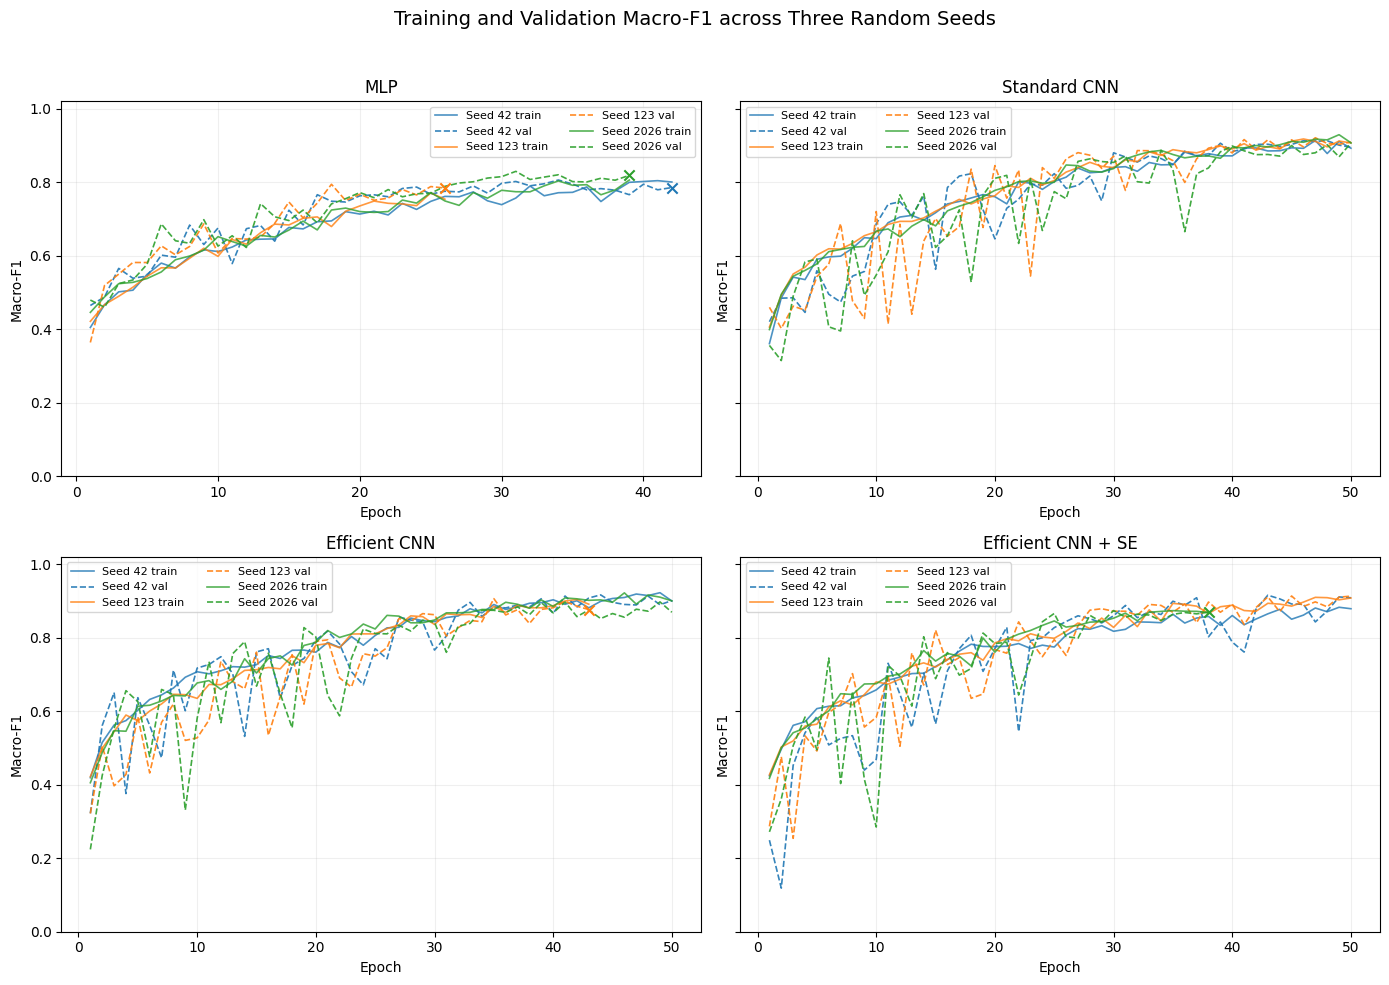

In [23]:
# ============================================================
# 6.5 Training Dynamics
# ============================================================

MODEL_ORDER = [
    "MLP",
    "Standard CNN",
    "Efficient CNN",
    "Efficient CNN + SE",
]


# ------------------------------------------------------------
# Reload saved training results
# ------------------------------------------------------------

training_results_path = (
    OUTPUT_DIR
    /
    "main_multi_seed_training_results.csv"
)

if not training_results_path.exists():
    raise FileNotFoundError(
        f"Training-results file not found: {training_results_path}"
    )

training_dynamics_results_df = pd.read_csv(
    training_results_path
)


# ------------------------------------------------------------
# Reload saved per-epoch histories
# ------------------------------------------------------------

training_dynamics_histories = {}

for model_name in MODEL_ORDER:

    safe_model_name = (
        model_name
        .lower()
        .replace(
            " + ",
            "_"
        )
        .replace(
            " ",
            "_"
        )
    )

    for seed in TRAINING_SEEDS:

        history_path = (
            MAIN_HISTORY_DIR
            /
            (
                f"{safe_model_name}"
                f"_seed_{seed}.csv"
            )
        )

        if not history_path.exists():
            raise FileNotFoundError(
                f"Training history not found: {history_path}"
            )

        training_dynamics_histories[
            (
                model_name,
                seed,
            )
        ] = pd.read_csv(
            history_path
        )


# ------------------------------------------------------------
# Plot training and validation trajectories
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
    sharey=True,
)

axes = axes.ravel()


for ax, model_name in zip(
    axes,
    MODEL_ORDER,
):

    for seed in TRAINING_SEEDS:

        history_df = (
            training_dynamics_histories[
                (
                    model_name,
                    seed,
                )
            ]
            .copy()
        )

        train_line, = ax.plot(
            history_df["Epoch"],
            history_df["Train_Macro_F1"],
            linewidth=1.2,
            alpha=0.8,
            label=f"Seed {seed} train",
        )

        seed_color = train_line.get_color()

        ax.plot(
            history_df["Epoch"],
            history_df["Validation_Macro_F1"],
            linewidth=1.2,
            linestyle="--",
            alpha=0.9,
            color=seed_color,
            label=f"Seed {seed} val",
        )


        # ----------------------------------------------------
        # Mark runs that stopped before the maximum budget
        # ----------------------------------------------------

        result_row = (
            training_dynamics_results_df[
                (
                    training_dynamics_results_df["Model"]
                    ==
                    model_name
                )
                &
                (
                    training_dynamics_results_df["Seed"]
                    ==
                    seed
                )
            ]
            .iloc[0]
        )

        stopped_early = (
            int(
                result_row[
                    "Epochs_Executed"
                ]
            )
            <
            int(
                result_row[
                    "Maximum_Epoch_Budget"
                ]
            )
        )

        if stopped_early:

            final_row = history_df.iloc[-1]

            ax.scatter(
                final_row["Epoch"],
                final_row["Validation_Macro_F1"],
                marker="x",
                s=55,
                linewidths=1.5,
                color=seed_color,
                zorder=5,
            )


    ax.set_title(
        model_name
    )

    ax.set_xlabel(
        "Epoch"
    )

    ax.set_ylabel(
        "Macro-F1"
    )

    ax.set_ylim(
        0.0,
        1.02,
    )

    ax.grid(
        alpha=0.2
    )

    ax.legend(
        fontsize=8,
        ncol=2,
    )


fig.suptitle(
    "Training and Validation Macro-F1 across Three Random Seeds",
    fontsize=14,
)

fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.96,
    ]
)


show_figure(
    fig,
    caption=(
        "Training and validation Macro-F1 trajectories "
        "across three seeds for the four architectures."
    ),
    filename="training_macro_f1_curves.png",
)

## 7. Model Evaluation

### 7.1 Final Held-Out Test Evaluation

The frozen checkpoints are evaluated once on the leakage-controlled test set. Macro-F1 is primary because class supports are unequal, while accuracy and balanced accuracy provide complementary evaluation perspectives (Sokolova and Lapalme, 2009).

In [24]:
# ============================================================
# 7.1 Final Held-Out Test Evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)


# ------------------------------------------------------------
# Fixed held-out test loader
#
# The test set is evaluated only after all architecture,
# optimisation and checkpoint decisions have been frozen.
# ------------------------------------------------------------

(
    _,
    _,
    final_test_loader,
) = make_main_loaders(
    seed=TRAINING_SEEDS[0],
    batch_size=BATCH_SIZE,
)


assert (
    len(final_test_loader.dataset)
    ==
    299
), (
    "Unexpected held-out test-set size."
)


# ------------------------------------------------------------
# Evaluate one frozen checkpoint
# ------------------------------------------------------------

def evaluate_test_checkpoint(
    model_name,
    seed,
    checkpoint_path,
):
    """
    Load one validation-selected checkpoint and evaluate it
    on the held-out leakage-controlled test partition.

    No model selection or parameter modification occurs here.
    """

    # --------------------------------------------------------
    # Rebuild model architecture
    # --------------------------------------------------------

    model = (
        MODEL_BUILDERS[
            model_name
        ]()
        .to(
            TRAINING_DEVICE
        )
    )


    # --------------------------------------------------------
    # Load frozen checkpoint
    #
    # Compatible with older PyTorch versions that do not
    # support the weights_only argument.
    # --------------------------------------------------------

    checkpoint = torch.load(
        checkpoint_path,
        map_location=TRAINING_DEVICE,
    )


    if (
        isinstance(
            checkpoint,
            dict,
        )
        and
        "model_state_dict"
        in checkpoint
    ):

        state_dict = checkpoint[
            "model_state_dict"
        ]

    else:

        state_dict = checkpoint


    model.load_state_dict(
        state_dict
    )


    model.eval()


    # --------------------------------------------------------
    # Prediction storage
    # --------------------------------------------------------

    true_targets = []

    predicted_targets = []

    predicted_probabilities = []

    image_paths = []


    # --------------------------------------------------------
    # Test inference
    # --------------------------------------------------------

    with torch.no_grad():

        for batch in final_test_loader:

            images = batch[
                "image"
            ].to(
                TRAINING_DEVICE,
                non_blocking=True,
            )


            targets = batch[
                "target"
            ].to(
                TRAINING_DEVICE,
                non_blocking=True,
            )


            logits = model(
                images
            )


            probabilities = torch.softmax(
                logits,
                dim=1,
            )


            predictions = torch.argmax(
                probabilities,
                dim=1,
            )


            true_targets.extend(
                targets
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


            predicted_targets.extend(
                predictions
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


            predicted_probabilities.extend(
                probabilities
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )


            image_paths.extend(
                list(
                    batch[
                        "path"
                    ]
                )
            )


    # --------------------------------------------------------
    # Convert accumulated results to arrays
    # --------------------------------------------------------

    true_targets = np.asarray(
        true_targets,
        dtype=int,
    )


    predicted_targets = np.asarray(
        predicted_targets,
        dtype=int,
    )


    predicted_probabilities = np.asarray(
        predicted_probabilities,
        dtype=np.float64,
    )


    # --------------------------------------------------------
    # Integrity checks
    # --------------------------------------------------------

    assert (
        len(
            true_targets
        )
        ==
        len(
            final_test_loader.dataset
        )
    )


    assert (
        len(
            predicted_targets
        )
        ==
        len(
            true_targets
        )
    )


    assert (
        predicted_probabilities.shape
        ==
        (
            len(
                true_targets
            ),
            len(
                CLASS_NAMES
            ),
        )
    )


    # --------------------------------------------------------
    # Overall metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        true_targets,
        predicted_targets,
    )


    balanced_accuracy = balanced_accuracy_score(
        true_targets,
        predicted_targets,
    )


    macro_precision = precision_score(
        true_targets,
        predicted_targets,
        average="macro",
        zero_division=0,
    )


    macro_recall = recall_score(
        true_targets,
        predicted_targets,
        average="macro",
        zero_division=0,
    )


    macro_f1 = f1_score(
        true_targets,
        predicted_targets,
        average="macro",
        zero_division=0,
    )


    # --------------------------------------------------------
    # Per-class metrics
    # --------------------------------------------------------

    class_indices = np.arange(
        len(
            CLASS_NAMES
        )
    )


    per_class_precision = precision_score(
        true_targets,
        predicted_targets,
        labels=class_indices,
        average=None,
        zero_division=0,
    )


    per_class_recall = recall_score(
        true_targets,
        predicted_targets,
        labels=class_indices,
        average=None,
        zero_division=0,
    )


    per_class_f1 = f1_score(
        true_targets,
        predicted_targets,
        labels=class_indices,
        average=None,
        zero_division=0,
    )


    confusion = confusion_matrix(
        true_targets,
        predicted_targets,
        labels=class_indices,
    )


    # --------------------------------------------------------
    # Overall result row
    # --------------------------------------------------------

    overall_result = {
        "Model":
            model_name,

        "Seed":
            int(
                seed
            ),

        "Accuracy":
            float(
                accuracy
            ),

        "Balanced_Accuracy":
            float(
                balanced_accuracy
            ),

        "Macro_Precision":
            float(
                macro_precision
            ),

        "Macro_Recall":
            float(
                macro_recall
            ),

        "Macro_F1":
            float(
                macro_f1
            ),
    }


    # --------------------------------------------------------
    # Per-class result rows
    # --------------------------------------------------------

    per_class_rows = []


    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):

        class_support = int(
            np.sum(
                true_targets
                ==
                class_index
            )
        )


        per_class_rows.append(
            {
                "Model":
                    model_name,

                "Seed":
                    int(
                        seed
                    ),

                "Class":
                    class_name,

                "Support":
                    class_support,

                "Precision":
                    float(
                        per_class_precision[
                            class_index
                        ]
                    ),

                "Recall":
                    float(
                        per_class_recall[
                            class_index
                        ]
                    ),

                "F1":
                    float(
                        per_class_f1[
                            class_index
                        ]
                    ),
            }
        )


    # --------------------------------------------------------
    # Image-level prediction rows
    # --------------------------------------------------------

    prediction_rows = []


    for index in range(
        len(
            true_targets
        )
    ):

        true_index = int(
            true_targets[
                index
            ]
        )


        predicted_index = int(
            predicted_targets[
                index
            ]
        )


        prediction_row = {
            "Model":
                model_name,

            "Seed":
                int(
                    seed
                ),

            "Path":
                image_paths[
                    index
                ],

            "True_Index":
                true_index,

            "True_Class":
                CLASS_NAMES[
                    true_index
                ],

            "Predicted_Index":
                predicted_index,

            "Predicted_Class":
                CLASS_NAMES[
                    predicted_index
                ],

            "Correct":
                bool(
                    true_index
                    ==
                    predicted_index
                ),
        }


        for class_index, class_name in enumerate(
            CLASS_NAMES
        ):

            prediction_row[
                f"Probability_{class_name}"
            ] = float(
                predicted_probabilities[
                    index,
                    class_index,
                ]
            )


        prediction_rows.append(
            prediction_row
        )


    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del model

    del checkpoint

    del state_dict


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return (
        overall_result,
        per_class_rows,
        prediction_rows,
        confusion,
    )


# ------------------------------------------------------------
# Evaluate all 12 frozen checkpoints in one final stage
# ------------------------------------------------------------

final_test_results = []

final_per_class_results = []

final_prediction_rows = []

final_confusion_matrices = {}


print(
    "\n"
    + "=" * 76
)

print(
    "FINAL HELD-OUT TEST STAGE"
)

print(
    "=" * 76
)

print(
    f"Test images : "
    f"{len(final_test_loader.dataset)}"
)

print(
    f"Checkpoints : "
    f"{len(main_training_results_df)}"
)

print(
    "=" * 76
)


for row in main_training_results_df.itertuples():

    model_name = row.Model

    seed = int(
        row.Seed
    )


    checkpoint_path = Path(
        row.Checkpoint
    )


    if not checkpoint_path.exists():

        raise FileNotFoundError(
            "Missing checkpoint: "
            f"{checkpoint_path}"
        )


    print(
        f"Evaluating "
        f"{model_name:20s} "
        f"| seed {seed}"
    )


    (
        overall_result,
        per_class_rows,
        prediction_rows,
        confusion,
    ) = evaluate_test_checkpoint(
        model_name=model_name,
        seed=seed,
        checkpoint_path=checkpoint_path,
    )


    final_test_results.append(
        overall_result
    )


    final_per_class_results.extend(
        per_class_rows
    )


    final_prediction_rows.extend(
        prediction_rows
    )


    final_confusion_matrices[
        (
            model_name,
            seed,
        )
    ] = confusion


# ------------------------------------------------------------
# Per-seed held-out test results
# ------------------------------------------------------------

final_test_results_df = pd.DataFrame(
    final_test_results
)


assert (
    len(
        final_test_results_df
    )
    ==
    12
), (
    "Expected 12 checkpoint evaluations."
)


show_table(
    final_test_results_df,
    caption=(
        "Held-out test performance for all "
        "twelve validation-selected checkpoints."
    ),
    filename=(
        "final_test_results_per_seed.csv"
    ),
    decimals=4,
)


final_test_results_df.to_csv(
    OUTPUT_DIR
    /
    "final_test_results_per_seed.csv",
    index=False,
)


# ------------------------------------------------------------
# Three-seed held-out test summary
# ------------------------------------------------------------

final_test_summary_df = (
    final_test_results_df
    .groupby(
        "Model",
        sort=False,
    )
    .agg(
        Macro_F1_Mean=(
            "Macro_F1",
            "mean",
        ),

        Macro_F1_SD=(
            "Macro_F1",
            "std",
        ),

        Accuracy_Mean=(
            "Accuracy",
            "mean",
        ),

        Accuracy_SD=(
            "Accuracy",
            "std",
        ),

        Balanced_Accuracy_Mean=(
            "Balanced_Accuracy",
            "mean",
        ),

        Balanced_Accuracy_SD=(
            "Balanced_Accuracy",
            "std",
        ),

        Macro_Precision_Mean=(
            "Macro_Precision",
            "mean",
        ),

        Macro_Precision_SD=(
            "Macro_Precision",
            "std",
        ),

        Macro_Recall_Mean=(
            "Macro_Recall",
            "mean",
        ),

        Macro_Recall_SD=(
            "Macro_Recall",
            "std",
        ),
    )
    .reset_index()
)


show_table(
    final_test_summary_df,
    caption=(
        "Three-seed held-out test summary "
        "for the four neural-network architectures."
    ),
    filename=(
        "final_test_summary.csv"
    ),
    decimals=4,
)


final_test_summary_df.to_csv(
    OUTPUT_DIR
    /
    "final_test_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# Detailed per-class results
# ------------------------------------------------------------

final_per_class_results_df = pd.DataFrame(
    final_per_class_results
)


final_per_class_results_df.to_csv(
    OUTPUT_DIR
    /
    "final_test_per_class_results.csv",
    index=False,
)


# ------------------------------------------------------------
# Detailed image-level predictions
# ------------------------------------------------------------

final_predictions_df = pd.DataFrame(
    final_prediction_rows
)


final_predictions_df.to_csv(
    OUTPUT_DIR
    /
    "final_test_predictions.csv",
    index=False,
)


# ------------------------------------------------------------
# Final ranking by primary metric
# ------------------------------------------------------------

final_test_ranking_df = (
    final_test_summary_df[
        [
            "Model",
            "Macro_F1_Mean",
            "Macro_F1_SD",
            "Accuracy_Mean",
            "Balanced_Accuracy_Mean",
        ]
    ]
    .sort_values(
        "Macro_F1_Mean",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


final_test_ranking_df.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(
            final_test_ranking_df
        ) + 1,
    ),
)


show_table(
    final_test_ranking_df,
    caption=(
        "Final model ranking by three-seed "
        "held-out test Macro-F1."
    ),
    filename=(
        "final_test_ranking.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Verify test class support
# ------------------------------------------------------------

test_support_df = (
    final_per_class_results_df[
        final_per_class_results_df[
            "Seed"
        ]
        ==
        TRAINING_SEEDS[0]
    ][
        [
            "Class",
            "Support",
        ]
    ]
    .drop_duplicates()
    .reset_index(
        drop=True
    )
)


show_table(
    test_support_df,
    caption=(
        "Class support in the held-out test partition."
    ),
    filename=(
        "held_out_test_class_support.csv"
    ),
    decimals=0,
)


assert (
    int(
        test_support_df[
            "Support"
        ].sum()
    )
    ==
    299
)


# ------------------------------------------------------------
# Final test-stage report
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 76
)

print(
    "FINAL HELD-OUT TEST EVALUATION COMPLETE"
)

print(
    "=" * 76
)


for row in final_test_summary_df.itertuples():

    print(
        f"{row.Model:20s} | "
        f"Macro-F1 = "
        f"{row.Macro_F1_Mean:.4f} "
        f"± {row.Macro_F1_SD:.4f} | "
        f"Accuracy = "
        f"{row.Accuracy_Mean:.4f} "
        f"± {row.Accuracy_SD:.4f} | "
        f"Balanced Acc = "
        f"{row.Balanced_Accuracy_Mean:.4f} "
        f"± {row.Balanced_Accuracy_SD:.4f}"
    )


print(
    "\nTest partition size        : "
    f"{len(final_test_loader.dataset)}"
)

print(
    "Checkpoints evaluated      : "
    f"{len(final_test_results_df)}"
)

print(
    "Training performed here    : 0"
)

print(
    "=" * 76
)


FINAL HELD-OUT TEST STAGE
Test images : 299
Checkpoints : 12
Evaluating MLP                  | seed 42
Evaluating MLP                  | seed 123
Evaluating MLP                  | seed 2026
Evaluating Standard CNN         | seed 42
Evaluating Standard CNN         | seed 123
Evaluating Standard CNN         | seed 2026
Evaluating Efficient CNN        | seed 42
Evaluating Efficient CNN        | seed 123
Evaluating Efficient CNN        | seed 2026
Evaluating Efficient CNN + SE   | seed 42
Evaluating Efficient CNN + SE   | seed 123
Evaluating Efficient CNN + SE   | seed 2026

Table 43. Held-out test performance for all twelve validation-selected checkpoints.


,Model,Seed,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1
0,MLP,42,0.8662,0.7835,0.8429,0.7835,0.8055
1,MLP,123,0.8696,0.7889,0.8396,0.7889,0.8076
2,MLP,2026,0.8796,0.8153,0.8348,0.8153,0.8239
3,Standard CNN,42,0.9130,0.8570,0.8669,0.8570,0.8557
4,Standard CNN,123,0.9197,0.8511,0.8919,0.8511,0.8662
5,Standard CNN,2026,0.8963,0.8540,0.8409,0.8540,0.8359
6,Efficient CNN,42,0.9197,0.8620,0.8667,0.8620,0.8629
7,Efficient CNN,123,0.8829,0.7914,0.8117,0.7914,0.8003
8,Efficient CNN,2026,0.9164,0.8415,0.8648,0.8415,0.8496
9,Efficient CNN + SE,42,0.8997,0.8244,0.8270,0.8244,0.8227



Table 44. Three-seed held-out test summary for the four neural-network architectures.


,Model,Macro_F1_Mean,Macro_F1_SD,Accuracy_Mean,Accuracy_SD,Balanced_Accuracy_Mean,Balanced_Accuracy_SD,Macro_Precision_Mean,Macro_Precision_SD,Macro_Recall_Mean,Macro_Recall_SD
0,MLP,0.8124,0.0100,0.8718,0.0070,0.7959,0.0170,0.8391,0.0041,0.7959,0.0170
1,Standard CNN,0.8526,0.0154,0.9097,0.0121,0.8540,0.0029,0.8666,0.0255,0.8540,0.0029
2,Efficient CNN,0.8376,0.0330,0.9064,0.0203,0.8316,0.0363,0.8477,0.0312,0.8316,0.0363
3,Efficient CNN + SE,0.8147,0.0098,0.8885,0.0102,0.8123,0.0259,0.8259,0.0135,0.8123,0.0259



Table 45. Final model ranking by three-seed held-out test Macro-F1.


,Rank,Model,Macro_F1_Mean,Macro_F1_SD,Accuracy_Mean,Balanced_Accuracy_Mean
0,1,Standard CNN,0.8526,0.0154,0.9097,0.8540
1,2,Efficient CNN,0.8376,0.0330,0.9064,0.8316
2,3,Efficient CNN + SE,0.8147,0.0098,0.8885,0.8123
3,4,MLP,0.8124,0.0100,0.8718,0.7959



Table 46. Class support in the held-out test partition.


,Class,Support
0,Hatchback,33
1,Other,73
2,Pickup,110
3,SUV,20
4,Sedan,63



FINAL HELD-OUT TEST EVALUATION COMPLETE
MLP                  | Macro-F1 = 0.8124 ± 0.0100 | Accuracy = 0.8718 ± 0.0070 | Balanced Acc = 0.7959 ± 0.0170
Standard CNN         | Macro-F1 = 0.8526 ± 0.0154 | Accuracy = 0.9097 ± 0.0121 | Balanced Acc = 0.8540 ± 0.0029
Efficient CNN        | Macro-F1 = 0.8376 ± 0.0330 | Accuracy = 0.9064 ± 0.0203 | Balanced Acc = 0.8316 ± 0.0363
Efficient CNN + SE   | Macro-F1 = 0.8147 ± 0.0098 | Accuracy = 0.8885 ± 0.0102 | Balanced Acc = 0.8123 ± 0.0259

Test partition size        : 299
Checkpoints evaluated      : 12
Training performed here    : 0


In [25]:
# ============================================================
# Final RQ2 Protocol-Level Performance Comparison
# ============================================================

current_standard_row = (
    final_test_summary_df.loc[
        final_test_summary_df["Model"]
        ==
        "Standard CNN"
    ]
    .iloc[0]
)


current_safe_macro_f1_mean = float(
    current_standard_row[
        "Macro_F1_Mean"
    ]
)


current_safe_macro_f1_sd = float(
    current_standard_row[
        "Macro_F1_SD"
    ]
)


FINAL_PROTOCOL_INFLATION = (
    naive_macro_f1_mean
    -
    current_safe_macro_f1_mean
)


final_protocol_comparison_df = pd.DataFrame(
    {
        "Protocol": [
            "Conventional image-level (duplicates retained)",
            "Leakage-controlled",
        ],

        "Macro_F1_Mean": [
            naive_macro_f1_mean,
            current_safe_macro_f1_mean,
        ],

        "Macro_F1_SD": [
            naive_macro_f1_sd,
            current_safe_macro_f1_sd,
        ],
    }
)


show_table(
    final_protocol_comparison_df,
    caption=(
        "Final Standard-CNN comparison between conventional "
        "and leakage-controlled evaluation protocols."
    ),
    filename=(
        "final_protocol_performance_comparison.csv"
    ),
    decimals=4,
)


print(
    "\n"
    + "=" * 72
)

print(
    "FINAL RQ2 PROTOCOL COMPARISON"
)

print(
    "=" * 72
)

print(
    "Conventional image-level Macro-F1 : "
    f"{naive_macro_f1_mean:.4f} "
    f"± {naive_macro_f1_sd:.4f}"
)

print(
    "Leakage-controlled Macro-F1       : "
    f"{current_safe_macro_f1_mean:.4f} "
    f"± {current_safe_macro_f1_sd:.4f}"
)

print(
    "\nObserved protocol-level inflation  : "
    f"{FINAL_PROTOCOL_INFLATION:+.4f}"
)

print(
    "=" * 72
)


Table 47. Final Standard-CNN comparison between conventional and leakage-controlled evaluation protocols.


,Protocol,Macro_F1_Mean,Macro_F1_SD
0,Conventional image-level (duplicates retained),0.9835,0.0017
1,Leakage-controlled,0.8526,0.0154



FINAL RQ2 PROTOCOL COMPARISON
Conventional image-level Macro-F1 : 0.9835 ± 0.0017
Leakage-controlled Macro-F1       : 0.8526 ± 0.0154

Observed protocol-level inflation  : +0.1309


Conventional image-level evaluation produced Macro-F1 = 0.9835 ± 0.0017 versus 0.8526 ± 0.0154 under leakage control, a difference of 0.1309 — a protocol-level contrast under the Section 4.8 caveat.

### 7.2 Per-Class Performance and Confusion Analysis



Table 48. Three-seed class-specific precision, recall and F1 on the held-out test partition.


,Model,Class,Support,Precision_Mean,Precision_SD,Recall_Mean,Recall_SD,F1_Mean,F1_SD
0,MLP,Hatchback,33,0.7059,0.0313,0.6061,0.0909,0.6499,0.0572
1,MLP,Other,73,0.9856,0.0001,0.9361,0.0079,0.9602,0.0042
2,MLP,Pickup,110,0.8703,0.0165,0.9333,0.0052,0.9006,0.0080
3,MLP,SUV,20,0.7829,0.0757,0.5833,0.0289,0.6672,0.0335
4,MLP,Sedan,63,0.8508,0.0511,0.9206,0.0000,0.8838,0.0274
5,Standard CNN,Hatchback,33,0.8649,0.0467,0.6465,0.0631,0.7391,0.0524
6,Standard CNN,Other,73,0.9772,0.0079,0.9772,0.0158,0.9771,0.0106
7,Standard CNN,Pickup,110,0.9472,0.0157,0.9697,0.0229,0.9580,0.0034
8,Standard CNN,SUV,20,0.6225,0.1922,0.7667,0.0289,0.6745,0.1056
9,Standard CNN,Sedan,63,0.9213,0.0255,0.9101,0.0601,0.9143,0.0206



Table 49. Mean held-out F1 by vehicle class and architecture.


Model,Class,Efficient CNN,Efficient CNN + SE,MLP,Standard CNN
0,Hatchback,0.7469,0.6665,0.6499,0.7391
1,Other,0.9770,0.9725,0.9602,0.9771
2,Pickup,0.9560,0.9531,0.9006,0.9580
3,SUV,0.5943,0.5976,0.6672,0.6745
4,Sedan,0.9137,0.8837,0.8838,0.9143



Table 50. Held-out class-specific F1 reported as mean ± standard deviation across three seeds.


Model,Class,Efficient CNN,Efficient CNN + SE,MLP,Standard CNN
0,Hatchback,0.7469 ± 0.0535,0.6665 ± 0.0277,0.6499 ± 0.0572,0.7391 ± 0.0524
1,Other,0.9770 ± 0.0106,0.9725 ± 0.0002,0.9602 ± 0.0042,0.9771 ± 0.0106
2,Pickup,0.9560 ± 0.0151,0.9531 ± 0.0231,0.9006 ± 0.0080,0.9580 ± 0.0034
3,SUV,0.5943 ± 0.0724,0.5976 ± 0.0077,0.6672 ± 0.0335,0.6745 ± 0.1056
4,Sedan,0.9137 ± 0.0156,0.8837 ± 0.0136,0.8838 ± 0.0274,0.9143 ± 0.0206



Figure 9. Mean row-normalised confusion matrices across three seeds for the four architectures.


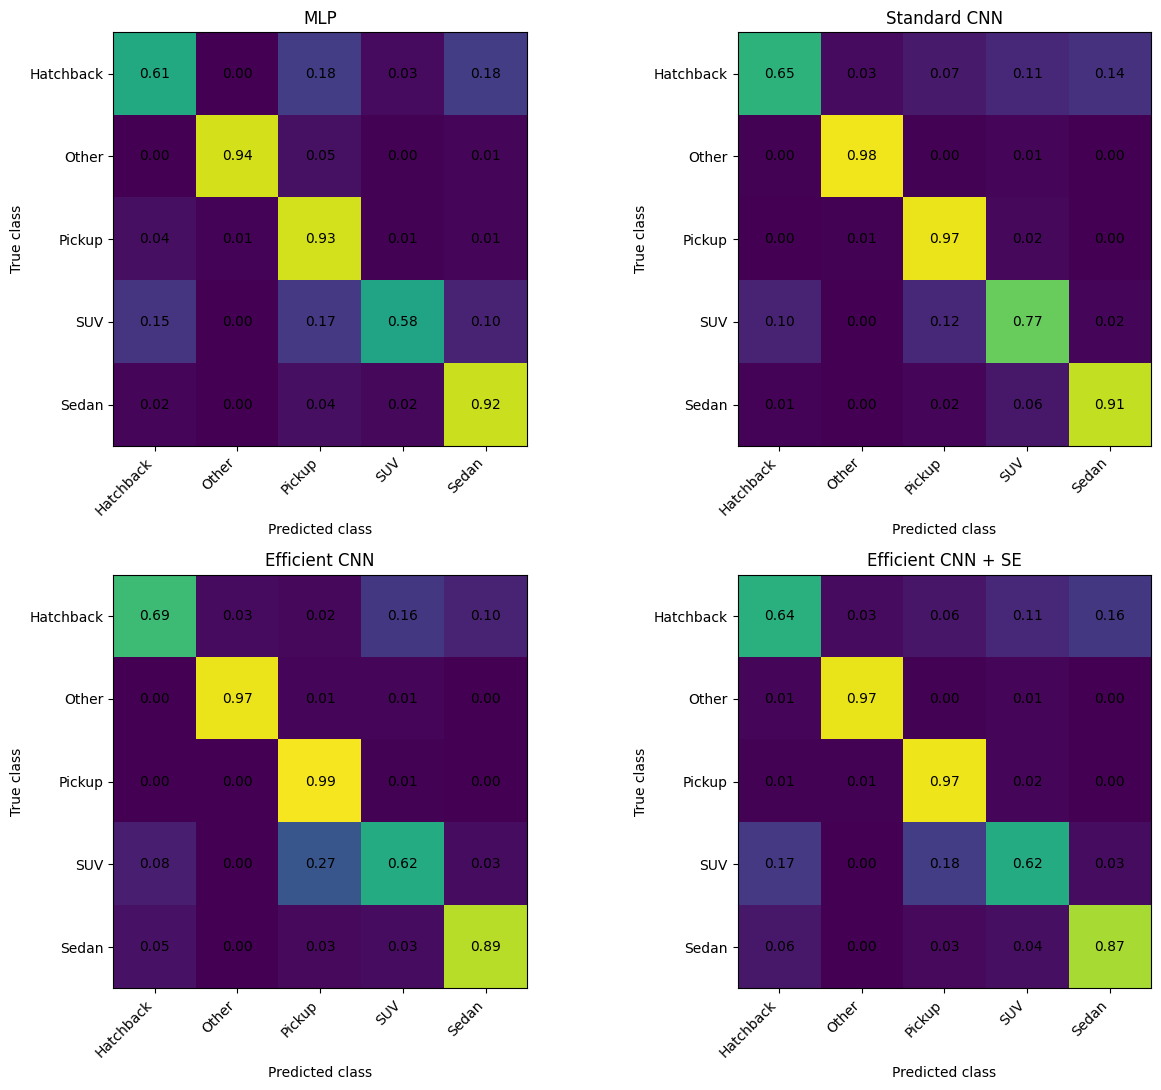


Table 51. Largest mean off-diagonal confusion for each architecture.


,Model,True_Class,Most_Confused_With,Mean_Confusion_Rate
0,MLP,Hatchback,Pickup,0.1818
1,Standard CNN,Hatchback,Sedan,0.1414
2,Efficient CNN,SUV,Pickup,0.2667
3,Efficient CNN + SE,SUV,Pickup,0.1833



Table 52. Highest- and lowest-F1 test classes for each architecture.


,Model,Best_Class,Best_Class_F1,Weakest_Class,Weakest_Class_F1
0,MLP,Other,0.9602,Hatchback,0.6499
1,Standard CNN,Other,0.9771,SUV,0.6745
2,Efficient CNN,Other,0.9770,SUV,0.5943
3,Efficient CNN + SE,Other,0.9725,SUV,0.5976



PER-CLASS TEST ANALYSIS COMPLETE
MLP                  | best: Other      (0.9602) | weakest: Hatchback  (0.6499)
Standard CNN         | best: Other      (0.9771) | weakest: SUV        (0.6745)
Efficient CNN        | best: Other      (0.9770) | weakest: SUV        (0.5943)
Efficient CNN + SE   | best: Other      (0.9725) | weakest: SUV        (0.5976)


In [26]:
# ============================================================
# 7.2 Per-Class Performance and Confusion Analysis
# ============================================================

# ------------------------------------------------------------
# Three-seed per-class summary
# ------------------------------------------------------------

per_class_summary_df = (
    final_per_class_results_df
    .groupby(
        [
            "Model",
            "Class",
        ],
        sort=False,
    )
    .agg(
        Support=(
            "Support",
            "first",
        ),

        Precision_Mean=(
            "Precision",
            "mean",
        ),

        Precision_SD=(
            "Precision",
            "std",
        ),

        Recall_Mean=(
            "Recall",
            "mean",
        ),

        Recall_SD=(
            "Recall",
            "std",
        ),

        F1_Mean=(
            "F1",
            "mean",
        ),

        F1_SD=(
            "F1",
            "std",
        ),
    )
    .reset_index()
)


show_table(
    per_class_summary_df,
    caption=(
        "Three-seed class-specific precision, recall and F1 "
        "on the held-out test partition."
    ),
    filename=(
        "final_test_per_class_summary.csv"
    ),
    decimals=4,
)


per_class_summary_df.to_csv(
    OUTPUT_DIR
    /
    "final_test_per_class_summary.csv",
    index=False,
)


# ------------------------------------------------------------
# Compact F1 comparison table
# ------------------------------------------------------------

per_class_f1_table = (
    per_class_summary_df
    .pivot(
        index="Class",
        columns="Model",
        values="F1_Mean",
    )
    .reindex(
        CLASS_NAMES
    )
    .reset_index()
)


show_table(
    per_class_f1_table,
    caption=(
        "Mean held-out F1 by vehicle class and architecture."
    ),
    filename=(
        "final_test_per_class_f1_comparison.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Add mean ± SD strings for compact reporting
# ------------------------------------------------------------

per_class_f1_report_df = (
    per_class_summary_df
    .copy()
)


per_class_f1_report_df[
    "F1_Mean_SD"
] = (
    per_class_f1_report_df.apply(
        lambda row:
            f"{row['F1_Mean']:.4f} ± "
            f"{row['F1_SD']:.4f}",
        axis=1,
    )
)


per_class_f1_report_table = (
    per_class_f1_report_df
    .pivot(
        index="Class",
        columns="Model",
        values="F1_Mean_SD",
    )
    .reindex(
        CLASS_NAMES
    )
    .reset_index()
)


show_table(
    per_class_f1_report_table,
    caption=(
        "Held-out class-specific F1 reported as "
        "mean ± standard deviation across three seeds."
    ),
    filename=(
        "final_test_per_class_f1_mean_sd.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Mean row-normalised confusion matrix for each model
# ------------------------------------------------------------

mean_normalised_confusions = {}


for model_name in MODEL_BUILDERS.keys():

    seed_matrices = []


    for seed in TRAINING_SEEDS:

        confusion = (
            final_confusion_matrices[
                (
                    model_name,
                    seed,
                )
            ]
            .astype(
                np.float64
            )
        )


        row_totals = (
            confusion.sum(
                axis=1,
                keepdims=True,
            )
        )


        normalised = np.divide(
            confusion,
            row_totals,
            out=np.zeros_like(
                confusion,
                dtype=np.float64,
            ),
            where=(
                row_totals
                !=
                0
            ),
        )


        seed_matrices.append(
            normalised
        )


    mean_normalised_confusions[
        model_name
    ] = np.mean(
        np.stack(
            seed_matrices,
            axis=0,
        ),
        axis=0,
    )


# ------------------------------------------------------------
# Save each averaged confusion matrix
# ------------------------------------------------------------

for model_name, matrix in (
    mean_normalised_confusions.items()
):

    safe_name = (
        model_name
        .lower()
        .replace(
            " + ",
            "_plus_"
        )
        .replace(
            " ",
            "_"
        )
    )


    matrix_df = pd.DataFrame(
        matrix,
        index=CLASS_NAMES,
        columns=CLASS_NAMES,
    )


    matrix_df.to_csv(
        OUTPUT_DIR
        /
        (
            f"{safe_name}"
            "_mean_normalised_confusion.csv"
        )
    )


# ------------------------------------------------------------
# Confusion-matrix figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        13,
        11,
    ),
)


axes = axes.ravel()


for axis, model_name in zip(
    axes,
    MODEL_BUILDERS.keys(),
):

    matrix = (
        mean_normalised_confusions[
            model_name
        ]
    )


    image = axis.imshow(
        matrix,
        vmin=0,
        vmax=1,
    )


    axis.set_title(
        model_name
    )


    axis.set_xticks(
        np.arange(
            len(
                CLASS_NAMES
            )
        )
    )

    axis.set_yticks(
        np.arange(
            len(
                CLASS_NAMES
            )
        )
    )


    axis.set_xticklabels(
        CLASS_NAMES,
        rotation=45,
        ha="right",
    )


    axis.set_yticklabels(
        CLASS_NAMES
    )


    axis.set_xlabel(
        "Predicted class"
    )

    axis.set_ylabel(
        "True class"
    )


    for row_index in range(
        len(
            CLASS_NAMES
        )
    ):

        for column_index in range(
            len(
                CLASS_NAMES
            )
        ):

            axis.text(
                column_index,
                row_index,
                (
                    f"{matrix[row_index, column_index]:.2f}"
                ),
                ha="center",
                va="center",
            )


fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Mean row-normalised confusion matrices across "
        "three seeds for the four architectures."
    ),
    filename=(
        "final_test_mean_normalised_confusion_matrices.png"
    ),
)


# ------------------------------------------------------------
# Identify strongest off-diagonal confusion for each model
# ------------------------------------------------------------

confusion_error_rows = []


for model_name, matrix in (
    mean_normalised_confusions.items()
):

    off_diagonal = (
        matrix.copy()
    )


    np.fill_diagonal(
        off_diagonal,
        -np.inf,
    )


    true_index, predicted_index = (
        np.unravel_index(
            np.argmax(
                off_diagonal
            ),
            off_diagonal.shape,
        )
    )


    confusion_error_rows.append(
        {
            "Model":
                model_name,

            "True_Class":
                CLASS_NAMES[
                    true_index
                ],

            "Most_Confused_With":
                CLASS_NAMES[
                    predicted_index
                ],

            "Mean_Confusion_Rate":
                float(
                    matrix[
                        true_index,
                        predicted_index,
                    ]
                ),
        }
    )


strongest_confusions_df = pd.DataFrame(
    confusion_error_rows
)


show_table(
    strongest_confusions_df,
    caption=(
        "Largest mean off-diagonal confusion "
        "for each architecture."
    ),
    filename=(
        "strongest_class_confusions.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Best and weakest class by mean F1 for each model
# ------------------------------------------------------------

class_extremes_rows = []


for model_name in MODEL_BUILDERS.keys():

    model_rows = (
        per_class_summary_df[
            per_class_summary_df[
                "Model"
            ]
            ==
            model_name
        ]
        .copy()
    )


    best_row = (
        model_rows.loc[
            model_rows[
                "F1_Mean"
            ]
            .idxmax()
        ]
    )


    weakest_row = (
        model_rows.loc[
            model_rows[
                "F1_Mean"
            ]
            .idxmin()
        ]
    )


    class_extremes_rows.append(
        {
            "Model":
                model_name,

            "Best_Class":
                best_row[
                    "Class"
                ],

            "Best_Class_F1":
                float(
                    best_row[
                        "F1_Mean"
                    ]
                ),

            "Weakest_Class":
                weakest_row[
                    "Class"
                ],

            "Weakest_Class_F1":
                float(
                    weakest_row[
                        "F1_Mean"
                    ]
                ),
        }
    )


class_extremes_df = pd.DataFrame(
    class_extremes_rows
)


show_table(
    class_extremes_df,
    caption=(
        "Highest- and lowest-F1 test classes "
        "for each architecture."
    ),
    filename=(
        "per_model_class_extremes.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 76
)

print(
    "PER-CLASS TEST ANALYSIS COMPLETE"
)

print(
    "=" * 76
)


for row in class_extremes_df.itertuples():

    print(
        f"{row.Model:20s} | "
        f"best: {row.Best_Class:10s} "
        f"({row.Best_Class_F1:.4f}) | "
        f"weakest: {row.Weakest_Class:10s} "
        f"({row.Weakest_Class_F1:.4f})"
    )


print(
    "=" * 76
)

`Other` was strongest across CNNs, while SUV remained weakest: F1 = 0.6745 for Standard CNN, 0.5943 for Efficient CNN and 0.5976 for Efficient CNN + SE. With only 20 SUV test images, these class-level differences require cautious interpretation. Efficient CNN's largest mean confusion was SUV → Pickup (0.2667), while Standard CNN's was Hatchback → Sedan (0.1414).


### 7.3 Paired Bootstrap Uncertainty

A paired, class-stratified group bootstrap with 2,000 replicates resamples leakage-containment groups within class while preserving identical samples across models. Macro-F1 is averaged across three seeds, so intervals represent held-out group-composition uncertainty only, not retraining variability; substantial seed variation in the Efficient CNN therefore limits claims of stable equivalence (Efron and Tibshirani, 1986).

Test images          : 299
Test leakage groups  : 279

Table 53. Paired 2,000-replicate class-stratified group-bootstrap uncertainty for the three architectural contrasts.


,Comparison,Model_A,Model_B,Difference_B_minus_A,CI_95_Lower,CI_95_Upper,P_B_Greater_A
0,MLP → Standard CNN,MLP,Standard CNN,0.0403,0.0022,0.0846,0.9810
1,Standard CNN → Efficient CNN,Standard CNN,Efficient CNN,-0.0150,-0.0448,0.0166,0.1855
2,Efficient CNN → Efficient CNN + SE,Efficient CNN,Efficient CNN + SE,-0.0229,-0.0549,0.0045,0.0520



Figure 10. Paired class-stratified group-bootstrap distributions of Macro-F1 differences across held-out leakage-containment groups.


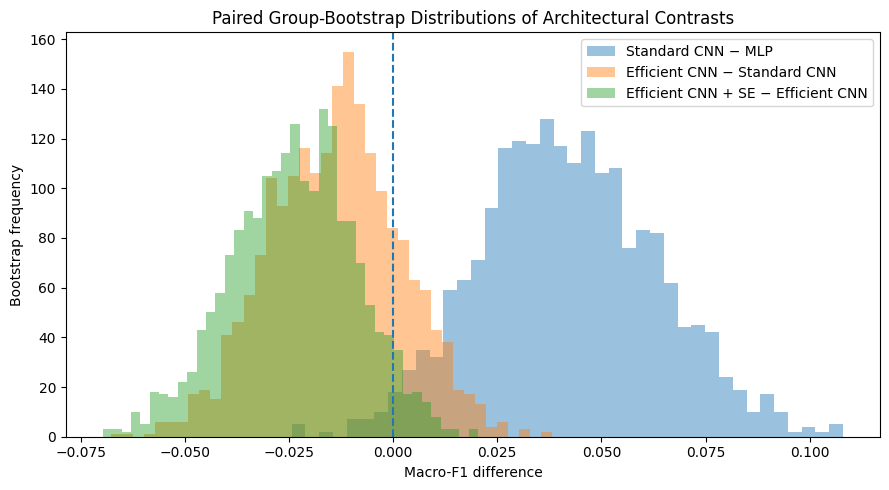


PAIRED CLASS-STRATIFIED GROUP BOOTSTRAP UNCERTAINTY
MLP → Standard CNN                          | Δ = +0.0403 | 95% CI [+0.0022, +0.0846] | P(B>A) = 0.981
Standard CNN → Efficient CNN                | Δ = -0.0150 | 95% CI [-0.0448, +0.0166] | P(B>A) = 0.185
Efficient CNN → Efficient CNN + SE          | Δ = -0.0229 | 95% CI [-0.0549, +0.0045] | P(B>A) = 0.052

Bootstrap iterations : 2,000
Test images          : 299
Test leakage groups  : 279
Uncertainty source   : paired class-stratified leakage-group resampling
Training uncertainty : conditional on the three completed seeds


In [27]:
# ============================================================
# 7.3 Paired, Class-Stratified Group Bootstrap Uncertainty
# ============================================================

BOOTSTRAP_ITERATIONS = 2000
BOOTSTRAP_SEED = 42


# ------------------------------------------------------------
# Architectural contrasts
#
# Difference is always:
#
#     B - A
# ------------------------------------------------------------

BOOTSTRAP_COMPARISONS = [
    (
        "MLP",
        "Standard CNN",
    ),
    (
        "Standard CNN",
        "Efficient CNN",
    ),
    (
        "Efficient CNN",
        "Efficient CNN + SE",
    ),
]


# ------------------------------------------------------------
# Build a common image order
# ------------------------------------------------------------

reference_predictions = (
    final_predictions_df[
        (
            final_predictions_df["Model"]
            ==
            "MLP"
        )
        &
        (
            final_predictions_df["Seed"]
            ==
            TRAINING_SEEDS[0]
        )
    ]
    .copy()
    .sort_values(
        "Path"
    )
    .reset_index(
        drop=True
    )
)


REFERENCE_PATHS = (
    reference_predictions[
        "Path"
    ]
    .to_numpy()
)


REFERENCE_TARGETS = (
    reference_predictions[
        "True_Index"
    ]
    .to_numpy(
        dtype=int
    )
)


N_TEST = len(
    REFERENCE_PATHS
)


assert (
    N_TEST
    ==
    299
)


# ------------------------------------------------------------
# Align leakage-containment groups with the common test order
# ------------------------------------------------------------

bootstrap_group_lookup_df = (
    test_df[
        [
            "path",
            "leakage_group_id",
        ]
    ]
    .copy()
)

bootstrap_group_lookup_df[
    "Path"
] = (
    bootstrap_group_lookup_df[
        "path"
    ]
    .astype(str)
)


reference_group_df = pd.DataFrame(
    {
        "Path": REFERENCE_PATHS,
        "True_Index": REFERENCE_TARGETS,
    }
)


reference_group_df = (
    reference_group_df
    .merge(
        bootstrap_group_lookup_df[
            [
                "Path",
                "leakage_group_id",
            ]
        ],
        on="Path",
        how="left",
        validate="one_to_one",
        sort=False,
    )
)


assert (
    reference_group_df[
        "leakage_group_id"
    ]
    .notna()
    .all()
)


assert (
    reference_group_df[
        "Path"
    ]
    .to_numpy()
    ==
    REFERENCE_PATHS
).all()


# Every leakage group must contain only one true class.
group_target_counts = (
    reference_group_df
    .groupby(
        "leakage_group_id"
    )[
        "True_Index"
    ]
    .nunique()
)


assert (
    group_target_counts
    ==
    1
).all()


# Image indices belonging to each leakage group.
group_to_indices = {
    group_id:
        group_frame.index.to_numpy(
            dtype=int
        )

    for group_id, group_frame
    in reference_group_df.groupby(
        "leakage_group_id",
        sort=False,
    )
}


# Leakage groups separated by true class for stratified
# group-level bootstrap sampling.
groups_by_class = {}

for class_index in range(
    len(CLASS_NAMES)
):

    class_group_ids = (
        reference_group_df.loc[
            reference_group_df[
                "True_Index"
            ]
            ==
            class_index,
            "leakage_group_id",
        ]
        .drop_duplicates()
        .to_numpy()
    )

    assert (
        len(class_group_ids)
        >
        0
    )

    groups_by_class[
        class_index
    ] = class_group_ids


N_TEST_GROUPS = (
    reference_group_df[
        "leakage_group_id"
    ]
    .nunique()
)


print(
    f"Test images          : {N_TEST:,}"
)

print(
    f"Test leakage groups  : {N_TEST_GROUPS:,}"
)


# ------------------------------------------------------------
# Align predictions from every model / seed to the same images
# ------------------------------------------------------------

prediction_store = {}


for model_name in MODEL_BUILDERS.keys():

    prediction_store[
        model_name
    ] = {}


    for seed in TRAINING_SEEDS:

        subset = (
            final_predictions_df[
                (
                    final_predictions_df[
                        "Model"
                    ]
                    ==
                    model_name
                )
                &
                (
                    final_predictions_df[
                        "Seed"
                    ]
                    ==
                    seed
                )
            ]
            .copy()
            .sort_values(
                "Path"
            )
            .reset_index(
                drop=True
            )
        )


        assert (
            len(
                subset
            )
            ==
            N_TEST
        )


        assert np.array_equal(
            subset[
                "Path"
            ].to_numpy(),
            REFERENCE_PATHS,
        )


        assert np.array_equal(
            subset[
                "True_Index"
            ].to_numpy(
                dtype=int
            ),
            REFERENCE_TARGETS,
        )


        prediction_store[
            model_name
        ][
            seed
        ] = (
            subset[
                "Predicted_Index"
            ]
            .to_numpy(
                dtype=int
            )
        )


# ------------------------------------------------------------
# Helper:
# mean Macro-F1 across the three trained seeds
# for one bootstrap sample
# ------------------------------------------------------------

def bootstrap_model_macro_f1(
    model_name,
    sampled_indices,
):
    """
    Calculate Macro-F1 independently for each seed and then
    average across the three seeds.
    """

    sampled_targets = (
        REFERENCE_TARGETS[
            sampled_indices
        ]
    )


    seed_scores = []


    for seed in TRAINING_SEEDS:

        sampled_predictions = (
            prediction_store[
                model_name
            ][
                seed
            ][
                sampled_indices
            ]
        )


        score = f1_score(
            sampled_targets,
            sampled_predictions,
            labels=np.arange(
                len(
                    CLASS_NAMES
                )
            ),
            average="macro",
            zero_division=0,
        )


        seed_scores.append(
            float(
                score
            )
        )


    return float(
        np.mean(
            seed_scores
        )
    )


# ------------------------------------------------------------
# Point estimates from the complete held-out test set
# ------------------------------------------------------------

test_macro_f1_lookup = (
    final_test_summary_df
    .set_index(
        "Model"
    )[
        "Macro_F1_Mean"
    ]
    .to_dict()
)


# ------------------------------------------------------------
# Paired, class-stratified leakage-group bootstrap
# ------------------------------------------------------------

bootstrap_rng = np.random.default_rng(
    BOOTSTRAP_SEED
)


bootstrap_difference_store = {
    (
        model_a,
        model_b,
    ):
        np.empty(
            BOOTSTRAP_ITERATIONS,
            dtype=np.float64,
        )

    for model_a, model_b
    in BOOTSTRAP_COMPARISONS
}


required_models = {
    model_name

    for comparison
    in BOOTSTRAP_COMPARISONS

    for model_name
    in comparison
}


for bootstrap_index in range(
    BOOTSTRAP_ITERATIONS
):

    # The SAME sampled leakage groups are used for all models.
    # Groups are resampled with replacement within each class,
    # and every image in a sampled group enters together.
    sampled_group_ids = []


    for class_index in range(
        len(CLASS_NAMES)
    ):

        class_group_ids = (
            groups_by_class[
                class_index
            ]
        )


        sampled_class_groups = (
            bootstrap_rng.choice(
                class_group_ids,
                size=len(
                    class_group_ids
                ),
                replace=True,
            )
        )


        sampled_group_ids.extend(
            sampled_class_groups.tolist()
        )


    sampled_indices = np.concatenate(
        [
            group_to_indices[
                group_id
            ]

            for group_id
            in sampled_group_ids
        ]
    )


    sampled_model_scores = {}


    for model_name in required_models:

        sampled_model_scores[
            model_name
        ] = bootstrap_model_macro_f1(
            model_name,
            sampled_indices,
        )


    for model_a, model_b in (
        BOOTSTRAP_COMPARISONS
    ):

        bootstrap_difference_store[
            (
                model_a,
                model_b,
            )
        ][
            bootstrap_index
        ] = (
            sampled_model_scores[
                model_b
            ]
            -
            sampled_model_scores[
                model_a
            ]
        )


# ------------------------------------------------------------
# Summarise bootstrap distributions
# ------------------------------------------------------------

bootstrap_summary_rows = []


for model_a, model_b in (
    BOOTSTRAP_COMPARISONS
):

    differences = (
        bootstrap_difference_store[
            (
                model_a,
                model_b,
            )
        ]
    )


    point_difference = (
        float(
            test_macro_f1_lookup[
                model_b
            ]
        )
        -
        float(
            test_macro_f1_lookup[
                model_a
            ]
        )
    )


    lower_ci = float(
        np.percentile(
            differences,
            2.5,
        )
    )


    upper_ci = float(
        np.percentile(
            differences,
            97.5,
        )
    )


    probability_b_greater_a = float(
        np.mean(
            differences
            >
            0
        )
    )


    bootstrap_summary_rows.append(
        {
            "Comparison":
                (
                    f"{model_a} → "
                    f"{model_b}"
                ),

            "Model_A":
                model_a,

            "Model_B":
                model_b,

            "Difference_B_minus_A":
                point_difference,

            "CI_95_Lower":
                lower_ci,

            "CI_95_Upper":
                upper_ci,

            "P_B_Greater_A":
                probability_b_greater_a,
        }
    )


bootstrap_summary_df = pd.DataFrame(
    bootstrap_summary_rows
)


show_table(
    bootstrap_summary_df,
    caption=(
        "Paired 2,000-replicate class-stratified group-bootstrap "
        "uncertainty for the three architectural contrasts."
    ),
    filename=(
        "paired_bootstrap_architecture_comparisons.csv"
    ),
    decimals=4,
)


bootstrap_summary_df.to_csv(
    OUTPUT_DIR
    /
    "paired_bootstrap_architecture_comparisons.csv",
    index=False,
)


# ------------------------------------------------------------
# Save bootstrap replicate distributions
# ------------------------------------------------------------

bootstrap_distributions_df = pd.DataFrame(
    {
        (
            f"{model_a}_to_{model_b}"
            .replace(
                " + ",
                "_plus_"
            )
            .replace(
                " ",
                "_"
            )
        ):
            bootstrap_difference_store[
                (
                    model_a,
                    model_b,
                )
            ]

        for model_a, model_b
        in BOOTSTRAP_COMPARISONS
    }
)


bootstrap_distributions_df.to_csv(
    OUTPUT_DIR
    /
    "paired_bootstrap_difference_distributions.csv",
    index=False,
)


# ------------------------------------------------------------
# Distribution plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        9,
        5,
    )
)


for model_a, model_b in (
    BOOTSTRAP_COMPARISONS
):

    differences = (
        bootstrap_difference_store[
            (
                model_a,
                model_b,
            )
        ]
    )


    ax.hist(
        differences,
        bins=40,
        alpha=0.45,
        label=(
            f"{model_b} − {model_a}"
        ),
    )


ax.axvline(
    0,
    linestyle="--",
)


ax.set_xlabel(
    "Macro-F1 difference"
)

ax.set_ylabel(
    "Bootstrap frequency"
)

ax.set_title(
    "Paired Group-Bootstrap Distributions of Architectural Contrasts"
)

ax.legend()


fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Paired class-stratified group-bootstrap distributions "
        "of Macro-F1 differences across held-out leakage-containment groups."
    ),
    filename=(
        "paired_bootstrap_difference_distributions.png"
    ),
)


# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 82
)

print(
    "PAIRED CLASS-STRATIFIED GROUP BOOTSTRAP UNCERTAINTY"
)

print(
    "=" * 82
)


for row in bootstrap_summary_df.itertuples():

    print(
        f"{row.Comparison:43s} | "
        f"Δ = {row.Difference_B_minus_A:+.4f} | "
        f"95% CI "
        f"[{row.CI_95_Lower:+.4f}, "
        f"{row.CI_95_Upper:+.4f}] | "
        f"P(B>A) = "
        f"{row.P_B_Greater_A:.3f}"
    )


print(
    "\nBootstrap iterations : "
    f"{BOOTSTRAP_ITERATIONS:,}"
)

print(
    f"Test images          : "
    f"{N_TEST}"
)

print(
    f"Test leakage groups  : "
    f"{N_TEST_GROUPS}"
)

print(
    "Uncertainty source   : "
    "paired class-stratified leakage-group resampling"
)

print(
    "Training uncertainty : "
    "conditional on the three completed seeds"
)

print(
    "=" * 82
)

### 7.4 Computational Efficiency and Deployment Trade-off

Relative to the Standard CNN, the Efficient CNN reduced trainable parameters by 87.24% and MACs by 81.67%. In the executed benchmark, batch-one latency decreased by 8.49% on CPU and 18.32% on GPU, while mean Macro-F1 was 0.0150 lower. Adding SE left MACs almost unchanged but increased measured latency, showing that operation counts alone do not determine deployment speed.

In [28]:
# ============================================================
# 7.4 Computational Efficiency and Deployment Trade-off
# ============================================================

# ------------------------------------------------------------
# Benchmark configuration
# ------------------------------------------------------------

LATENCY_SEED = 42

CPU_WARMUP_RUNS = 20
CPU_TIMED_RUNS = 100

GPU_WARMUP_RUNS = 30
GPU_TIMED_RUNS = 150


# ------------------------------------------------------------
# Load one representative frozen checkpoint
# ------------------------------------------------------------

def load_frozen_model(
    model_name,
    seed,
    device,
):
    """
    Load one validation-selected checkpoint for efficiency
    measurement.
    """

    matching_rows = (
        main_training_results_df[
            (
                main_training_results_df["Model"]
                ==
                model_name
            )
            &
            (
                main_training_results_df["Seed"]
                ==
                seed
            )
        ]
    )


    if len(matching_rows) != 1:

        raise RuntimeError(
            f"Expected exactly one checkpoint for "
            f"{model_name}, seed {seed}."
        )


    checkpoint_path = Path(
        matching_rows.iloc[0][
            "Checkpoint"
        ]
    )


    if not checkpoint_path.exists():

        raise FileNotFoundError(
            checkpoint_path
        )


    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
    )


    if (
        isinstance(
            checkpoint,
            dict,
        )
        and
        "model_state_dict"
        in checkpoint
    ):

        state_dict = checkpoint[
            "model_state_dict"
        ]

    else:

        state_dict = checkpoint


    model = (
        MODEL_BUILDERS[
            model_name
        ]()
        .to(
            device
        )
    )


    model.load_state_dict(
        state_dict
    )


    # IMPORTANT:
    # BatchNorm and Dropout must use inference behaviour.
    model.eval()


    return (
        model,
        checkpoint_path,
    )


# ------------------------------------------------------------
# Parameter count
# ------------------------------------------------------------

def count_trainable_parameters(
    model,
):

    return int(
        sum(
            parameter.numel()

            for parameter
            in model.parameters()

            if parameter.requires_grad
        )
    )


# ------------------------------------------------------------
# MAC counting
#
# Counts Conv2d and Linear multiply-accumulate operations.
#
# Pooling, activation, BatchNorm and elementwise operations
# are excluded from this architecture-level MAC estimate.
# ------------------------------------------------------------

def count_model_macs(
    model,
    input_shape=(
        1,
        3,
        TARGET_SIZE,
        TARGET_SIZE,
    ),
):
    """
    Count Conv2d and Linear MACs using forward hooks.

    The model is temporarily switched to evaluation mode so
    BatchNorm layers can process a batch of one safely.
    """

    mac_counter = {
        "total": 0
    }


    hooks = []


    # Preserve the model's original mode.
    original_training_state = (
        model.training
    )


    # MAC measurement is inference-only.
    model.eval()


    def conv_hook(
        module,
        inputs,
        output,
    ):

        if isinstance(
            module.kernel_size,
            tuple,
        ):

            kernel_height = (
                module.kernel_size[0]
            )

            kernel_width = (
                module.kernel_size[1]
            )

        else:

            kernel_height = (
                module.kernel_size
            )

            kernel_width = (
                module.kernel_size
            )


        operations_per_output = (
            kernel_height
            *
            kernel_width
            *
            (
                module.in_channels
                /
                module.groups
            )
        )


        output_elements = (
            output.numel()
        )


        mac_counter[
            "total"
        ] += int(
            output_elements
            *
            operations_per_output
        )


    def linear_hook(
        module,
        inputs,
        output,
    ):

        output_elements = (
            output.numel()
        )


        mac_counter[
            "total"
        ] += int(
            output_elements
            *
            module.in_features
        )


    try:

        for module in model.modules():

            if isinstance(
                module,
                torch.nn.Conv2d,
            ):

                hooks.append(
                    module.register_forward_hook(
                        conv_hook
                    )
                )


            elif isinstance(
                module,
                torch.nn.Linear,
            ):

                hooks.append(
                    module.register_forward_hook(
                        linear_hook
                    )
                )


        dummy_input = torch.zeros(
            input_shape,
            dtype=torch.float32,
            device=next(
                model.parameters()
            ).device,
        )


        with torch.no_grad():

            model(
                dummy_input
            )


    finally:

        # Always remove hooks.
        for hook in hooks:

            hook.remove()


        # Restore original mode.
        model.train(
            original_training_state
        )


    return int(
        mac_counter[
            "total"
        ]
    )


# ------------------------------------------------------------
# Checkpoint-size measurement across all three seeds
# ------------------------------------------------------------

def checkpoint_size_statistics(
    model_name,
):

    model_rows = (
        main_training_results_df[
            main_training_results_df[
                "Model"
            ]
            ==
            model_name
        ]
    )


    sizes_mib = []


    for checkpoint_string in (
        model_rows[
            "Checkpoint"
        ]
    ):

        checkpoint_path = Path(
            checkpoint_string
        )


        if not checkpoint_path.exists():

            raise FileNotFoundError(
                checkpoint_path
            )


        sizes_mib.append(
            checkpoint_path.stat().st_size
            /
            (
                1024 ** 2
            )
        )


    return {
        "mean":
            float(
                np.mean(
                    sizes_mib
                )
            ),

        "sd":
            float(
                np.std(
                    sizes_mib,
                    ddof=1,
                )
            )
            if len(
                sizes_mib
            ) > 1
            else 0.0,
    }


# ------------------------------------------------------------
# CPU latency
# ------------------------------------------------------------

def benchmark_cpu_latency(
    model_name,
):

    cpu_device = torch.device(
        "cpu"
    )


    model, _ = load_frozen_model(
        model_name=model_name,
        seed=LATENCY_SEED,
        device=cpu_device,
    )


    dummy_input = torch.randn(
        1,
        3,
        TARGET_SIZE,
        TARGET_SIZE,
        device=cpu_device,
    )


    with torch.no_grad():

        for _ in range(
            CPU_WARMUP_RUNS
        ):

            model(
                dummy_input
            )


    timings_ms = []


    with torch.no_grad():

        for _ in range(
            CPU_TIMED_RUNS
        ):

            start_time = (
                time.perf_counter()
            )


            model(
                dummy_input
            )


            end_time = (
                time.perf_counter()
            )


            timings_ms.append(
                (
                    end_time
                    -
                    start_time
                )
                *
                1000
            )


    del model
    del dummy_input


    return {
        "median":
            float(
                np.median(
                    timings_ms
                )
            ),

        "p25":
            float(
                np.percentile(
                    timings_ms,
                    25,
                )
            ),

        "p75":
            float(
                np.percentile(
                    timings_ms,
                    75,
                )
            ),
    }


# ------------------------------------------------------------
# GPU latency
# ------------------------------------------------------------

def benchmark_gpu_latency(
    model_name,
):

    if not torch.cuda.is_available():

        return {
            "median": np.nan,
            "p25": np.nan,
            "p75": np.nan,
        }


    gpu_device = torch.device(
        "cuda"
    )


    model, _ = load_frozen_model(
        model_name=model_name,
        seed=LATENCY_SEED,
        device=gpu_device,
    )


    dummy_input = torch.randn(
        1,
        3,
        TARGET_SIZE,
        TARGET_SIZE,
        device=gpu_device,
    )


    with torch.no_grad():

        for _ in range(
            GPU_WARMUP_RUNS
        ):

            model(
                dummy_input
            )


    torch.cuda.synchronize()


    timings_ms = []


    with torch.no_grad():

        for _ in range(
            GPU_TIMED_RUNS
        ):

            torch.cuda.synchronize()


            start_time = (
                time.perf_counter()
            )


            model(
                dummy_input
            )


            torch.cuda.synchronize()


            end_time = (
                time.perf_counter()
            )


            timings_ms.append(
                (
                    end_time
                    -
                    start_time
                )
                *
                1000
            )


    del model
    del dummy_input


    torch.cuda.empty_cache()


    return {
        "median":
            float(
                np.median(
                    timings_ms
                )
            ),

        "p25":
            float(
                np.percentile(
                    timings_ms,
                    25,
                )
            ),

        "p75":
            float(
                np.percentile(
                    timings_ms,
                    75,
                )
            ),
    }


# ------------------------------------------------------------
# Measure all four architectures
# ------------------------------------------------------------

efficiency_rows = []


for model_name in MODEL_BUILDERS.keys():

    print(
        f"Measuring: {model_name}"
    )


    # --------------------------------------------------------
    # Architecture-level measurements
    # --------------------------------------------------------

    temporary_model = (
        MODEL_BUILDERS[
            model_name
        ]()
    )


    # IMPORTANT:
    # ensures BatchNorm uses inference behaviour during MAC count
    temporary_model.eval()


    parameter_count = (
        count_trainable_parameters(
            temporary_model
        )
    )


    mac_count = (
        count_model_macs(
            temporary_model
        )
    )


    del temporary_model


    # --------------------------------------------------------
    # Stored checkpoint size
    # --------------------------------------------------------

    checkpoint_stats = (
        checkpoint_size_statistics(
            model_name
        )
    )


    # --------------------------------------------------------
    # Runtime measurements
    # --------------------------------------------------------

    cpu_latency = (
        benchmark_cpu_latency(
            model_name
        )
    )


    gpu_latency = (
        benchmark_gpu_latency(
            model_name
        )
    )


    efficiency_rows.append(
        {
            "Model":
                model_name,

            "Trainable_Parameters":
                parameter_count,

            "MACs_Millions":
                (
                    mac_count
                    /
                    1_000_000
                ),

            "Checkpoint_Mean_MiB":
                checkpoint_stats[
                    "mean"
                ],

            "Checkpoint_SD_MiB":
                checkpoint_stats[
                    "sd"
                ],

            "CPU_Latency_Median_ms":
                cpu_latency[
                    "median"
                ],

            "CPU_Latency_P25_ms":
                cpu_latency[
                    "p25"
                ],

            "CPU_Latency_P75_ms":
                cpu_latency[
                    "p75"
                ],

            "GPU_Latency_Median_ms":
                gpu_latency[
                    "median"
                ],

            "GPU_Latency_P25_ms":
                gpu_latency[
                    "p25"
                ],

            "GPU_Latency_P75_ms":
                gpu_latency[
                    "p75"
                ],
        }
    )


efficiency_df = pd.DataFrame(
    efficiency_rows
)


show_table(
    efficiency_df,
    caption=(
        "Computational efficiency of the four frozen "
        "architectures on the current hardware."
    ),
    filename=(
        "final_model_efficiency.csv"
    ),
    decimals=4,
)


efficiency_df.to_csv(
    OUTPUT_DIR
    /
    "final_model_efficiency.csv",
    index=False,
)


# ------------------------------------------------------------
# Combine efficiency with predictive performance
# ------------------------------------------------------------

performance_efficiency_df = (
    final_test_summary_df[
        [
            "Model",
            "Macro_F1_Mean",
            "Macro_F1_SD",
            "Accuracy_Mean",
        ]
    ]
    .merge(
        efficiency_df,
        on="Model",
        how="inner",
    )
)


show_table(
    performance_efficiency_df,
    caption=(
        "Held-out predictive performance and "
        "computational efficiency trade-off."
    ),
    filename=(
        "performance_efficiency_tradeoff.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Controlled Standard -> Efficient comparison
# ------------------------------------------------------------

standard_efficiency = (
    performance_efficiency_df.loc[
        performance_efficiency_df[
            "Model"
        ]
        ==
        "Standard CNN"
    ]
    .iloc[0]
)


efficient_efficiency = (
    performance_efficiency_df.loc[
        performance_efficiency_df[
            "Model"
        ]
        ==
        "Efficient CNN"
    ]
    .iloc[0]
)


parameter_reduction = (
    1
    -
    efficient_efficiency[
        "Trainable_Parameters"
    ]
    /
    standard_efficiency[
        "Trainable_Parameters"
    ]
) * 100


mac_reduction = (
    1
    -
    efficient_efficiency[
        "MACs_Millions"
    ]
    /
    standard_efficiency[
        "MACs_Millions"
    ]
) * 100


cpu_latency_change = (
    (
        efficient_efficiency[
            "CPU_Latency_Median_ms"
        ]
        /
        standard_efficiency[
            "CPU_Latency_Median_ms"
        ]
    )
    -
    1
) * 100


if torch.cuda.is_available():

    gpu_latency_change = (
        (
            efficient_efficiency[
                "GPU_Latency_Median_ms"
            ]
            /
            standard_efficiency[
                "GPU_Latency_Median_ms"
            ]
        )
        -
        1
    ) * 100

else:

    gpu_latency_change = (
        np.nan
    )


macro_f1_change = (
    efficient_efficiency[
        "Macro_F1_Mean"
    ]
    -
    standard_efficiency[
        "Macro_F1_Mean"
    ]
)


standard_to_efficient_df = pd.DataFrame(
    {
        "Measure": [
            "Parameter reduction (%)",
            "MAC reduction (%)",
            "CPU latency change (%)",
            "GPU latency change (%)",
            "Macro-F1 change",
        ],

        "Value": [
            parameter_reduction,
            mac_reduction,
            cpu_latency_change,
            gpu_latency_change,
            macro_f1_change,
        ],
    }
)


show_table(
    standard_to_efficient_df,
    caption=(
        "Observed Standard-CNN to Efficient-CNN "
        "performance–efficiency trade-off."
    ),
    filename=(
        "standard_to_efficient_tradeoff.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 84
)

print(
    "COMPUTATIONAL EFFICIENCY ANALYSIS COMPLETE"
)

print(
    "=" * 84
)


print(
    f"CPU threads : "
    f"{torch.get_num_threads()}"
)


if torch.cuda.is_available():

    print(
        f"GPU         : "
        f"{torch.cuda.get_device_name(0)}"
    )

else:

    print(
        "GPU         : unavailable"
    )


print()


for row in efficiency_df.itertuples():

    if np.isnan(
        row.GPU_Latency_Median_ms
    ):

        gpu_text = (
            "N/A"
        )

    else:

        gpu_text = (
            f"{row.GPU_Latency_Median_ms:.4f} ms"
        )


    print(
        f"{row.Model:20s} | "
        f"params={row.Trainable_Parameters:,} | "
        f"MACs={row.MACs_Millions:.2f}M | "
        f"checkpoint={row.Checkpoint_Mean_MiB:.3f} MiB | "
        f"CPU={row.CPU_Latency_Median_ms:.4f} ms | "
        f"GPU={gpu_text}"
    )


print(
    "\nStandard CNN → Efficient CNN"
)

print(
    f"Parameter reduction : "
    f"{parameter_reduction:.2f}%"
)

print(
    f"MAC reduction       : "
    f"{mac_reduction:.2f}%"
)

print(
    f"CPU latency change  : "
    f"{cpu_latency_change:+.2f}%"
)


if torch.cuda.is_available():

    print(
        f"GPU latency change  : "
        f"{gpu_latency_change:+.2f}%"
    )


print(
    f"Macro-F1 change     : "
    f"{macro_f1_change:+.4f}"
)

print(
    "=" * 84
)

Measuring: MLP
Measuring: Standard CNN
Measuring: Efficient CNN
Measuring: Efficient CNN + SE

Table 54. Computational efficiency of the four frozen architectures on the current hardware.


,Model,Trainable_Parameters,MACs_Millions,Checkpoint_Mean_MiB,Checkpoint_SD_MiB,CPU_Latency_Median_ms,CPU_Latency_P25_ms,CPU_Latency_P75_ms,GPU_Latency_Median_ms,GPU_Latency_P25_ms,GPU_Latency_P75_ms
0,MLP,14223877,14.2220,54.2691,0.0,2.8087,2.6425,3.0647,1.1343,1.1097,1.2806
1,Standard CNN,241829,114.1316,0.9323,0.0,6.2335,5.6672,6.6290,1.8371,1.7831,2.0652
2,Efficient CNN,30853,20.9210,0.1284,0.0,5.7041,5.3326,6.3746,1.5006,1.4137,1.8335
3,Efficient CNN + SE,40429,20.9302,0.1682,0.0,6.4220,5.9331,6.8174,2.3146,2.1743,2.6585



Table 55. Held-out predictive performance and computational efficiency trade-off.


,Model,Macro_F1_Mean,Macro_F1_SD,Accuracy_Mean,Trainable_Parameters,MACs_Millions,Checkpoint_Mean_MiB,Checkpoint_SD_MiB,CPU_Latency_Median_ms,CPU_Latency_P25_ms,CPU_Latency_P75_ms,GPU_Latency_Median_ms,GPU_Latency_P25_ms,GPU_Latency_P75_ms
0,MLP,0.8124,0.0100,0.8718,14223877,14.2220,54.2691,0.0,2.8087,2.6425,3.0647,1.1343,1.1097,1.2806
1,Standard CNN,0.8526,0.0154,0.9097,241829,114.1316,0.9323,0.0,6.2335,5.6672,6.6290,1.8371,1.7831,2.0652
2,Efficient CNN,0.8376,0.0330,0.9064,30853,20.9210,0.1284,0.0,5.7041,5.3326,6.3746,1.5006,1.4137,1.8335
3,Efficient CNN + SE,0.8147,0.0098,0.8885,40429,20.9302,0.1682,0.0,6.4220,5.9331,6.8174,2.3146,2.1743,2.6585



Table 56. Observed Standard-CNN to Efficient-CNN performance–efficiency trade-off.


,Measure,Value
0,Parameter reduction (%),87.2418
1,MAC reduction (%),81.6694
2,CPU latency change (%),-8.4929
3,GPU latency change (%),-18.3196
4,Macro-F1 change,-0.0150



COMPUTATIONAL EFFICIENCY ANALYSIS COMPLETE
CPU threads : 4
GPU         : Quadro M3000M

MLP                  | params=14,223,877 | MACs=14.22M | checkpoint=54.269 MiB | CPU=2.8087 ms | GPU=1.1343 ms
Standard CNN         | params=241,829 | MACs=114.13M | checkpoint=0.932 MiB | CPU=6.2335 ms | GPU=1.8371 ms
Efficient CNN        | params=30,853 | MACs=20.92M | checkpoint=0.128 MiB | CPU=5.7041 ms | GPU=1.5006 ms
Efficient CNN + SE   | params=40,429 | MACs=20.93M | checkpoint=0.168 MiB | CPU=6.4220 ms | GPU=2.3146 ms

Standard CNN → Efficient CNN
Parameter reduction : 87.24%
MAC reduction       : 81.67%
CPU latency change  : -8.49%
GPU latency change  : -18.32%
Macro-F1 change     : -0.0150


## 8. Ablation Study

### 8.1 Effect of Training Augmentation

Augmentation increased validation Macro-F1 from 0.8202 ± 0.0680 to 0.9010 ± 0.0235 (Δ = +0.0807) and reduced between-seed variability. This is interpreted only as validation evidence about training behaviour.


In [29]:
# ============================================================
# 8.1 Effect of Training Augmentation
# ============================================================

# ------------------------------------------------------------
# Training dataset without stochastic augmentation
# ------------------------------------------------------------

train_no_augmentation_dataset = VTID2Dataset(
    train_df,
    transform=EVAL_TRANSFORM,
)


assert (
    len(train_no_augmentation_dataset)
    ==
    len(train_dataset)
    ==
    1344
)


# ------------------------------------------------------------
# Validation-only DataLoader factory
# ------------------------------------------------------------

def make_no_augmentation_loaders(
    seed,
):
    """
    Build train and validation loaders for the no-augmentation
    ablation.

    The held-out test set is intentionally not returned.
    """

    generator = torch.Generator()
    generator.manual_seed(
        seed
    )


    common_settings = {
        "num_workers":
            0,

        "pin_memory":
            torch.cuda.is_available(),
    }


    training_loader = (
        torch.utils.data.DataLoader(

            train_no_augmentation_dataset,

            batch_size=BATCH_SIZE,

            shuffle=True,

            generator=generator,

            **common_settings,
        )
    )


    validation_loader = (
        torch.utils.data.DataLoader(

            validation_dataset,

            batch_size=BATCH_SIZE,

            shuffle=False,

            **common_settings,
        )
    )


    return (
        training_loader,
        validation_loader,
    )


# ------------------------------------------------------------
# Ablation output locations
# ------------------------------------------------------------

ABLATION_CHECKPOINT_DIR = (
    OUTPUT_DIR
    /
    "ablation_checkpoints"
)


ABLATION_HISTORY_DIR = (
    OUTPUT_DIR
    /
    "ablation_histories"
)


ABLATION_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


ABLATION_HISTORY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Train one no-augmentation seed
# ------------------------------------------------------------

def train_no_augmentation_seed(
    seed,
):
    """
    Train Efficient CNN + SE without stochastic augmentation.

    Selection uses validation Macro-F1 only.
    The held-out test partition is never evaluated here.
    """

    set_training_seed(
        seed
    )


    (
        training_loader,
        validation_loader,
    ) = make_no_augmentation_loaders(
        seed
    )


    model = (
        MODEL_BUILDERS[
            "Efficient CNN + SE"
        ]()
        .to(
            TRAINING_DEVICE
        )
    )


    criterion = (
        torch.nn.CrossEntropyLoss()
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LEARNING_RATE,

        weight_decay=WEIGHT_DECAY,
    )


    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(

            optimizer,

            mode="max",

            factor=LR_SCHEDULER_FACTOR,

            patience=LR_SCHEDULER_PATIENCE,

            min_lr=MIN_LEARNING_RATE,
        )
    )


    best_validation_f1 = (
        -np.inf
    )


    best_epoch = None

    best_state = None

    epochs_without_improvement = 0

    history_rows = []


    checkpoint_path = (
        ABLATION_CHECKPOINT_DIR
        /
        f"efficient_cnn_se_no_aug_seed_{seed}.pt"
    )


    history_path = (
        ABLATION_HISTORY_DIR
        /
        f"efficient_cnn_se_no_aug_seed_{seed}.csv"
    )


    print(
        "\n"
        + "=" * 72
    )

    print(
        "NO-AUGMENTATION ABLATION"
    )

    print(
        f"Seed       : {seed}"
    )

    print(
        f"Max epochs : {MAX_EPOCHS}"
    )

    print(
        "=" * 72
    )


    for epoch in range(
        1,
        MAX_EPOCHS + 1,
    ):

        train_metrics = train_one_epoch(
            model=model,
            loader=training_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=TRAINING_DEVICE,
        )


        validation_metrics = evaluate_validation(
            model=model,
            loader=validation_loader,
            criterion=criterion,
            device=TRAINING_DEVICE,
        )


        scheduler.step(
            validation_metrics[
                "macro_f1"
            ]
        )


        current_lr = (
            optimizer
            .param_groups[0][
                "lr"
            ]
        )


        history_rows.append(
            {
                "Seed":
                    seed,

                "Epoch":
                    epoch,

                "Train_Loss":
                    train_metrics[
                        "loss"
                    ],

                "Train_Macro_F1":
                    train_metrics[
                        "macro_f1"
                    ],

                "Train_Accuracy":
                    train_metrics[
                        "accuracy"
                    ],

                "Validation_Loss":
                    validation_metrics[
                        "loss"
                    ],

                "Validation_Macro_F1":
                    validation_metrics[
                        "macro_f1"
                    ],

                "Validation_Accuracy":
                    validation_metrics[
                        "accuracy"
                    ],

                "Learning_Rate":
                    current_lr,
            }
        )


        improved = (
            validation_metrics[
                "macro_f1"
            ]
            >
            best_validation_f1
        )


        if improved:

            best_validation_f1 = (
                validation_metrics[
                    "macro_f1"
                ]
            )


            best_epoch = (
                epoch
            )


            best_state = {
                key:
                    value
                    .detach()
                    .cpu()
                    .clone()

                for key, value
                in model
                .state_dict()
                .items()
            }


            torch.save(
                {
                    "model_name":
                        "Efficient CNN + SE",

                    "seed":
                        seed,

                    "augmentation":
                        False,

                    "best_epoch":
                        best_epoch,

                    "best_validation_macro_f1":
                        best_validation_f1,

                    "model_state_dict":
                        best_state,
                },
                checkpoint_path,
            )


            epochs_without_improvement = 0


        else:

            epochs_without_improvement += 1


        print(
            f"Epoch {epoch:02d} | "
            f"trainF1="
            f"{train_metrics['macro_f1']:.4f} | "
            f"valF1="
            f"{validation_metrics['macro_f1']:.4f} | "
            f"valAcc="
            f"{validation_metrics['accuracy']:.4f} | "
            f"lr="
            f"{current_lr:.6f}"
        )


        if (
            epochs_without_improvement
            >=
            EARLY_STOPPING_PATIENCE
        ):

            print(
                f"Early stopping triggered "
                f"at epoch {epoch}."
            )

            break


    if best_state is None:

        raise RuntimeError(
            f"No checkpoint produced "
            f"for seed {seed}."
        )


    history_df = pd.DataFrame(
        history_rows
    )


    history_df.to_csv(
        history_path,
        index=False,
    )


    best_row = (
        history_df.loc[
            history_df[
                "Epoch"
            ]
            ==
            best_epoch
        ]
        .iloc[0]
    )


    result = {
        "Seed":
            seed,

        "Best_Epoch":
            int(
                best_epoch
            ),

        "Validation_Macro_F1":
            float(
                best_row[
                    "Validation_Macro_F1"
                ]
            ),

        "Validation_Accuracy":
            float(
                best_row[
                    "Validation_Accuracy"
                ]
            ),

        "Train_Macro_F1_at_Best_Epoch":
            float(
                best_row[
                    "Train_Macro_F1"
                ]
            ),

        "Epochs_Executed":
            int(
                len(
                    history_df
                )
            ),
    }


    del model
    del optimizer
    del scheduler


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return (
        result,
        history_df,
    )


# ------------------------------------------------------------
# Execute all three seeds
# ------------------------------------------------------------

no_augmentation_results = []

no_augmentation_histories = {}


for seed in TRAINING_SEEDS:

    result, history_df = (
        train_no_augmentation_seed(
            seed
        )
    )


    no_augmentation_results.append(
        result
    )


    no_augmentation_histories[
        seed
    ] = history_df


# ------------------------------------------------------------
# Per-seed results
# ------------------------------------------------------------

no_augmentation_results_df = pd.DataFrame(
    no_augmentation_results
)


show_table(
    no_augmentation_results_df,
    caption=(
        "Validation-only Efficient CNN + SE "
        "ablation without stochastic augmentation."
    ),
    filename=(
        "no_augmentation_ablation_per_seed.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Aggregate no-augmentation result
# ------------------------------------------------------------

no_aug_macro_f1_mean = float(
    no_augmentation_results_df[
        "Validation_Macro_F1"
    ].mean()
)


no_aug_macro_f1_sd = float(
    no_augmentation_results_df[
        "Validation_Macro_F1"
    ].std(
        ddof=1
    )
)


no_aug_accuracy_mean = float(
    no_augmentation_results_df[
        "Validation_Accuracy"
    ].mean()
)


no_aug_accuracy_sd = float(
    no_augmentation_results_df[
        "Validation_Accuracy"
    ].std(
        ddof=1
    )
)


# ------------------------------------------------------------
# Existing with-augmentation validation result
# ------------------------------------------------------------

with_aug_row = (
    main_validation_summary_df.loc[
        main_validation_summary_df[
            "Model"
        ]
        ==
        "Efficient CNN + SE"
    ]
    .iloc[0]
)


with_aug_macro_f1_mean = float(
    with_aug_row[
        "Validation_Macro_F1_Mean"
    ]
)


with_aug_macro_f1_sd = float(
    with_aug_row[
        "Validation_Macro_F1_SD"
    ]
)


# Difference is:
#
#     with augmentation - without augmentation
#
augmentation_difference = (
    with_aug_macro_f1_mean
    -
    no_aug_macro_f1_mean
)


# ------------------------------------------------------------
# Comparison table
# ------------------------------------------------------------

augmentation_ablation_df = pd.DataFrame(
    {
        "Configuration": [
            "Efficient CNN + SE with augmentation",
            "Efficient CNN + SE without augmentation",
        ],

        "Validation_Macro_F1_Mean": [
            with_aug_macro_f1_mean,
            no_aug_macro_f1_mean,
        ],

        "Validation_Macro_F1_SD": [
            with_aug_macro_f1_sd,
            no_aug_macro_f1_sd,
        ],
    }
)


show_table(
    augmentation_ablation_df,
    caption=(
        "Validation Macro-F1 comparison with and "
        "without stochastic training augmentation."
    ),
    filename=(
        "augmentation_ablation_summary.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 78
)

print(
    "AUGMENTATION ABLATION COMPLETE"
)

print(
    "=" * 78
)

print(
    "With augmentation    : "
    f"{with_aug_macro_f1_mean:.4f} "
    f"± {with_aug_macro_f1_sd:.4f}"
)

print(
    "Without augmentation : "
    f"{no_aug_macro_f1_mean:.4f} "
    f"± {no_aug_macro_f1_sd:.4f}"
)

print(
    "\nDifference "
    "(with - without)    : "
    f"{augmentation_difference:+.4f}"
)

print(
    "\nHeld-out test evaluations in this ablation: 0"
)

print(
    "=" * 78
)


NO-AUGMENTATION ABLATION
Seed       : 42
Max epochs : 50
Epoch 01 | trainF1=0.4586 | valF1=0.2943 | valAcc=0.4757 | lr=0.010000
Epoch 02 | trainF1=0.5065 | valF1=0.3411 | valAcc=0.5590 | lr=0.010000
Epoch 03 | trainF1=0.5795 | valF1=0.5338 | valAcc=0.6979 | lr=0.010000
Epoch 04 | trainF1=0.6336 | valF1=0.6183 | valAcc=0.7500 | lr=0.010000
Epoch 05 | trainF1=0.6648 | valF1=0.5161 | valAcc=0.7083 | lr=0.010000
Epoch 06 | trainF1=0.6964 | valF1=0.7422 | valAcc=0.8472 | lr=0.010000
Epoch 07 | trainF1=0.7160 | valF1=0.4738 | valAcc=0.5868 | lr=0.010000
Epoch 08 | trainF1=0.7571 | valF1=0.5645 | valAcc=0.7847 | lr=0.010000
Epoch 09 | trainF1=0.7437 | valF1=0.6557 | valAcc=0.7951 | lr=0.010000
Epoch 10 | trainF1=0.7550 | valF1=0.5197 | valAcc=0.7014 | lr=0.005000
Epoch 11 | trainF1=0.7818 | valF1=0.7286 | valAcc=0.8646 | lr=0.005000
Epoch 12 | trainF1=0.8129 | valF1=0.7320 | valAcc=0.8021 | lr=0.005000
Epoch 13 | trainF1=0.8765 | valF1=0.6929 | valAcc=0.8160 | lr=0.005000
Epoch 14 | trainF1=

,Seed,Best_Epoch,Validation_Macro_F1,Validation_Accuracy,Train_Macro_F1_at_Best_Epoch,Epochs_Executed
0,42,6,0.7422,0.8472,0.6964,14
1,123,29,0.8664,0.9028,0.9975,37
2,2026,25,0.8521,0.8958,0.9917,33



Table 58. Validation Macro-F1 comparison with and without stochastic training augmentation.


,Configuration,Validation_Macro_F1_Mean,Validation_Macro_F1_SD
0,Efficient CNN + SE with augmentation,0.9010,0.0235
1,Efficient CNN + SE without augmentation,0.8202,0.0680



AUGMENTATION ABLATION COMPLETE
With augmentation    : 0.9010 ± 0.0235
Without augmentation : 0.8202 ± 0.0680

Difference (with - without)    : +0.0807

Held-out test evaluations in this ablation: 0


## 9. Grad-CAM and Explainability

### 9.1 Full-Test Padding-Attention Analysis

Grad-CAM is applied to one validation-selected checkpoint per CNN across all 299 test images, targeting the predicted class (Selvaraju et al., 2017). CAMs are 12×12 at the block-3 output, then bilinearly upsampled to 96×96, limiting narrow-padding localisation. The attention-mass ratio is invariant to min–max normalisation whenever the CAM minimum is zero, which ReLU makes common; 1.0 is a geometric rather than calibrated null, and fixed padding may act as a stable cue.


Table 59. Validation-selected representative checkpoints used for Grad-CAM analysis.


,Model,Representative_Seed,Seed_Validation_Macro_F1,Three_Seed_Validation_Mean,Distance_to_Mean
0,Standard CNN,42,0.9128,0.9134,0.0006
1,Efficient CNN,123,0.9062,0.9067,0.0005
2,Efficient CNN + SE,123,0.9135,0.9010,0.0125



GRAD-CAM FULL TEST: Standard CNN | seed 42
Processed 50/299
Processed 100/299
Processed 150/299
Processed 200/299
Processed 250/299

GRAD-CAM FULL TEST: Efficient CNN | seed 123
Processed 50/299
Processed 100/299
Processed 150/299
Processed 200/299
Processed 250/299

GRAD-CAM FULL TEST: Efficient CNN + SE | seed 123
Processed 50/299
Processed 100/299
Processed 150/299
Processed 200/299
Processed 250/299

Grad-CAM rows: 897 / 897

Table 60. Full-test Grad-CAM padding-attention statistics for the three convolutional architectures.


,Model,Images,Padding_Area_Mean,Padding_Attention_Mean,Ratio_Mean,Ratio_Median,Ratio_SD
0,Standard CNN,299,0.2985,0.2602,0.8289,0.7720,0.4592
1,Efficient CNN,299,0.2985,0.2767,0.9040,0.8845,0.3773
2,Efficient CNN + SE,299,0.2985,0.2554,0.8471,0.8450,0.3267



Table 61. Padding attention-to-area ratio for correct and incorrect predictions.


,Model,Prediction_Group,Images,Ratio_Mean,Ratio_Median,Ratio_SD
0,Standard CNN,Correct,273,0.8251,0.7723,0.4447
1,Standard CNN,Incorrect,26,0.8695,0.7676,0.5997
2,Efficient CNN,Correct,264,0.9151,0.8961,0.3709
3,Efficient CNN,Incorrect,35,0.8207,0.7550,0.4184
4,Efficient CNN + SE,Correct,265,0.8423,0.8639,0.2784
5,Efficient CNN + SE,Incorrect,34,0.8847,0.7067,0.5846



Figure 11. Distribution of Grad-CAM padding attention-to-area ratios across the held-out test set.


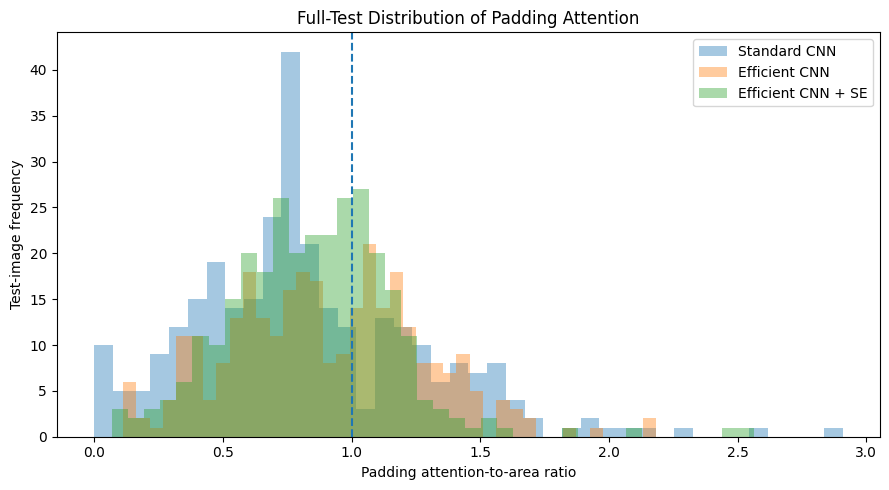


FULL-TEST GRAD-CAM PADDING ANALYSIS COMPLETE
Test images per model : 299
CNN models analysed   : 3
Total model-images    : 897

Standard CNN         | mean ratio=0.8289 | median=0.7720 | SD=0.4592
Efficient CNN        | mean ratio=0.9040 | median=0.8845 | SD=0.3773
Efficient CNN + SE   | mean ratio=0.8471 | median=0.8450 | SD=0.3267


In [30]:
# ============================================================
# 9.1 Full-Test Grad-CAM Padding-Attention Analysis
# ============================================================

import torch.nn.functional as F


# ------------------------------------------------------------
# CNN architectures only
# ------------------------------------------------------------

GRADCAM_MODELS = [
    "Standard CNN",
    "Efficient CNN",
    "Efficient CNN + SE",
]


# ------------------------------------------------------------
# Select one representative seed using VALIDATION ONLY
#
# Representative seed:
# validation Macro-F1 closest to the model's three-seed mean.
# ------------------------------------------------------------

representative_rows = []


for model_name in GRADCAM_MODELS:

    model_runs = (
        main_training_results_df[
            main_training_results_df[
                "Model"
            ]
            ==
            model_name
        ]
        .copy()
    )


    validation_mean = float(
        model_runs[
            "Validation_Macro_F1"
        ].mean()
    )


    model_runs[
        "Distance_to_Validation_Mean"
    ] = (
        model_runs[
            "Validation_Macro_F1"
        ]
        -
        validation_mean
    ).abs()


    selected_row = (
        model_runs
        .sort_values(
            [
                "Distance_to_Validation_Mean",
                "Seed",
            ]
        )
        .iloc[0]
    )


    representative_rows.append(
        {
            "Model":
                model_name,

            "Representative_Seed":
                int(
                    selected_row[
                        "Seed"
                    ]
                ),

            "Seed_Validation_Macro_F1":
                float(
                    selected_row[
                        "Validation_Macro_F1"
                    ]
                ),

            "Three_Seed_Validation_Mean":
                validation_mean,

            "Distance_to_Mean":
                float(
                    selected_row[
                        "Distance_to_Validation_Mean"
                    ]
                ),

            "Checkpoint":
                selected_row[
                    "Checkpoint"
                ],
        }
    )


gradcam_representatives_df = pd.DataFrame(
    representative_rows
)


show_table(
    gradcam_representatives_df[
        [
            "Model",
            "Representative_Seed",
            "Seed_Validation_Macro_F1",
            "Three_Seed_Validation_Mean",
            "Distance_to_Mean",
        ]
    ],
    caption=(
        "Validation-selected representative checkpoints "
        "used for Grad-CAM analysis."
    ),
    filename=(
        "gradcam_representative_checkpoints.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Target-layer selection
# ------------------------------------------------------------

def get_gradcam_target_layer(
    model,
    model_name,
):
    """
    Return the final convolutional operation before the final
    block's BatchNorm/ReLU stage.
    """

    if model_name == "Standard CNN":

        return model.block3.block[0]


    if model_name in {
        "Efficient CNN",
        "Efficient CNN + SE",
    }:

        return model.block3.pointwise


    raise ValueError(
        f"Grad-CAM is not defined for {model_name}."
    )


# ------------------------------------------------------------
# Lightweight Grad-CAM implementation
# ------------------------------------------------------------

class GradCAM:
    """
    Grad-CAM for one convolutional target layer.
    """

    def __init__(
        self,
        model,
        target_layer,
    ):

        self.model = model

        self.target_layer = target_layer

        self.activations = None

        self.gradients = None


        self.forward_handle = (
            target_layer.register_forward_hook(
                self._forward_hook
            )
        )


    def _save_gradient(
        self,
        gradient,
    ):

        self.gradients = (
            gradient
            .detach()
        )


    def _forward_hook(
        self,
        module,
        inputs,
        output,
    ):

        self.activations = output


        if output.requires_grad:

            output.register_hook(
                self._save_gradient
            )


    def generate(
        self,
        input_tensor,
        target_class,
    ):
        """
        Generate a normalised 2-D Grad-CAM map for one image.
        """

        self.model.zero_grad()


        self.gradients = None

        self.activations = None


        logits = self.model(
            input_tensor
        )


        score = logits[
            0,
            int(
                target_class
            ),
        ]


        score.backward()


        if (
            self.activations is None
            or
            self.gradients is None
        ):

            raise RuntimeError(
                "Grad-CAM hooks did not capture activations "
                "and gradients."
            )


        activations = (
            self.activations
            .detach()
        )


        gradients = (
            self.gradients
        )


        # Global-average gradient weights
        weights = gradients.mean(
            dim=(
                2,
                3,
            ),
            keepdim=True,
        )


        cam = (
            weights
            *
            activations
        ).sum(
            dim=1,
            keepdim=True,
        )


        cam = F.relu(
            cam
        )


        cam = F.interpolate(
            cam,
            size=(
                TARGET_SIZE,
                TARGET_SIZE,
            ),
            mode="bilinear",
            align_corners=False,
        )


        cam = (
            cam[
                0,
                0,
            ]
            .detach()
            .cpu()
            .numpy()
            .astype(
                np.float64
            )
        )


        # Scale to 0..1 for visual consistency.
        cam_min = float(
            cam.min()
        )

        cam_max = float(
            cam.max()
        )


        if (
            cam_max
            >
            cam_min
        ):

            cam = (
                cam
                -
                cam_min
            ) / (
                cam_max
                -
                cam_min
            )


        else:

            cam = np.zeros_like(
                cam
            )


        return (
            cam,
            logits.detach(),
        )


    def close(
        self
    ):

        self.forward_handle.remove()


# ------------------------------------------------------------
# Load a checkpoint for Grad-CAM
# ------------------------------------------------------------

def load_gradcam_model(
    model_name,
    seed,
    checkpoint_path,
):
    """
    Load one validation-selected frozen CNN checkpoint.
    """

    model = (
        MODEL_BUILDERS[
            model_name
        ]()
        .to(
            TRAINING_DEVICE
        )
    )


    checkpoint = torch.load(
        checkpoint_path,
        map_location=TRAINING_DEVICE,
    )


    if (
        isinstance(
            checkpoint,
            dict,
        )
        and
        "model_state_dict"
        in checkpoint
    ):

        state_dict = checkpoint[
            "model_state_dict"
        ]

    else:

        state_dict = checkpoint


    model.load_state_dict(
        state_dict
    )


    model.eval()


    return model


# ------------------------------------------------------------
# Full-test analysis
#
# Padding-attention fraction:
#     fraction of total positive Grad-CAM mass inside padding
#
# Padding-area fraction:
#     fraction of image pixels occupied by padding
#
# Attention-to-area ratio:
#
#     padding attention fraction
#     --------------------------
#       padding area fraction
#
# Ratio = 1:
# attention proportional to available area
#
# Ratio < 1:
# padding receives less attention than expected by area
#
# Ratio > 1:
# padding receives disproportionate attention
# ------------------------------------------------------------

gradcam_rows = []


for representative in (
    gradcam_representatives_df.itertuples()
):

    model_name = (
        representative.Model
    )

    seed = int(
        representative.Representative_Seed
    )

    checkpoint_path = Path(
        representative.Checkpoint
    )


    print(
        "\n"
        + "=" * 76
    )

    print(
        f"GRAD-CAM FULL TEST: "
        f"{model_name} | seed {seed}"
    )

    print(
        "=" * 76
    )


    model = load_gradcam_model(
        model_name=model_name,
        seed=seed,
        checkpoint_path=checkpoint_path,
    )


    target_layer = (
        get_gradcam_target_layer(
            model,
            model_name,
        )
    )


    gradcam = GradCAM(
        model,
        target_layer,
    )


    for image_number, row in enumerate(
        test_df.itertuples(),
        start=1,
    ):

        image_path = Path(
            row.path
        )


        true_class_name = (
            row.class_name
        )


        true_index = (
            CLASS_TO_INDEX[
                true_class_name
            ]
        )


        # ----------------------------------------------------
        # Original image + explicit letterbox mask
        # ----------------------------------------------------

        with Image.open(
            image_path
        ) as image:

            raw_image = (
                image
                .convert(
                    "RGB"
                )
            )


            _, padding_mask = (
                LETTERBOX.apply_with_mask(
                    raw_image
                )
            )


            input_tensor = (
                EVAL_TRANSFORM(
                    raw_image
                )
                .unsqueeze(
                    0
                )
                .to(
                    TRAINING_DEVICE
                )
            )


        # ----------------------------------------------------
        # First forward pass determines predicted class.
        # No gradients are required here.
        # ----------------------------------------------------

        with torch.no_grad():

            initial_logits = model(
                input_tensor
            )


            probabilities = torch.softmax(
                initial_logits,
                dim=1,
            )


            predicted_index = int(
                torch.argmax(
                    probabilities,
                    dim=1,
                ).item()
            )


            predicted_confidence = float(
                probabilities[
                    0,
                    predicted_index,
                ].item()
            )


        # ----------------------------------------------------
        # Grad-CAM for the predicted class
        # ----------------------------------------------------

        cam, _ = gradcam.generate(
            input_tensor=input_tensor,
            target_class=predicted_index,
        )


        # ----------------------------------------------------
        # Convert Grad-CAM intensity into attention mass
        # ----------------------------------------------------

        positive_mass = float(
            cam.sum()
        )


        if positive_mass > 0:

            attention_mass = (
                cam
                /
                positive_mass
            )

        else:

            attention_mass = (
                np.zeros_like(
                    cam,
                    dtype=np.float64,
                )
            )


        padding_boolean = (
            padding_mask
            ==
            1
        )


        padding_area_fraction = float(
            padding_boolean.mean()
        )


        padding_attention_fraction = float(
            attention_mass[
                padding_boolean
            ].sum()
        )


        if (
            padding_area_fraction
            >
            0
        ):

            attention_to_area_ratio = (
                padding_attention_fraction
                /
                padding_area_fraction
            )

        else:

            attention_to_area_ratio = (
                np.nan
            )


        gradcam_rows.append(
            {
                "Model":
                    model_name,

                "Seed":
                    seed,

                "Path":
                    str(
                        image_path
                    ),

                "True_Class":
                    true_class_name,

                "Predicted_Class":
                    CLASS_NAMES[
                        predicted_index
                    ],

                "Correct":
                    bool(
                        predicted_index
                        ==
                        true_index
                    ),

                "Predicted_Confidence":
                    predicted_confidence,

                "Padding_Area_Fraction":
                    padding_area_fraction,

                "Padding_Attention_Fraction":
                    padding_attention_fraction,

                "Attention_to_Area_Ratio":
                    float(
                        attention_to_area_ratio
                    )
                    if np.isfinite(
                        attention_to_area_ratio
                    )
                    else np.nan,

                "GradCAM_Total_Positive_Mass":
                    positive_mass,
            }
        )


        if (
            image_number % 50
            ==
            0
        ):

            print(
                f"Processed "
                f"{image_number}/"
                f"{len(test_df)}"
            )


    gradcam.close()


    del model


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Complete image-level results
# ------------------------------------------------------------

gradcam_full_test_df = pd.DataFrame(
    gradcam_rows
)


expected_rows = (
    len(
        test_df
    )
    *
    len(
        GRADCAM_MODELS
    )
)


assert (
    len(
        gradcam_full_test_df
    )
    ==
    expected_rows
), (
    "Full-test Grad-CAM analysis did not produce "
    "the expected number of rows."
)


gradcam_full_test_df.to_csv(
    OUTPUT_DIR
    /
    "gradcam_full_test_padding_attention.csv",
    index=False,
)


print(
    "\nGrad-CAM rows:",
    len(
        gradcam_full_test_df
    ),
    "/",
    expected_rows,
)


# ------------------------------------------------------------
# Overall statistics by model
# ------------------------------------------------------------

valid_gradcam_df = (
    gradcam_full_test_df[
        gradcam_full_test_df[
            "Attention_to_Area_Ratio"
        ]
        .notna()
    ]
    .copy()
)


gradcam_summary_df = (
    valid_gradcam_df
    .groupby(
        "Model",
        sort=False,
    )
    .agg(
        Images=(
            "Path",
            "count",
        ),

        Padding_Area_Mean=(
            "Padding_Area_Fraction",
            "mean",
        ),

        Padding_Attention_Mean=(
            "Padding_Attention_Fraction",
            "mean",
        ),

        Ratio_Mean=(
            "Attention_to_Area_Ratio",
            "mean",
        ),

        Ratio_Median=(
            "Attention_to_Area_Ratio",
            "median",
        ),

        Ratio_SD=(
            "Attention_to_Area_Ratio",
            "std",
        ),
    )
    .reset_index()
)


show_table(
    gradcam_summary_df,
    caption=(
        "Full-test Grad-CAM padding-attention statistics "
        "for the three convolutional architectures."
    ),
    filename=(
        "gradcam_full_test_summary.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Correct vs incorrect predictions
# ------------------------------------------------------------

gradcam_correctness_df = (
    valid_gradcam_df
    .groupby(
        [
            "Model",
            "Correct",
        ],
        sort=False,
    )
    .agg(
        Images=(
            "Path",
            "count",
        ),

        Ratio_Mean=(
            "Attention_to_Area_Ratio",
            "mean",
        ),

        Ratio_Median=(
            "Attention_to_Area_Ratio",
            "median",
        ),

        Ratio_SD=(
            "Attention_to_Area_Ratio",
            "std",
        ),
    )
    .reset_index()
)


gradcam_correctness_df[
    "Prediction_Group"
] = (
    gradcam_correctness_df[
        "Correct"
    ]
    .map(
        {
            True:
                "Correct",

            False:
                "Incorrect",
        }
    )
)


gradcam_correctness_df = (
    gradcam_correctness_df[
        [
            "Model",
            "Prediction_Group",
            "Images",
            "Ratio_Mean",
            "Ratio_Median",
            "Ratio_SD",
        ]
    ]
)


show_table(
    gradcam_correctness_df,
    caption=(
        "Padding attention-to-area ratio for correct "
        "and incorrect predictions."
    ),
    filename=(
        "gradcam_correct_vs_incorrect.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Distribution plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        9,
        5,
    )
)


for model_name in GRADCAM_MODELS:

    values = (
        valid_gradcam_df.loc[
            valid_gradcam_df[
                "Model"
            ]
            ==
            model_name,

            "Attention_to_Area_Ratio",
        ]
        .to_numpy()
    )


    ax.hist(
        values,
        bins=40,
        alpha=0.40,
        label=model_name,
    )


ax.axvline(
    1.0,
    linestyle="--",
)


ax.set_xlabel(
    "Padding attention-to-area ratio"
)

ax.set_ylabel(
    "Test-image frequency"
)

ax.set_title(
    "Full-Test Distribution of Padding Attention"
)

ax.legend()


fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Distribution of Grad-CAM padding attention-to-area "
        "ratios across the held-out test set."
    ),
    filename=(
        "gradcam_padding_attention_distribution.png"
    ),
)


# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 82
)

print(
    "FULL-TEST GRAD-CAM PADDING ANALYSIS COMPLETE"
)

print(
    "=" * 82
)


print(
    f"Test images per model : "
    f"{len(test_df)}"
)

print(
    f"CNN models analysed   : "
    f"{len(GRADCAM_MODELS)}"
)

print(
    f"Total model-images    : "
    f"{expected_rows}"
)

print()


for row in gradcam_summary_df.itertuples():

    print(
        f"{row.Model:20s} | "
        f"mean ratio="
        f"{row.Ratio_Mean:.4f} | "
        f"median="
        f"{row.Ratio_Median:.4f} | "
        f"SD="
        f"{row.Ratio_SD:.4f}"
    )


print(
    "=" * 82
)

Mean attention-to-area ratios were 0.8289, 0.9040 and 0.8471 for Standard CNN, Efficient CNN and Efficient CNN + SE. Where the CAM minimum exceeds zero the subtraction amplifies departures from 1.0 in either direction rather than biasing them downward, and that case's frequency was not measured. Padding is also not class-neutral: `Other` has median aspect ratio 0.607 against 1.354–1.517 elsewhere (Table 5), so its letterbox bands run vertically — a shape cue coinciding with its highest per-class F1. Single-checkpoint ratios preclude attributing differences to architecture.

### 9.2 Illustrative Grad-CAM Examples

Selected test images provide visual examples only; RQ5 is based on the full-test analysis in Section 9.1.



Table 62. Held-out images selected for illustrative Grad-CAM visualisation.


,Example_Label,True_Class,Standard_Predicted_Class,Standard_Confidence,Path
0,Correct — high confidence,Other,Other,1.0000,C:\Users\\Downloads\VTID2\other\PHOTO_201...
1,Correct — low confidence,SUV,SUV,0.3733,C:\Users\\Downloads\VTID2\suv\PHOTO_575.jpg
2,Hatchback misclassification,Hatchback,Sedan,0.9856,C:\Users\\Downloads\VTID2\hatchback\PHOTO...
3,SUV → Pickup error,SUV,Pickup,0.7908,C:\Users\\Downloads\VTID2\suv\PHOTO_166.jpg



Table 63. Predictions and padding-attention measurements for the four illustrative Grad-CAM examples.


,Example,Example_Label,Model,Seed,True_Class,Predicted_Class,Correct,Confidence,Padding_Area_Fraction,Padding_Attention_Fraction,Attention_to_Area_Ratio
0,1,Correct — high confidence,Standard CNN,42,Other,Other,True,1.0000,0.1042,0.0862,0.8276
1,2,Correct — low confidence,Standard CNN,42,SUV,SUV,True,0.3733,0.3333,0.0980,0.2939
2,3,Hatchback misclassification,Standard CNN,42,Hatchback,Sedan,False,0.9856,0.4896,0.4285,0.8753
3,4,SUV → Pickup error,Standard CNN,42,SUV,Pickup,False,0.7908,0.3333,0.2738,0.8213
4,1,Correct — high confidence,Efficient CNN,123,Other,Other,True,1.0000,0.1042,0.0846,0.8118
5,2,Correct — low confidence,Efficient CNN,123,SUV,SUV,True,0.6334,0.3333,0.0391,0.1174
6,3,Hatchback misclassification,Efficient CNN,123,Hatchback,Sedan,False,0.9811,0.4896,0.4396,0.8978
7,4,SUV → Pickup error,Efficient CNN,123,SUV,Pickup,False,0.9177,0.3333,0.1929,0.5787
8,1,Correct — high confidence,Efficient CNN + SE,123,Other,Other,True,1.0000,0.1042,0.0749,0.7194
9,2,Correct — low confidence,Efficient CNN + SE,123,SUV,SUV,True,0.4493,0.3333,0.1075,0.3224



Figure 12. Illustrative Grad-CAM overlays for four held-out images across the three convolutional architectures.


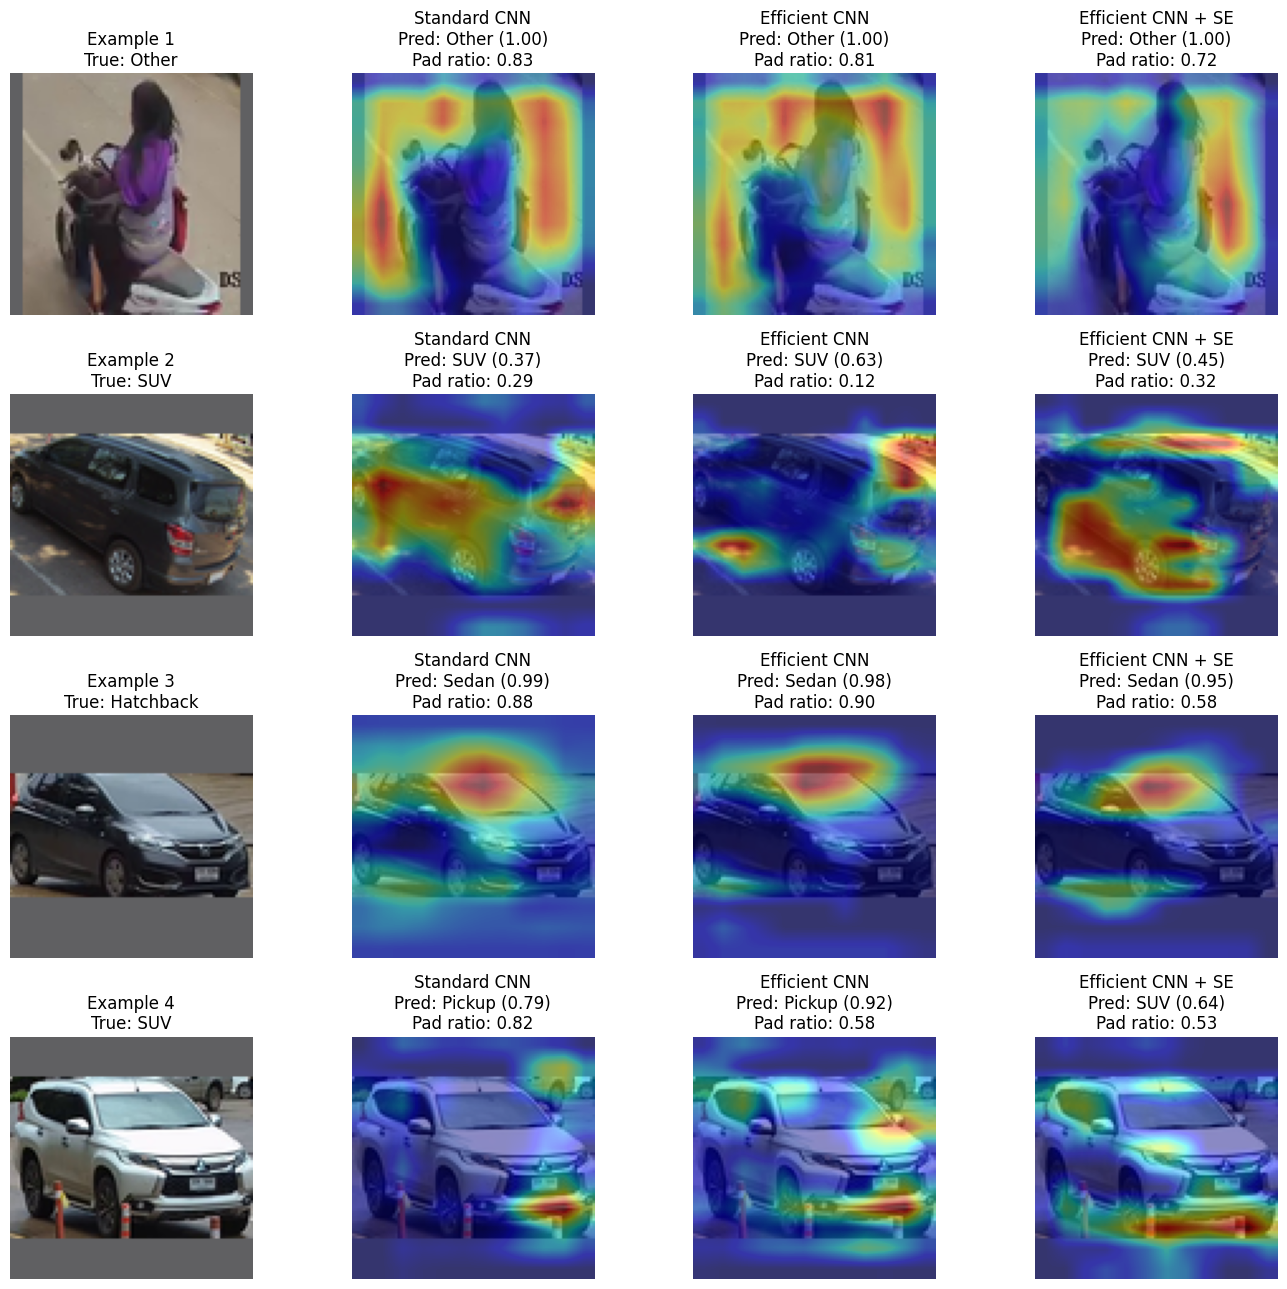


ILLUSTRATIVE GRAD-CAM EXAMPLES COMPLETE
Example 1: Correct — high confidence | true=Other | path=PHOTO_201.jpg
Example 2: Correct — low confidence | true=SUV | path=PHOTO_575.jpg
Example 3: Hatchback misclassification | true=Hatchback | path=PHOTO_147.jpg
Example 4: SUV → Pickup error | true=SUV | path=PHOTO_166.jpg

These examples are illustrative only; the full-test statistics in Section 9.1 provide the quantitative evidence.


In [31]:
# ============================================================
# 9.2 Four Illustrative Grad-CAM Examples
# ============================================================

# ------------------------------------------------------------
# Use the validation-selected Standard-CNN representative
# checkpoint only to choose four reproducible example images.
#
# The same four images are then visualised for all three CNNs.
# ------------------------------------------------------------

standard_representative_seed = int(
    gradcam_representatives_df.loc[
        gradcam_representatives_df["Model"]
        ==
        "Standard CNN",
        "Representative_Seed",
    ].iloc[0]
)


standard_example_pool = (
    gradcam_full_test_df[
        (
            gradcam_full_test_df["Model"]
            ==
            "Standard CNN"
        )
        &
        (
            gradcam_full_test_df["Seed"]
            ==
            standard_representative_seed
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Deterministic example selection
# ------------------------------------------------------------

selected_examples = []

selected_paths = set()


def add_example(
    candidate_df,
    label,
    sort_column="Predicted_Confidence",
    ascending=False,
):
    """
    Add the first unused image from a ranked candidate set.
    """

    if len(candidate_df) == 0:
        return False


    ranked = (
        candidate_df
        .sort_values(
            sort_column,
            ascending=ascending,
        )
    )


    for row in ranked.itertuples():

        if row.Path not in selected_paths:

            selected_examples.append(
                {
                    "Example_Label":
                        label,

                    "Path":
                        row.Path,

                    "True_Class":
                        row.True_Class,

                    "Standard_Predicted_Class":
                        row.Predicted_Class,

                    "Standard_Confidence":
                        float(
                            row.Predicted_Confidence
                        ),
                }
            )


            selected_paths.add(
                row.Path
            )

            return True


    return False


# ------------------------------------------------------------
# Example 1:
# highest-confidence correct Standard-CNN prediction
# ------------------------------------------------------------

correct_rows = (
    standard_example_pool[
        standard_example_pool[
            "Correct"
        ]
        ==
        True
    ]
)


add_example(
    candidate_df=correct_rows,
    label="Correct — high confidence",
    sort_column="Predicted_Confidence",
    ascending=False,
)


# ------------------------------------------------------------
# Example 2:
# lowest-confidence correct Standard-CNN prediction
# ------------------------------------------------------------

add_example(
    candidate_df=correct_rows,
    label="Correct — low confidence",
    sort_column="Predicted_Confidence",
    ascending=True,
)


# ------------------------------------------------------------
# Example 3:
# confident Hatchback misclassification
# ------------------------------------------------------------

hatchback_errors = (
    standard_example_pool[
        (
            standard_example_pool[
                "True_Class"
            ]
            ==
            "Hatchback"
        )
        &
        (
            standard_example_pool[
                "Correct"
            ]
            ==
            False
        )
    ]
)


added_hatchback = add_example(
    candidate_df=hatchback_errors,
    label="Hatchback misclassification",
    sort_column="Predicted_Confidence",
    ascending=False,
)


# Fallback if the representative Standard CNN has no
# Hatchback error.
if not added_hatchback:

    general_errors = (
        standard_example_pool[
            standard_example_pool[
                "Correct"
            ]
            ==
            False
        ]
    )


    add_example(
        candidate_df=general_errors,
        label="Representative misclassification",
        sort_column="Predicted_Confidence",
        ascending=False,
    )


# ------------------------------------------------------------
# Example 4:
# SUV -> Pickup if available
# ------------------------------------------------------------

suv_to_pickup_errors = (
    standard_example_pool[
        (
            standard_example_pool[
                "True_Class"
            ]
            ==
            "SUV"
        )
        &
        (
            standard_example_pool[
                "Predicted_Class"
            ]
            ==
            "Pickup"
        )
    ]
)


added_suv_pickup = add_example(
    candidate_df=suv_to_pickup_errors,
    label="SUV → Pickup error",
    sort_column="Predicted_Confidence",
    ascending=False,
)


# Fallback:
# any remaining SUV error
if not added_suv_pickup:

    suv_errors = (
        standard_example_pool[
            (
                standard_example_pool[
                    "True_Class"
                ]
                ==
                "SUV"
            )
            &
            (
                standard_example_pool[
                    "Correct"
                ]
                ==
                False
            )
        ]
    )


    added_suv = add_example(
        candidate_df=suv_errors,
        label="SUV misclassification",
        sort_column="Predicted_Confidence",
        ascending=False,
    )


    # Final fallback:
    # any remaining misclassified image
    if not added_suv:

        general_errors = (
            standard_example_pool[
                standard_example_pool[
                    "Correct"
                ]
                ==
                False
            ]
        )


        add_example(
            candidate_df=general_errors,
            label="Additional misclassification",
            sort_column="Predicted_Confidence",
            ascending=False,
        )


# ------------------------------------------------------------
# Integrity check
# ------------------------------------------------------------

if len(
    selected_examples
) != 4:

    raise RuntimeError(
        "Could not obtain four unique illustrative examples."
    )


illustrative_examples_df = pd.DataFrame(
    selected_examples
)


show_table(
    illustrative_examples_df[
        [
            "Example_Label",
            "True_Class",
            "Standard_Predicted_Class",
            "Standard_Confidence",
            "Path",
        ]
    ],
    caption=(
        "Held-out images selected for illustrative "
        "Grad-CAM visualisation."
    ),
    filename=(
        "gradcam_illustrative_examples.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Helper: unnormalised letterboxed image for display
# ------------------------------------------------------------

def prepare_gradcam_display_image(
    image_path,
):
    """
    Return the neutral-letterboxed RGB image and padding mask.
    """

    with Image.open(
        image_path
    ) as image:

        raw_image = image.convert(
            "RGB"
        )


        letterboxed_image, padding_mask = (
            LETTERBOX.apply_with_mask(
                raw_image
            )
        )


    return (
        np.asarray(
            letterboxed_image
        ),
        padding_mask,
    )


# ------------------------------------------------------------
# Generate Grad-CAM information for the four examples
# across all three CNN architectures.
# ------------------------------------------------------------

illustrative_gradcam_rows = []

illustrative_cam_store = {}


for representative in (
    gradcam_representatives_df.itertuples()
):

    model_name = (
        representative.Model
    )


    seed = int(
        representative.Representative_Seed
    )


    checkpoint_path = Path(
        representative.Checkpoint
    )


    model = load_gradcam_model(
        model_name=model_name,
        seed=seed,
        checkpoint_path=checkpoint_path,
    )


    target_layer = get_gradcam_target_layer(
        model,
        model_name,
    )


    gradcam = GradCAM(
        model,
        target_layer,
    )


    for example_number, example in enumerate(
        selected_examples,
        start=1,
    ):

        image_path = Path(
            example[
                "Path"
            ]
        )


        true_class = (
            example[
                "True_Class"
            ]
        )


        true_index = (
            CLASS_TO_INDEX[
                true_class
            ]
        )


        with Image.open(
            image_path
        ) as image:

            raw_image = image.convert(
                "RGB"
            )


            display_image, padding_mask = (
                LETTERBOX.apply_with_mask(
                    raw_image
                )
            )


            input_tensor = (
                EVAL_TRANSFORM(
                    raw_image
                )
                .unsqueeze(
                    0
                )
                .to(
                    TRAINING_DEVICE
                )
            )


        # ----------------------------------------------------
        # Predicted class
        # ----------------------------------------------------

        with torch.no_grad():

            logits = model(
                input_tensor
            )


            probabilities = torch.softmax(
                logits,
                dim=1,
            )


            predicted_index = int(
                torch.argmax(
                    probabilities,
                    dim=1,
                ).item()
            )


            confidence = float(
                probabilities[
                    0,
                    predicted_index,
                ].item()
            )


        # ----------------------------------------------------
        # Grad-CAM for predicted class
        # ----------------------------------------------------

        cam, _ = gradcam.generate(
            input_tensor=input_tensor,
            target_class=predicted_index,
        )


        positive_mass = float(
            cam.sum()
        )


        if positive_mass > 0:

            attention_mass = (
                cam
                /
                positive_mass
            )

        else:

            attention_mass = (
                np.zeros_like(
                    cam,
                    dtype=np.float64,
                )
            )


        padding_boolean = (
            padding_mask
            ==
            1
        )


        padding_area_fraction = float(
            padding_boolean.mean()
        )


        padding_attention_fraction = float(
            attention_mass[
                padding_boolean
            ].sum()
        )


        if padding_area_fraction > 0:

            ratio = (
                padding_attention_fraction
                /
                padding_area_fraction
            )

        else:

            ratio = np.nan


        # ----------------------------------------------------
        # Store image and CAM
        # ----------------------------------------------------

        illustrative_cam_store[
            (
                example_number,
                model_name,
            )
        ] = {
            "image":
                np.asarray(
                    display_image
                ),

            "cam":
                cam,

            "padding_mask":
                padding_mask,
        }


        illustrative_gradcam_rows.append(
            {
                "Example":
                    example_number,

                "Example_Label":
                    example[
                        "Example_Label"
                    ],

                "Model":
                    model_name,

                "Seed":
                    seed,

                "True_Class":
                    true_class,

                "Predicted_Class":
                    CLASS_NAMES[
                        predicted_index
                    ],

                "Correct":
                    bool(
                        predicted_index
                        ==
                        true_index
                    ),

                "Confidence":
                    confidence,

                "Padding_Area_Fraction":
                    padding_area_fraction,

                "Padding_Attention_Fraction":
                    padding_attention_fraction,

                "Attention_to_Area_Ratio":
                    float(
                        ratio
                    )
                    if np.isfinite(
                        ratio
                    )
                    else np.nan,
            }
        )


    gradcam.close()


    del model


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


illustrative_gradcam_df = pd.DataFrame(
    illustrative_gradcam_rows
)


# ------------------------------------------------------------
# Numerical illustration table
# ------------------------------------------------------------

show_table(
    illustrative_gradcam_df,
    caption=(
        "Predictions and padding-attention measurements "
        "for the four illustrative Grad-CAM examples."
    ),
    filename=(
        "gradcam_illustrative_example_results.csv"
    ),
    decimals=4,
)


# ------------------------------------------------------------
# Grad-CAM figure
#
# Rows    = four examples
# Columns = original + three CNNs
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    4,
    figsize=(
        14,
        13,
    ),
)


for example_number, example in enumerate(
    selected_examples,
    start=1,
):

    row_index = (
        example_number
        -
        1
    )


    # --------------------------------------------------------
    # Original letterboxed image
    # --------------------------------------------------------

    first_model_data = (
        illustrative_cam_store[
            (
                example_number,
                GRADCAM_MODELS[0],
            )
        ]
    )


    axes[
        row_index,
        0,
    ].imshow(
        first_model_data[
            "image"
        ]
    )


    axes[
        row_index,
        0,
    ].set_title(
        (
            f"Example {example_number}\n"
            f"True: {example['True_Class']}"
        )
    )


    axes[
        row_index,
        0,
    ].axis(
        "off"
    )


    # --------------------------------------------------------
    # Three CNN Grad-CAM overlays
    # --------------------------------------------------------

    for model_column, model_name in enumerate(
        GRADCAM_MODELS,
        start=1,
    ):

        stored = (
            illustrative_cam_store[
                (
                    example_number,
                    model_name,
                )
            ]
        )


        result_row = (
            illustrative_gradcam_df[
                (
                    illustrative_gradcam_df[
                        "Example"
                    ]
                    ==
                    example_number
                )
                &
                (
                    illustrative_gradcam_df[
                        "Model"
                    ]
                    ==
                    model_name
                )
            ]
            .iloc[0]
        )


        axis = axes[
            row_index,
            model_column,
        ]


        axis.imshow(
            stored[
                "image"
            ]
        )


        axis.imshow(
            stored[
                "cam"
            ],
            alpha=0.45,
            cmap="jet",
            vmin=0,
            vmax=1,
        )


        axis.set_title(
            (
                f"{model_name}\n"
                f"Pred: "
                f"{result_row['Predicted_Class']} "
                f"({result_row['Confidence']:.2f})\n"
                f"Pad ratio: "
                f"{result_row['Attention_to_Area_Ratio']:.2f}"
            )
        )


        axis.axis(
            "off"
        )


fig.tight_layout()


show_figure(
    fig,
    caption=(
        "Illustrative Grad-CAM overlays for four held-out "
        "images across the three convolutional architectures."
    ),
    filename=(
        "gradcam_four_illustrative_examples.png"
    ),
)


# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------

print(
    "\n"
    + "=" * 82
)

print(
    "ILLUSTRATIVE GRAD-CAM EXAMPLES COMPLETE"
)

print(
    "=" * 82
)


for example_number, example in enumerate(
    selected_examples,
    start=1,
):

    print(
        f"Example {example_number}: "
        f"{example['Example_Label']} | "
        f"true={example['True_Class']} | "
        f"path={Path(example['Path']).name}"
    )


print(
    "\nThese examples are illustrative only; "
    "the full-test statistics in Section 9.1 "
    "provide the quantitative evidence."
)

print(
    "=" * 82
)

For the Hatchback error, ratios were 0.8753, 0.8978 and 0.5847; for the SUV example, 0.8213, 0.5787 and 0.5305, where SE alone predicted SUV correctly. All ratios fell below 1.0, so no simple association between padding attention and error is supported.

## 10. Conclusion

**RQ1:** The Standard CNN outperformed the MLP, though unequal capacity prevents attributing this to spatial inductive bias alone.

**RQ2:** Conventional evaluation scored higher, but as a non-equivalent contrast (Section 4.8) this is not a leakage estimate.

**RQ3:** The Efficient CNN cut parameters and MACs sharply at small mean cost, but the bootstrap interval crossed zero, so retention cannot be concluded.

**RQ4:** SE did not improve mean test performance and increased latency.

**RQ5:** Padding attention stayed below the geometric null, and padding geometry encodes aspect ratio — an informative cue, not a neutral artefact.

## 11. Ethics and Responsible AI

SUV performance is the main operational concern: F1 was 0.5943 for Efficient CNN and 0.5976 for Efficient CNN + SE, with only 20 SUV test images. If vehicle type feeds lane restrictions, tolling, prioritisation or enforcement review, an SUV misclassified as Pickup or another class could create unequal false alerts or missed events. These results are therefore insufficient for autonomous enforcement; deployment would require class-specific monitoring, independent sensing evidence and human review.

VTID2 was collected through fixed CCTV at one university gate, with daytime-only capture and single-location collection among the data article's stated limitations, so performance cannot be assumed to transfer across cameras, weather or traffic composition. Local validation, drift monitoring and access controls would be required. Padding geometry encodes aspect ratio, so cues drawn from it may not transfer when deployment crops come from detectors at different scales. Licensing permits reuse but does not establish consent for operational surveillance.

## 12. Reflection

The project changed my focus from maximising accuracy to protecting evaluation validity. Exact duplicates and related frames showed that strong scores can result from partition design rather than genuine generalisation, so I learned to audit relationships before splitting and to keep test data isolated from model selection.

I also learned that efficiency is multidimensional: fewer parameters and MACs did not translate proportionally into lower latency, and SE did not automatically improve the performance–efficiency trade-off. Multiple seeds and bootstrap uncertainty made single-run rankings less persuasive. Grad-CAM also showed the limitation of descriptive interpretability, motivating a padding-masked pooling ablation that tests whether letterbox padding affects feature aggregation directly. Future work should evaluate class weighting and broader camera domains.

## 13. References

Boonsirisumpun, N. and Surinta, O. (2023) *Vehicle Type Image Dataset (Version 2): VTID2*. Mendeley Data, Version 3. Available at: https://doi.org/10.17632/htsngg9tpc.3

Boonsirisumpun, N., Okafor, E. and Surinta, O. (2024) ‘Vehicle image datasets for image classification’, *Data in Brief*, 53, article 110133. Available at: https://doi.org/10.1016/j.dib.2024.110133

Efron, B. and Tibshirani, R. (1986) ‘Bootstrap methods for standard errors, confidence intervals, and other measures of statistical accuracy’, *Statistical Science*, 1(1), pp. 54–75. Available at: https://doi.org/10.1214/ss/1177013815

Howard, A.G., Zhu, M., Chen, B., Kalenichenko, D., Wang, W., Weyand, T., Andreetto, M. and Adam, H. (2017) ‘MobileNets: Efficient convolutional neural networks for mobile vision applications’, *arXiv:1704.04861* [Preprint]. Available at: https://doi.org/10.48550/arXiv.1704.04861

Hu, J., Shen, L. and Sun, G. (2018) ‘Squeeze-and-excitation networks’, in *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, pp. 7132–7141. Available at: https://doi.org/10.1109/CVPR.2018.00745

Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012) ‘Leakage in data mining: Formulation, detection, and avoidance’, *ACM Transactions on Knowledge Discovery from Data*, 6(4), article 15, pp. 1–21. Available at: https://doi.org/10.1145/2382577.2382579

LeCun, Y., Bottou, L., Bengio, Y. and Haffner, P. (1998) ‘Gradient-based learning applied to document recognition’, *Proceedings of the IEEE*, 86(11), pp. 2278–2324. Available at: https://doi.org/10.1109/5.726791

Loshchilov, I. and Hutter, F. (2019) ‘Decoupled weight decay regularization’, in *7th International Conference on Learning Representations (ICLR 2019)*, New Orleans, LA, USA, 6–9 May.

Selvaraju, R.R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. and Batra, D. (2017) ‘Grad-CAM: Visual explanations from deep networks via gradient-based localization’, in *Proceedings of the IEEE International Conference on Computer Vision (ICCV)*, pp. 618–626. Available at: https://doi.org/10.1109/ICCV.2017.74

Shorten, C. and Khoshgoftaar, T.M. (2019) ‘A survey on image data augmentation for deep learning’, *Journal of Big Data*, 6, article 60. Available at: https://doi.org/10.1186/s40537-019-0197-0

Sokolova, M. and Lapalme, G. (2009) ‘A systematic analysis of performance measures for classification tasks’, *Information Processing & Management*, 45(4), pp. 427–437. Available at: https://doi.org/10.1016/j.ipm.2009.03.002

Wang, Z., Bovik, A.C., Sheikh, H.R. and Simoncelli, E.P. (2004) ‘Image quality assessment: From error visibility to structural similarity’, *IEEE Transactions on Image Processing*, 13(4), pp. 600–612. Available at: https://doi.org/10.1109/TIP.2003.819861


## Appendix A — Generative AI Use Declaration

**Tool:** ChatGPT (OpenAI)
**URL:** https://chatgpt.com/
**Period of use:** September 2026

Generative AI was used as a supporting tool for selected coding and technical review tasks. Relevant outputs were reviewed, tested, and adapted where necessary before use.

**The table below records material uses of Generative AI during the development.**

| Date and time (UAE)      | Query / purpose                                            | Verification                                         |
| ------------------------ | ---------------------------------------------------------- | ---------------------------------------------------- |
| 8 September 2026, 17:00  | Support with selected Python/PyTorch implementation tasks. | Suggestions were reviewed and verified before use.   |
| 10 September 2026, 16:30 | Support with selected implementation and debugging tasks.  | Suggestions were tested and adapted where necessary. |
| 15 September 2026, 21:00 | Review of dataset-loading and initial-inspection code.     | The code was executed and verified before inclusion. |

The final submission was reviewed by the author.
